# DATA ANALYSIS

## A. LIBRERÍAS

In [1]:
# Matplotlib: permitir hacer zoom y desplazamiento en las gráficas. Alternativa por defecto: %matplotlib inline
%matplotlib widget

# Librerías básicas procesado de datos
import os
import glob
import pandas as pd
import numpy as np

# Librerías para análisis de datos
from statsmodels.tsa.seasonal import seasonal_decompose
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
from scipy.signal import welch
from numpy.fft import rfft, rfftfreq
from scipy.signal import correlate

# Librerías para visualización de gráficas
import matplotlib.pyplot as plt
import seaborn as sns
import matplotlib.cm as cm
import matplotlib.patches as mpatches
import folium
from folium.plugins import HeatMap
from IPython.display import display
from folium.plugins import TimestampedGeoJson
from folium.plugins import HeatMapWithTime

## B. ANÁLISIS EXPLORATORIO (EDA)

### B1. Visualización gráfica de las variables

#### B1.1 Glucosa y ritmo cardiaco

In [2]:
def graficar_glucosa_hr_trusted(
    archivo_master,
    output_folder,
    titulo=None,
    sombrear_ejercicio=True,
    sombrear_postejercicio_horas=8,
    figsize=(10, 6)
):
    """
    Grafica glucosa, heart_rate y heart_rate_gps de un archivo trusted, filtrando ceros y NaNs,
    y sombreando los bloques continuos de ejercicio (gris) y el post-ejercicio (gris claro).
    El nivel cero de ambos ejes queda alineado.

    Args:
        archivo_master (str): Ruta al archivo trusted del usuario.
        output_folder (str): Carpeta donde guardar la imagen.
        titulo (str, opcional): Título del gráfico. Si None, usa el nombre del archivo.
        sombrear_ejercicio (bool, opcional): Si True, añade sombreado en periodos de ejercicio.
        sombrear_postejercicio_horas (int, opcional): Horas a sombrear tras cada bloque de ejercicio.
        figsize (tuple, opcional): Tamaño de la figura.

    Returns:
        output_path (str): Ruta de la imagen guardada.
    """
    import matplotlib.patches as mpatches

    master = pd.read_csv(archivo_master, parse_dates=['time'])
    for col in ['glucose', 'heart_rate', 'heart_rate_gps']:
        if col in master.columns:
            master[col] = master[col].astype(float)

    fig, ax1 = plt.subplots(figsize=figsize)

    # Sombrear bloques de ejercicio y post-ejercicio, y guardar handles para la leyenda
    legend_handles = []
    if sombrear_ejercicio and 'exercise' in master.columns:
        master = master.sort_values('time')
        mask = (master['exercise'] == 1)
        mask_shift = mask.shift(1, fill_value=False)
        start_blocks = master['time'][(mask) & (~mask_shift)].reset_index(drop=True)
        end_blocks = master['time'][(mask_shift) & (~mask)].reset_index(drop=True)
        if len(end_blocks) < len(start_blocks):
            end_blocks = pd.concat([end_blocks, pd.Series(master['time'].iloc[-1:])]).reset_index(drop=True)
        for start, end in zip(start_blocks, end_blocks):
            ax1.axvspan(start, end, color='gray', alpha=0.2)
            post_end = end + pd.Timedelta(hours=sombrear_postejercicio_horas)
            ax1.axvspan(end, post_end, color='lightgray', alpha=0.15)
        legend_handles.append(mpatches.Patch(color='gray', alpha=0.2, label='Ejercicio'))
        legend_handles.append(mpatches.Patch(color='lightgray', alpha=0.15, label=f'Post-ejercicio: {sombrear_postejercicio_horas}h'))

    # Glucosa (sin ceros ni NaN)
    glucose_min, glucose_max = None, None
    if 'glucose' in master.columns:
        glucose_filtered = master[(master['glucose'] != 0) & (~master['glucose'].isna())]
        if not glucose_filtered.empty:
            line_glucose, = ax1.plot(glucose_filtered['time'], glucose_filtered['glucose'], color='tab:blue', label='Glucosa')
            ax1.tick_params(axis='y', labelcolor='tab:blue')
            glucose_min = glucose_filtered['glucose'].min()
            glucose_max = glucose_filtered['glucose'].max()

    ax1.set_xlabel('Tiempo')

    # Heart Rate y Heart Rate GPS (sin ceros ni NaN)
    ax2 = ax1.twinx()
    lines_hr = []
    hr_min, hr_max = None, None
    if 'heart_rate' in master.columns:
        heart_rate_filtered = master[(master['heart_rate'] != 0) & (~master['heart_rate'].isna())]
        if not heart_rate_filtered.empty:
            line_hr, = ax2.plot(heart_rate_filtered['time'], heart_rate_filtered['heart_rate'], color='tab:red', alpha=0.6, label='Heart Rate')
            lines_hr.append(line_hr)
            hr_min = heart_rate_filtered['heart_rate'].min()
            hr_max = heart_rate_filtered['heart_rate'].max()
    if 'heart_rate_gps' in master.columns:
        heart_rate_gps_filtered = master[(master['heart_rate_gps'] != 0) & (~master['heart_rate_gps'].isna())]
        if not heart_rate_gps_filtered.empty:
            line_hrgps, = ax2.plot(heart_rate_gps_filtered['time'], heart_rate_gps_filtered['heart_rate_gps'], color='orange', alpha=0.6, linestyle='dashed', label='Heart Rate GPS')
            lines_hr.append(line_hrgps)
            if hr_min is None or heart_rate_gps_filtered['heart_rate_gps'].min() < hr_min:
                hr_min = heart_rate_gps_filtered['heart_rate_gps'].min()
            if hr_max is None or heart_rate_gps_filtered['heart_rate_gps'].max() > hr_max:
                hr_max = heart_rate_gps_filtered['heart_rate_gps'].max()
    ax2.set_ylabel('Heart Rate', color='tab:red')
    ax2.tick_params(axis='y', labelcolor='tab:red')

    # SINCRONIZAR CERO Y AÑADIR MARGEN SUPERIOR
    # Calcula el mínimo común para ambos ejes
    y1_min = min(0, glucose_min) if glucose_min is not None else 0
    y2_min = min(0, hr_min) if hr_min is not None else 0
    common_min = min(y1_min, y2_min)

    # Añadir margen superior
    margin_factor = 1.10
    y1_max = glucose_max * margin_factor if glucose_max is not None else 1
    y2_max = hr_max * margin_factor if hr_max is not None else 1
    common_max = max(y1_max, y2_max)

    #ax1.set_ylim(common_min, y1_max)
    #ax2.set_ylim(common_min, y2_max)
    # Forzar misma escala visual:
    ax1.set_ylim(common_min, common_max)
    ax2.set_ylim(common_min, common_max)

    # Leyenda combinada
    lines1, labels1 = ax1.get_legend_handles_labels()
    lines2, labels2 = ax2.get_legend_handles_labels()
    handles = lines1 + lines_hr + legend_handles
    labels = labels1 + labels2 + [h.get_label() for h in legend_handles]
    ax2.legend(handles, labels, loc='upper left')

    # Título con el nombre del archivo s(i no se pasa explícito))
    if titulo is None:
        nombre_archivo = os.path.basename(archivo_master).replace('.csv', '')
        titulo = f"{nombre_archivo} - Glucosa, Heart Rate y Heart Rate GPS vs Tiempo"
    plt.title(titulo)
    fig.tight_layout()

    # Crear carpeta de salida (si no existe)
    os.makedirs(output_folder, exist_ok=True)
    output_filename = os.path.splitext(os.path.basename(archivo_master))[0] + '.png'
    output_path = os.path.join(output_folder, output_filename)
    plt.savefig(output_path)
    print(f"Imagen guardada en: {output_path}")
    return output_path


Imagen guardada en: Analysis/Gráficas glucosa y HR\CIS-UCM0005P.png
Imagen guardada en: Analysis/Gráficas glucosa y HR\CIS-UCM0006P.png
Imagen guardada en: Analysis/Gráficas glucosa y HR\CIS-UCM0007P.png
Imagen guardada en: Analysis/Gráficas glucosa y HR\U10.png
Imagen guardada en: Analysis/Gráficas glucosa y HR\U12.png


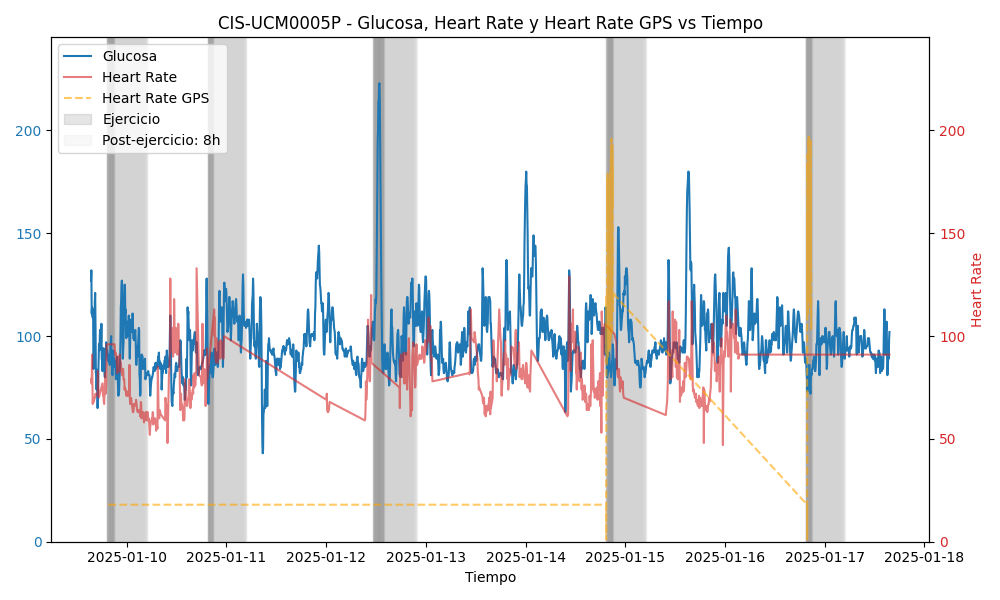

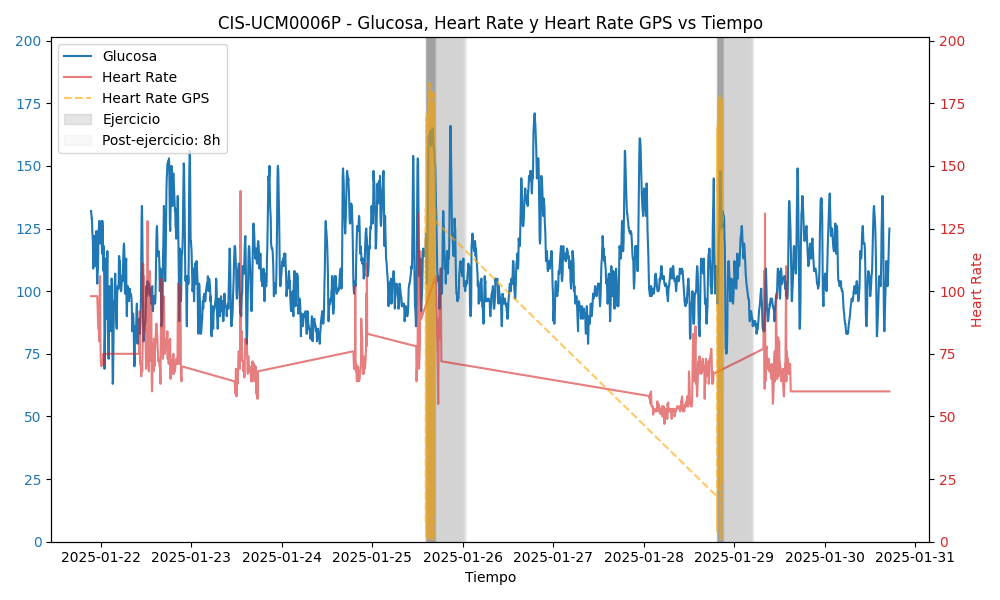

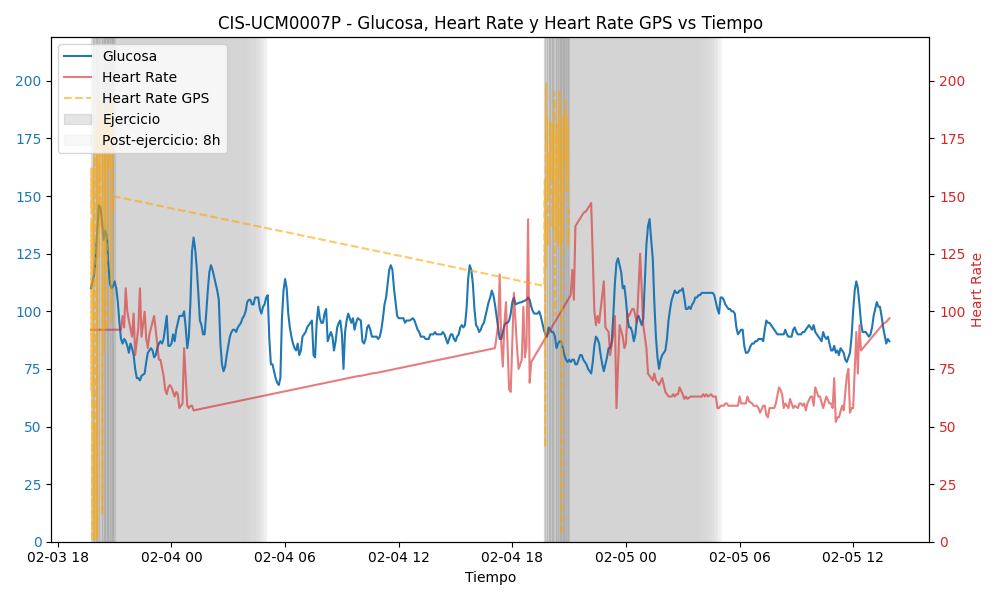

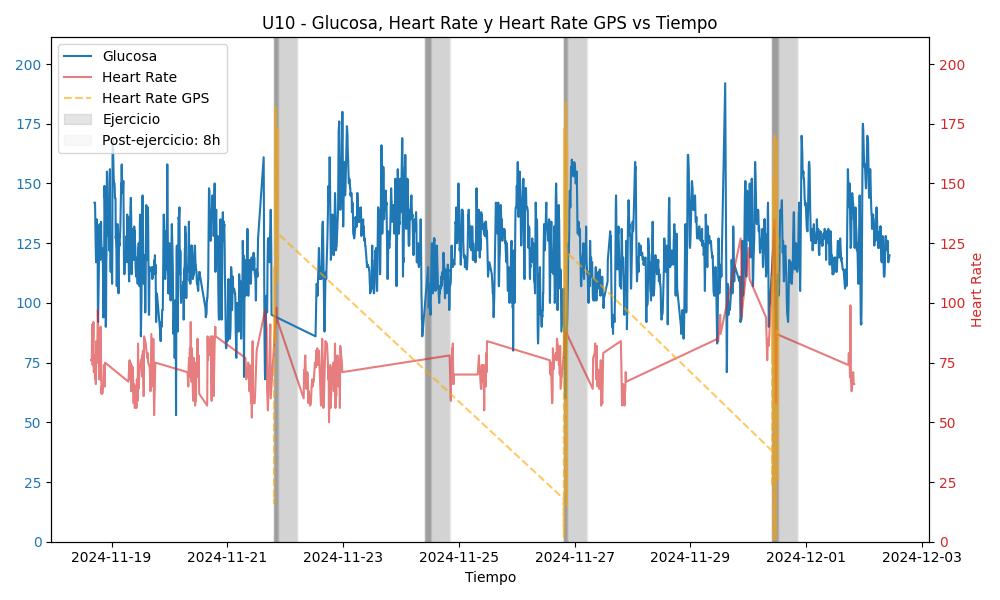

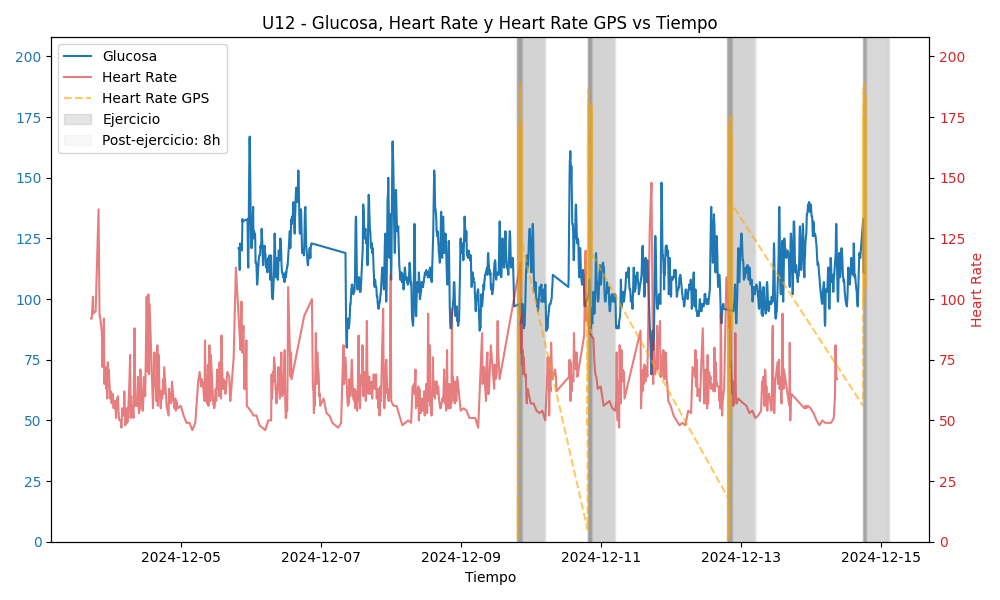

In [3]:
def main(folder_path, output_folder):
    """
    Busca y procesa todos los archivos CSV en una carpeta, graficando y guardando los datos de glucosa de cada uno.

    Args:
        folder_path (str): Ruta a la carpeta donde se encuentran los archivos CSV.
        output_folder (str): Carpeta donde se guardarán las imágenes generadas.

    Returns:
        None. Guarda un archivo de imagen (.png) por cada CSV procesado.
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            graficar_glucosa_hr_trusted(file_path, output_folder)

if __name__ == "__main__":
    carpeta = 'Data/Trusted/Completos'
    salida = 'Analysis/Gráficas glucosa y HR'
    main(carpeta, salida)



In [4]:
plt.close('all')

##### B1.1.2 Scatter plot / Gráfico de dispersión

Como sólo se grafican los datos coincidentes en el mismo instante temporal, se reduce la cantidad de muestras visibles, ya que debido a la granularidad de las muestras de datos del GPS es difícil que haya coincidencia exacta en hora con los datos de glucosa.

No debemos considerar graficar archivos que tengas variables con granularidad aumentada, dado que se verá claramente la alteración en el gráfico y falseará nuestra impresión.

Por ello tal vez graficar los datos agrupados cada 5 minutos (usando el método de la media) sea lo más informativo: sin meter tendencias lineales por interpolaciones o forward-fill y maximizando la coincidencia temporal.

In [5]:
def graficar_dispersion_multiple(df, y_var, x_vars, filename, title_suffix=''):
    """
    Grafica y guarda la dispersión de una variable dependiente (y_var) frente a varias independientes (x_vars).

    Args:
        df (pd.DataFrame): DataFrame que contiene las columnas necesarias.
        y_var (str): Nombre de la variable eje y.
        x_vars (list of str): Lista de nombres de variables eje x.
        filename (str): Ruta y nombre del archivo de salida.
        title_suffix (str): Sufijo para el título del gráfico.

    Returns:
        None. Guarda la imagen.
    """
    plt.figure(figsize=(10, 6))
    colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']
    plotted = False

    for i, x_var in enumerate(x_vars):
        if x_var in df.columns and y_var in df.columns:
            df_plot = df[[x_var, y_var]].dropna()
            if not df_plot.empty:
                plt.scatter(df_plot[x_var], df_plot[y_var], alpha=0.5, label=x_var, color=colors[i % len(colors)])
                plotted = True

    if not plotted:
        print(f"[ADVERTENCIA] No hay datos válidos para graficar en {filename}.")
        return

    plt.title(f"Dispersión: {y_var} vs {' & '.join(x_vars)} {title_suffix}")
    plt.xlabel("Variable Independiente")
    plt.ylabel(y_var)
    plt.grid()
    plt.legend()
    plt.tight_layout()
    plt.savefig(filename, dpi=300)
    plt.show()
    print(f"[OK] Guardado: {filename}")

def scatter_glucosa_vs_ritmo_carpeta(carpeta, filtro_texto, out_dir="Analysis/Dispersión", y_var='glucose', x_vars=None):
    """
    Genera y guarda scatter plots de y_var vs x_vars para todos los archivos de una carpeta que contienen un texto específico.

    Args:
        carpeta (str): Carpeta donde buscar los archivos CSV.
        filtro_texto (str): Texto que deben contener los archivos a analizar.
        out_dir (str): Carpeta donde guardar las imágenes.
        y_var (str): Variable dependiente (eje y).
        x_vars (list of str): Variables independientes (eje x).

    Returns:
        None. Guarda los gráficos generados.
    """
    if x_vars is None:
        x_vars = ['heart_rate', 'heart_rate_gps']  # Solo estas dos por defecto

    os.makedirs(out_dir, exist_ok=True)
    archivos = glob.glob(os.path.join(carpeta, f"*{filtro_texto}*.csv"))

    for archivo in archivos:
        filename = os.path.basename(archivo)
        user_id = filename.split('_')[0]
        df = pd.read_csv(archivo)

        nombre_img = f"{user_id}_scatter_{y_var}_vs_{'_'.join(x_vars)}_{filtro_texto}.png"
        ruta_img = os.path.join(out_dir, nombre_img)
        graficar_dispersion_multiple(
            df, y_var, x_vars, ruta_img,
            title_suffix=f"{user_id} - {filtro_texto}"
        )

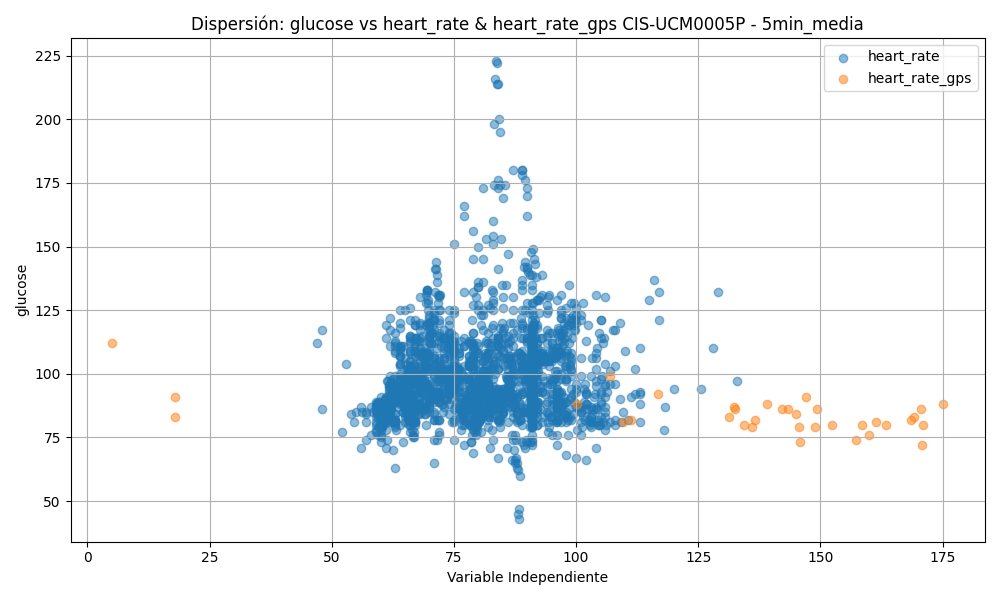

[OK] Guardado: Analysis\Dispersión\CIS-UCM0005P_scatter_glucose_vs_heart_rate_heart_rate_gps_5min_media.png


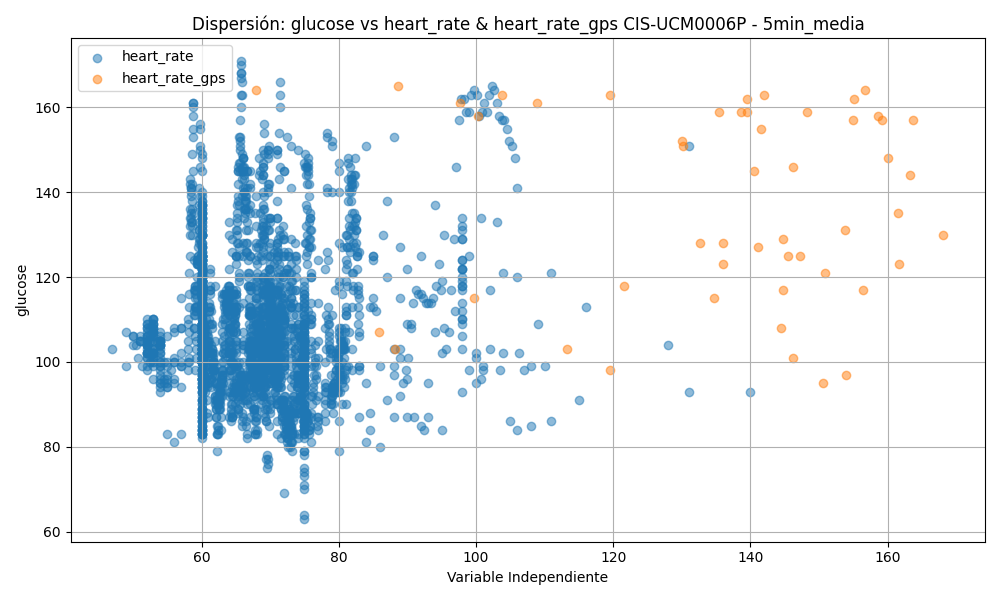

[OK] Guardado: Analysis\Dispersión\CIS-UCM0006P_scatter_glucose_vs_heart_rate_heart_rate_gps_5min_media.png


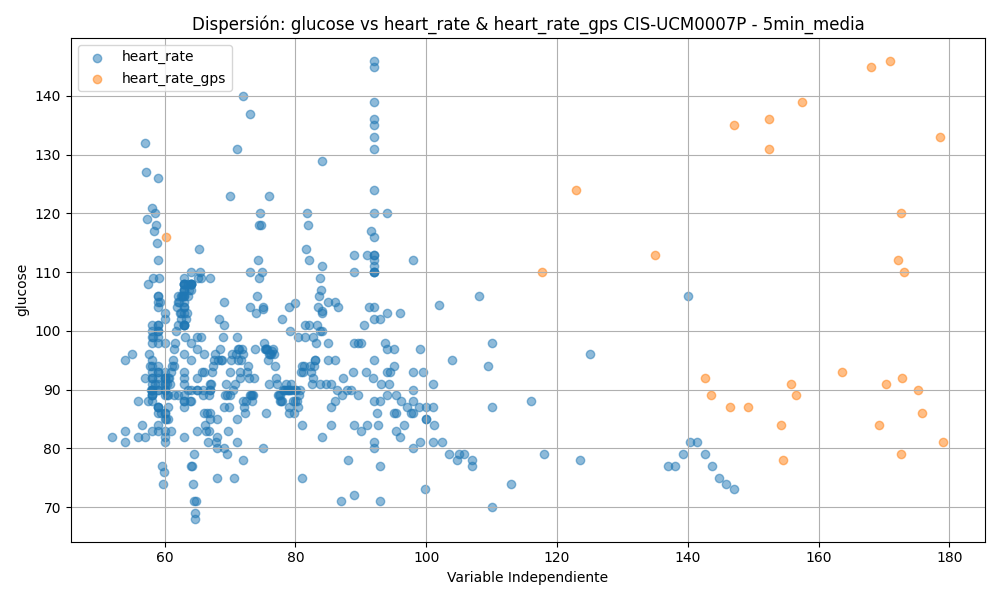

[OK] Guardado: Analysis\Dispersión\CIS-UCM0007P_scatter_glucose_vs_heart_rate_heart_rate_gps_5min_media.png


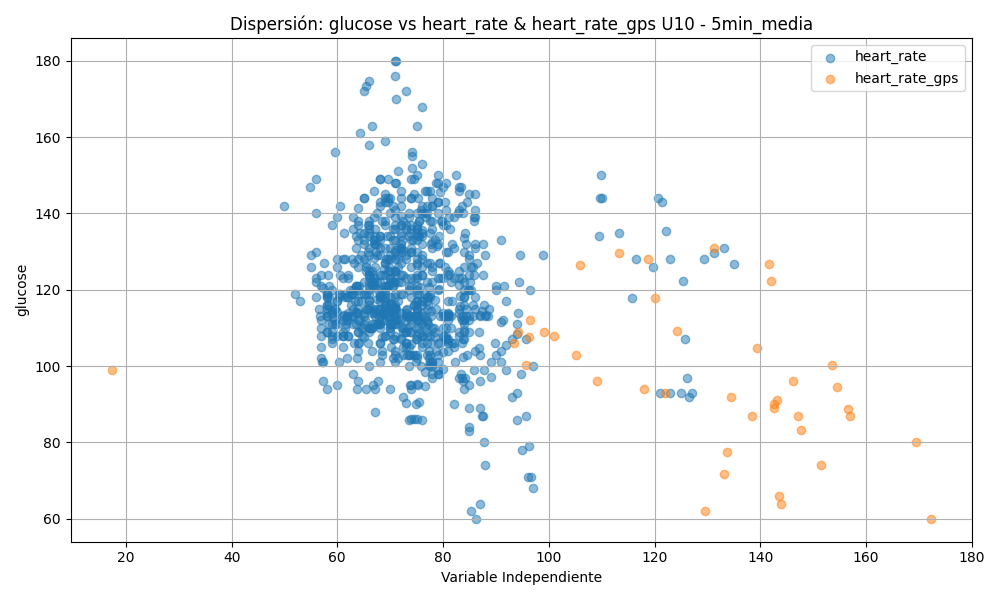

[OK] Guardado: Analysis\Dispersión\U10_scatter_glucose_vs_heart_rate_heart_rate_gps_5min_media.png


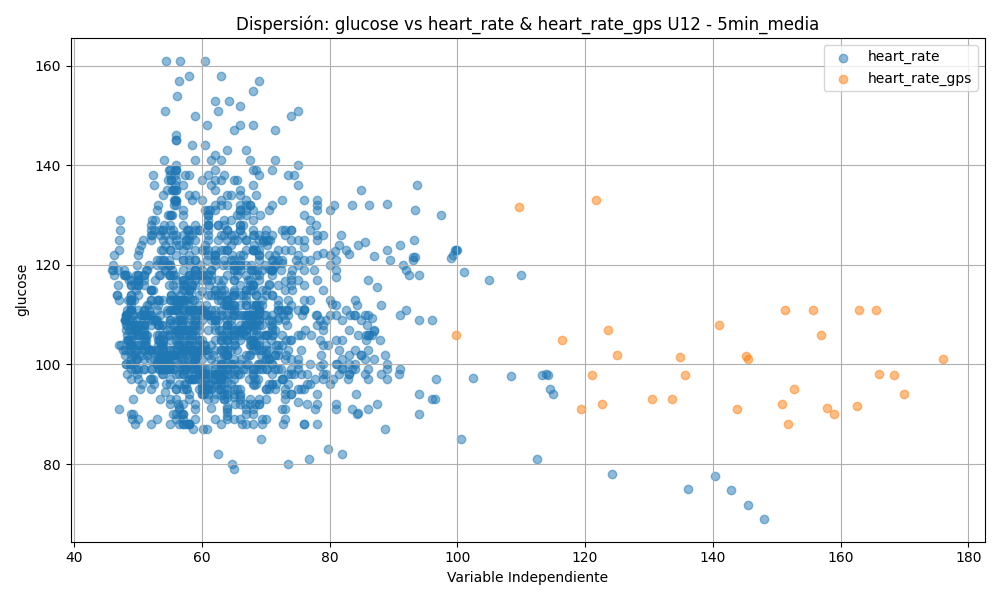

[OK] Guardado: Analysis\Dispersión\U12_scatter_glucose_vs_heart_rate_heart_rate_gps_5min_media.png


In [6]:
if __name__ == "__main__":
    carpeta = r"Data\Trusted\Agrupados"
    filtro = "5min_media"
    salida = r"Analysis\Dispersión"
    scatter_glucosa_vs_ritmo_carpeta(carpeta, filtro, salida)

In [7]:
plt.close('all')

##### B1.1.3 Histograma de glucosa

Un log-transform o Box–Cox puede estabilizar la varianza si el histograma y la dispersión muestran asimetrías o heterocedasticidad.

In [8]:
def histograma_glucosa_trusted(
    archivo_master,
    output_folder,
    bins=30,
    titulo=None,
    figsize=(10, 6)
):
    """
    Genera un histograma de glucosa de un archivo trusted, filtrando ceros y NaNs.

    Args:
        archivo_master (str): Ruta al archivo trusted del usuario.
        output_folder (str): Carpeta donde guardar la imagen.
        bins (int, opcional): Número de bins del histograma.
        titulo (str, opcional): Título del gráfico. Si None, usa el nombre del archivo.
        figsize (tuple, opcional): Tamaño de la figura.

    Returns:
        output_path (str): Ruta de la imagen guardada.
    """
    # Leer datos
    master = pd.read_csv(archivo_master)
    if 'glucose' not in master.columns:
        print(f"Archivo {archivo_master} no contiene columna 'glucose'.")
        return None

    # Filtrar glucosa
    glucosa = master['glucose']
    glucosa = glucosa[(glucosa != 0) & (~glucosa.isna())]

    if glucosa.empty:
        print(f"No hay datos válidos de glucosa en {archivo_master}.")
        return None

    # Graficar histograma
    plt.figure(figsize=figsize)
    plt.hist(glucosa, bins=bins, color='tab:blue', alpha=0.7, edgecolor='black')
    plt.xlabel('Glucosa')
    plt.ylabel('Frecuencia')
    if titulo is None:
        nombre_archivo = os.path.basename(archivo_master).replace('.csv', '')
        titulo = f"{nombre_archivo} - Histograma de Glucosa"
    plt.title(titulo)
    plt.grid(axis='y', linestyle='--', alpha=0.4)
    plt.tight_layout()

    # Guardar imagen
    os.makedirs(output_folder, exist_ok=True)
    output_filename = os.path.splitext(os.path.basename(archivo_master))[0] + '_hist_glucosa.png'
    output_path = os.path.join(output_folder, output_filename)
    plt.savefig(output_path)
    print(f"Histograma guardado en: {output_path}")
    return output_path

Histograma guardado en: Analysis\Histogramas glucosa\CIS-UCM0005P_hist_glucosa.png
Histograma guardado en: Analysis\Histogramas glucosa\CIS-UCM0006P_hist_glucosa.png
Histograma guardado en: Analysis\Histogramas glucosa\CIS-UCM0007P_hist_glucosa.png
Histograma guardado en: Analysis\Histogramas glucosa\U10_hist_glucosa.png
Histograma guardado en: Analysis\Histogramas glucosa\U12_hist_glucosa.png


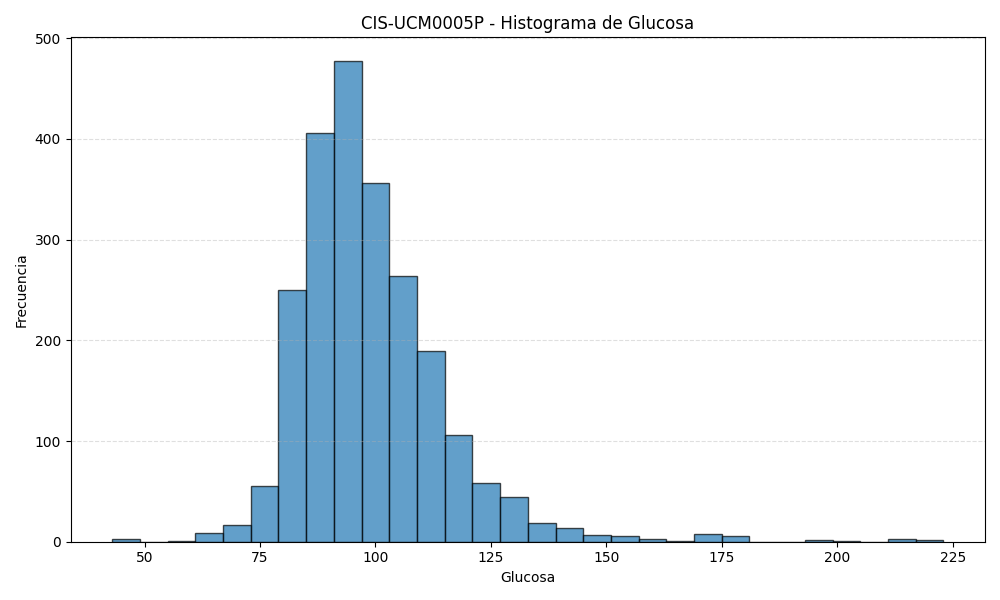

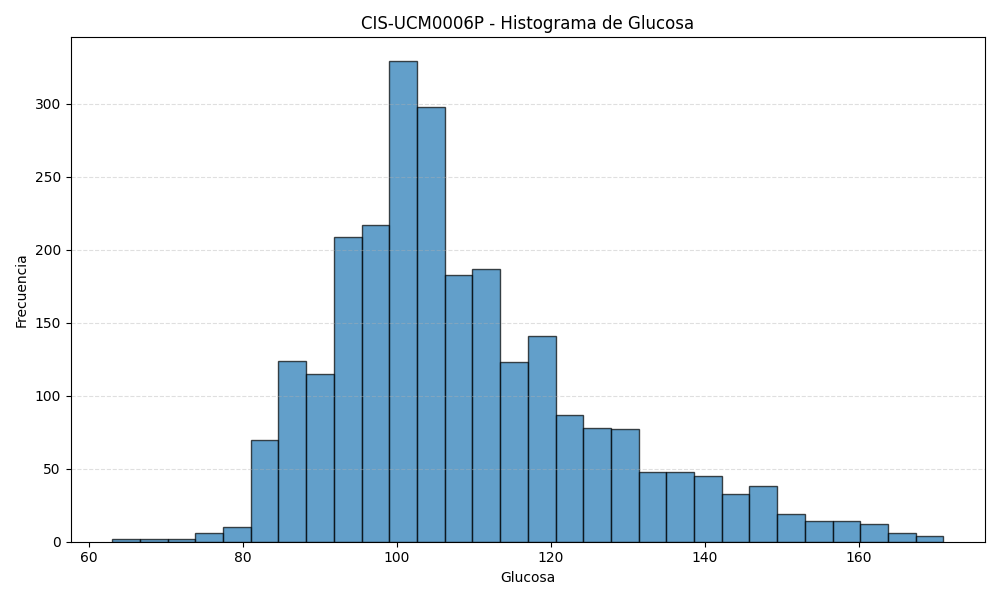

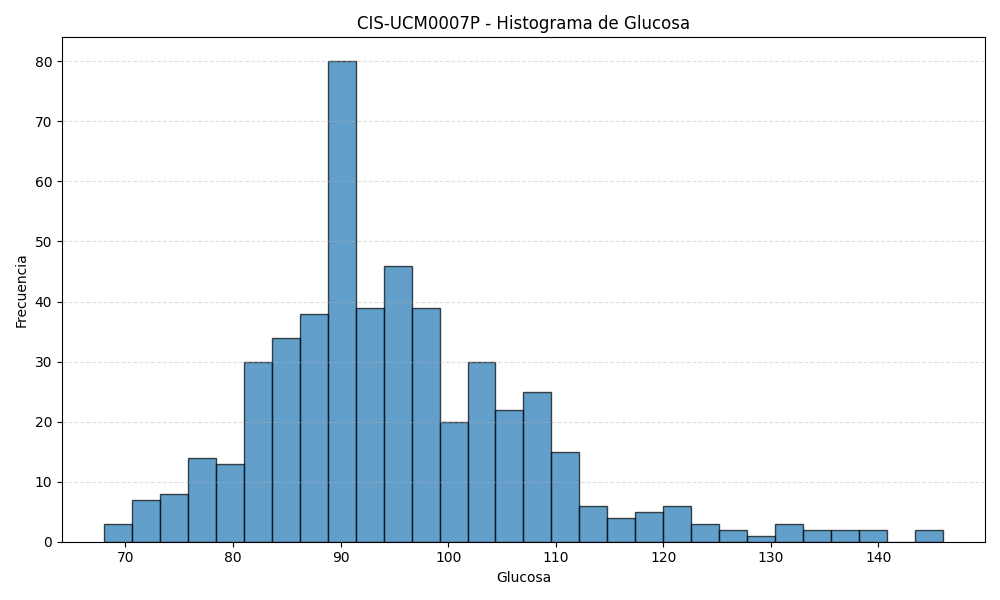

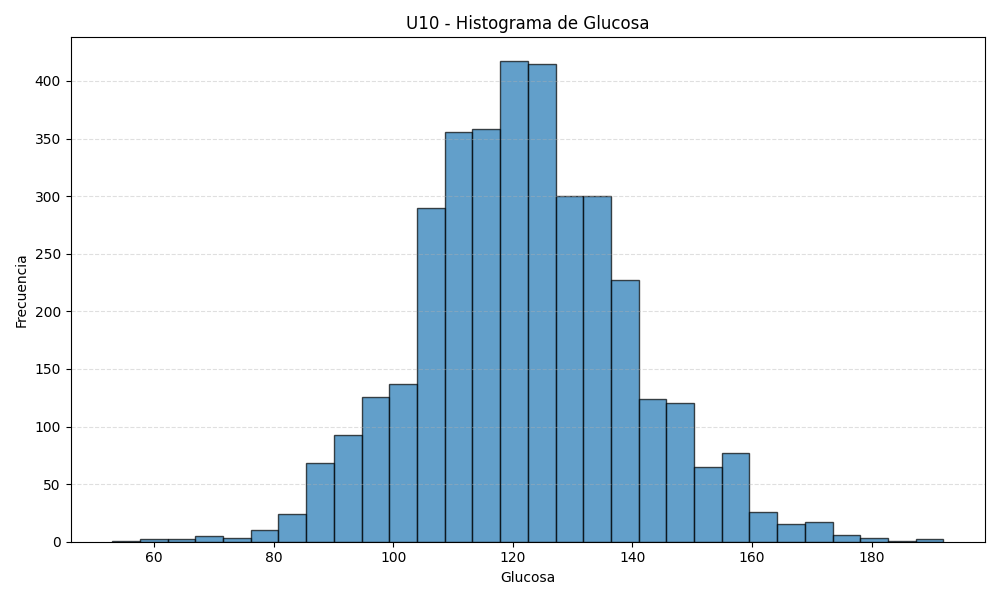

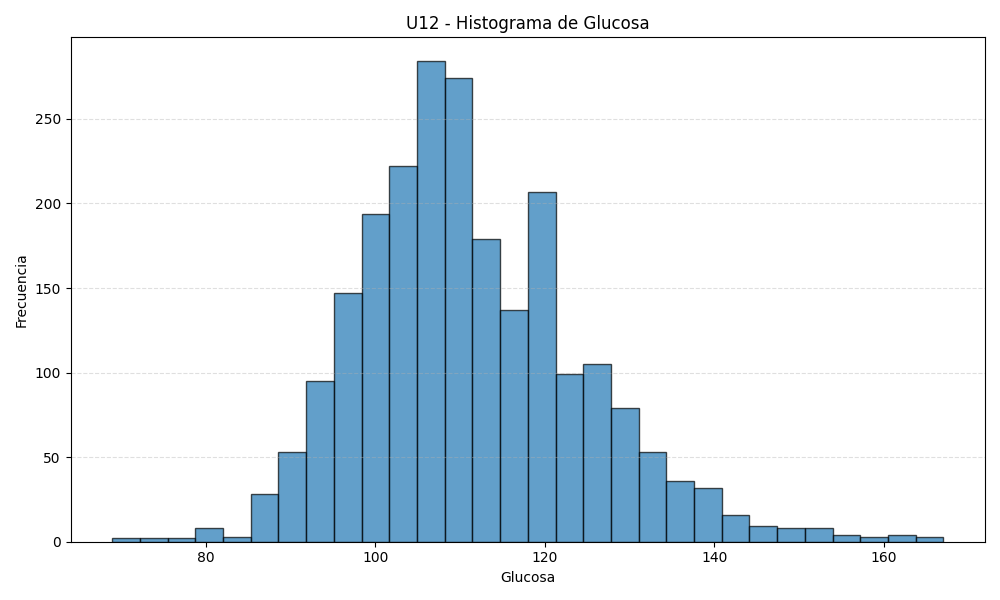

In [9]:
def main_histogramas(folder_path, output_folder):
    """
    Procesa todos los archivos CSV en una carpeta, generando y guardando el histograma de glucosa de cada uno.

    Args:
        folder_path (str): Ruta a la carpeta donde se encuentran los archivos CSV.
        output_folder (str): Carpeta donde se guardarán las imágenes generadas.

    Returns:
        None. Guarda un archivo de imagen (.png) por cada CSV procesado.
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            histograma_glucosa_trusted(file_path, output_folder)

if __name__ == "__main__":
    carpeta = r'Data\Trusted\Completos'
    salida = r'Analysis\Histogramas glucosa'
    main_histogramas(carpeta, salida)

In [10]:
plt.close('all')

##### B1.1.4 Proceso estocástico

Supongamos que tenemos un proceso estocástico con variables que representan los valores de la glucosa cada cinco minutos.
Si tomamos como una realización el intervalo de 24 horas correspondiente a un día, podemos observar la serie temporal como distintas realizaciones de un proceso estocástico.

In [11]:
def plot_glucose_by_day(file_path, output_folder):
    """
    Grafica los datos de glucosa por día a partir de un archivo CSV y guarda la imagen en la carpeta especificada.

    Argumentos:
        file_path (str): Ruta al archivo CSV que contiene las columnas 'time' y 'glucose'.
        output_folder (str): Carpeta donde se guardará la imagen generada.

    Retorna:
        output_path (str): Ruta completa de la imagen guardada.

    Recomendaciones:
        - El archivo debe tener al menos las columnas 'time' y 'glucose'.
        - 'time' debe estar en un formato reconocible por pandas.
        - La carpeta de salida debe existir; si no, se creará automáticamente.
    """
    df = pd.read_csv(file_path, parse_dates=['time'])
    df = df[['time', 'glucose']].dropna()
    df['date'] = df['time'].dt.date

    days = list(df['date'].unique())
    #colors = cm.get_cmap('tab20', len(days))    # Paleta de colores estándar
    colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')

    plt.figure(figsize=(10, 6))
    for i, day in enumerate(days):
        group = df[df['date'] == day]
        hour = group['time'].dt.hour + group['time'].dt.minute/60
        plt.plot(hour, group['glucose'], label=str(day), color=colors(i))

    plt.xlabel('Hora del día')
    plt.ylabel('Glucosa')
    plt.title(f'Procesos estocásticos de glucosa (cada día es una realización)\nArchivo: {os.path.basename(file_path)}')
    plt.legend(loc='upper right', fontsize='small', ncol=3, title='Día')
    plt.tight_layout()
    plt.grid(True)
    plt.show

    # Crear carpeta de salida (si no existe)
    os.makedirs(output_folder, exist_ok=True)
    output_filename = os.path.splitext(os.path.basename(file_path))[0] + '.png'
    output_path = os.path.join(output_folder, output_filename)
    plt.savefig(output_path)
    return output_path

C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2742951580.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')


Imagen guardada en: Analysis\Procesos estocásticos\CIS-UCM0005P.png


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2742951580.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')


Imagen guardada en: Analysis\Procesos estocásticos\CIS-UCM0006P.png


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2742951580.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')


Imagen guardada en: Analysis\Procesos estocásticos\CIS-UCM0007P.png


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2742951580.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')


Imagen guardada en: Analysis\Procesos estocásticos\U10.png


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2742951580.py:23: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  colors = cm.get_cmap('magma', len(days))     # Paleta de colores homogénea (Alt:'viridis','cividis','plasma','inferno','magma')


Imagen guardada en: Analysis\Procesos estocásticos\U12.png


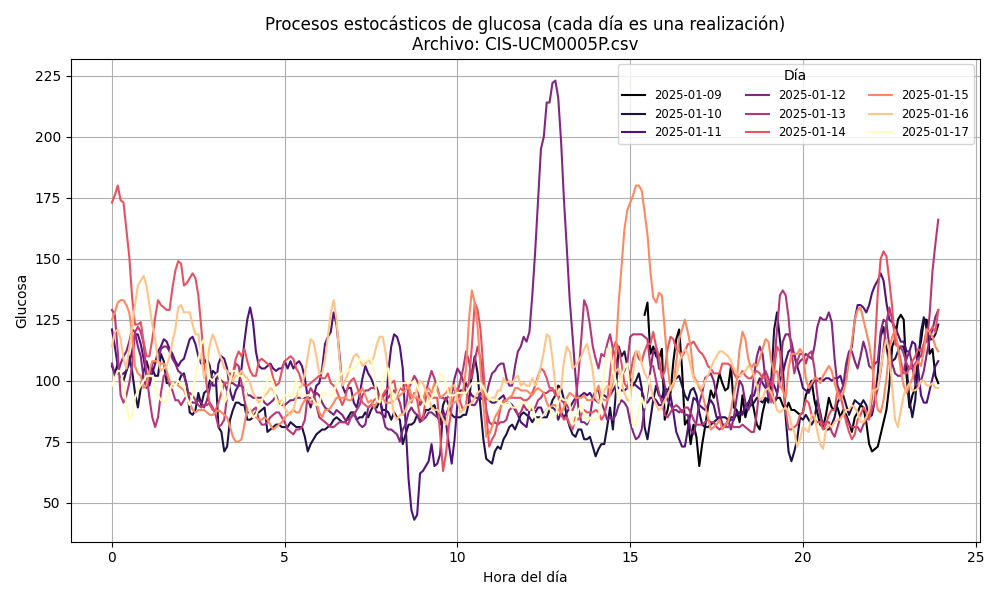

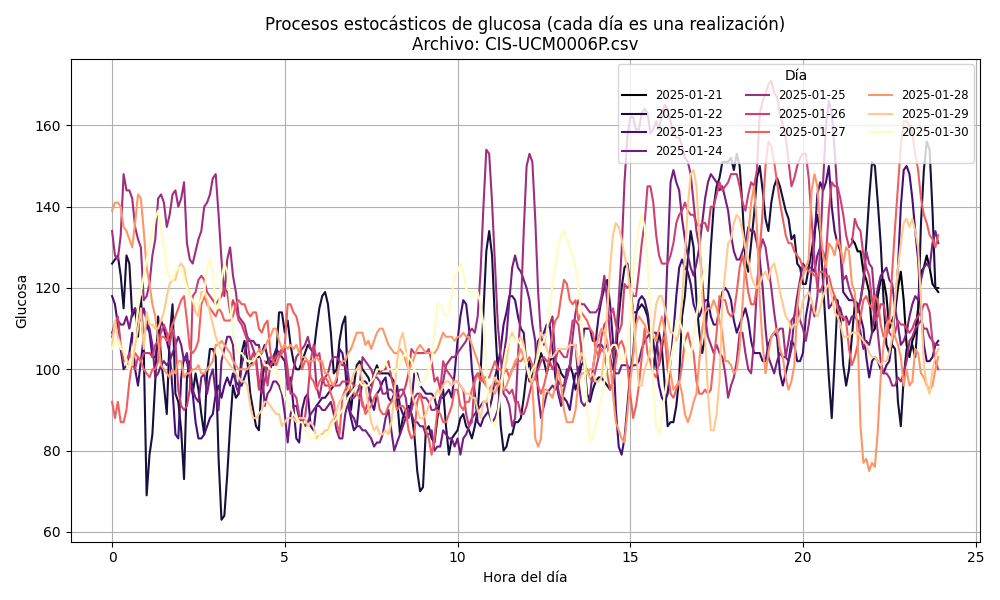

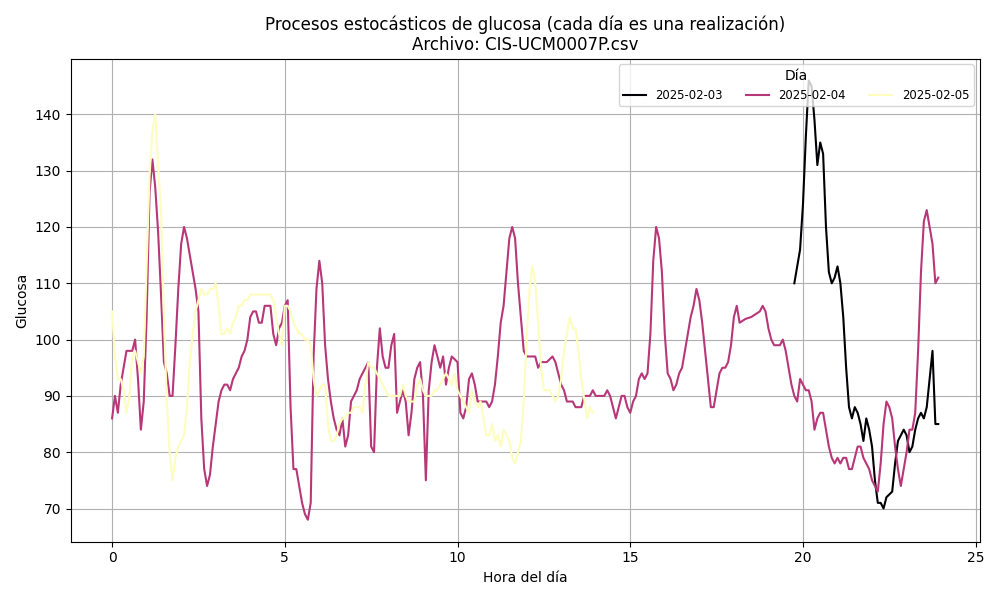

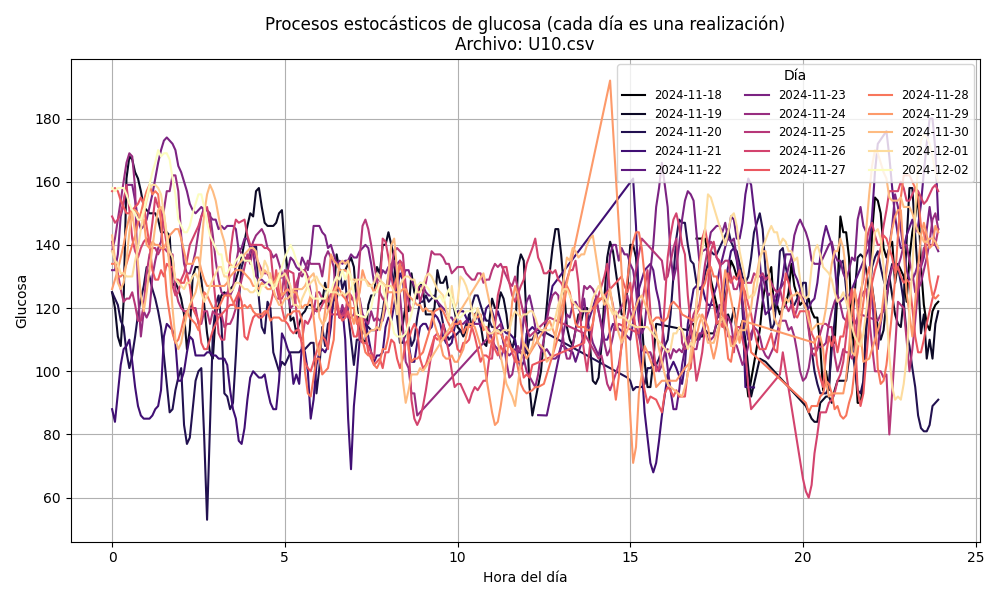

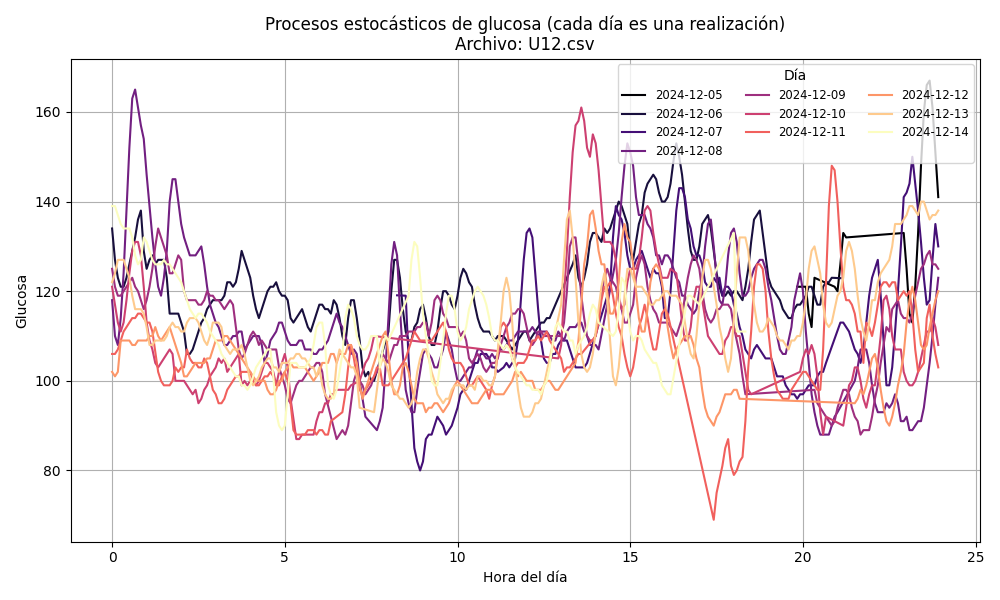

In [12]:
def main(folder_path, output_folder):
    """
    Busca y procesa todos los archivos CSV en una carpeta, graficando y guardando los datos de glucosa de cada uno.

    Argumentos:
        folder_path (str): Ruta a la carpeta donde se encuentran los archivos CSV.
        output_folder (str): Carpeta donde se guardarán las imágenes generadas.

    Retorna:
        None. Guarda un archivo de imagen (.png) por cada CSV procesado.

    Recomendaciones:
        - Verifica que la ruta de salida tenga permisos de escritura.
        - Si hay muchos archivos, asegúrate de tener suficiente espacio en disco.
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            output_path = plot_glucose_by_day(file_path, output_folder)
            print(f"Imagen guardada en: {output_path}")

if __name__ == "__main__":
    carpeta = r'Data\Trusted\Completos'
    salida = r'Analysis\Procesos estocásticos'
    main(carpeta, salida)

In [13]:
plt.close('all')

Esta visualización por días trata cada jornada como una realización del mismo proceso estocástico y muestra cierta variabilidad interdiaria sin un patrón circadiano robusto, lo que refuerza la preferencia por modelos con estructura principalmente de corto plazo.

#### B1.2 Velocidad y aceleración

In [14]:
def explorar_velocidad_aceleracion(file_path, output_folder):
    """
    Carga y visualiza gráficamente un archivo trusted.
    Incluye: señales temporales, aceleración, velocidad, actividad y mapa GPS.
    Guarda la imagen en la carpeta especificada.

    Args:
        file_path (str): Ruta al archivo CSV del usuario.
        output_folder (str): Carpeta donde guardar la imagen.

    Returns:
        output_path (str): Ruta de la imagen guardada.
    """
    print(f"\n📂 Explorando archivo: {file_path}")

    df = pd.read_csv(file_path, parse_dates=["time"])
    df.set_index("time", inplace=True)

    # Obtener nombre de usuario desde el archivo
    user_id = os.path.splitext(os.path.basename(file_path))[0]

    plt.figure(figsize=(10, 6))

    # Velocidad
    if "speed" in df.columns:
        plt.subplot(2, 1, 1)
        df["speed"].plot(label="Speed", color="orange")
        plt.title(f"Velocidad - {user_id}")
        plt.ylabel("km/h")
        plt.grid(True)

    # Magnitud de aceleración
    if all(col in df.columns for col in ["accX", "accY", "accZ"]):
        plt.subplot(2, 1, 2)
        df["acc_mag"] = (df["accX"]**2 + df["accY"]**2 + df["accZ"]**2)**0.5
        df["acc_mag"].plot(label="Aceleración", color="green")
        plt.title(f"Magnitud de aceleración - {user_id}")
        plt.ylabel("m/s²")
        plt.grid(True)

    plt.tight_layout()

    # Crear carpeta de salida (si no existe)
    os.makedirs(output_folder, exist_ok=True)
    output_filename = f"{user_id}_velocidad_aceleracion.png"
    output_path = os.path.join(output_folder, output_filename)
    plt.savefig(output_path)
    print(f"Imagen guardada en: {output_path}")
    return output_path



📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0005P.csv
Imagen guardada en: Analysis\Velocidad y aceleracion\CIS-UCM0005P_velocidad_aceleracion.png

📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0006P.csv
Imagen guardada en: Analysis\Velocidad y aceleracion\CIS-UCM0006P_velocidad_aceleracion.png

📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0007P.csv
Imagen guardada en: Analysis\Velocidad y aceleracion\CIS-UCM0007P_velocidad_aceleracion.png

📂 Explorando archivo: Data\Trusted\Completos\U10.csv
Imagen guardada en: Analysis\Velocidad y aceleracion\U10_velocidad_aceleracion.png

📂 Explorando archivo: Data\Trusted\Completos\U12.csv
Imagen guardada en: Analysis\Velocidad y aceleracion\U12_velocidad_aceleracion.png


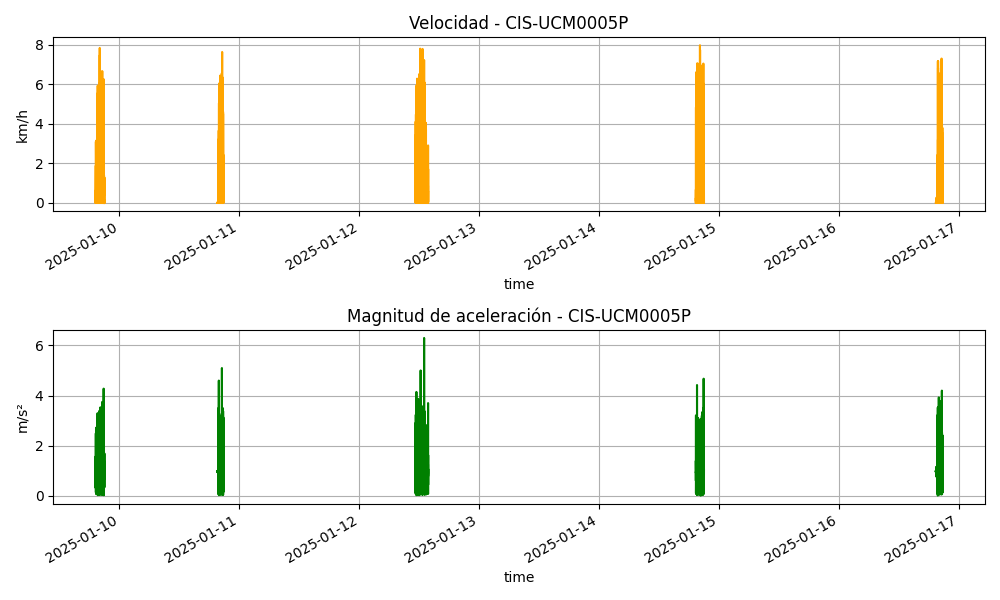

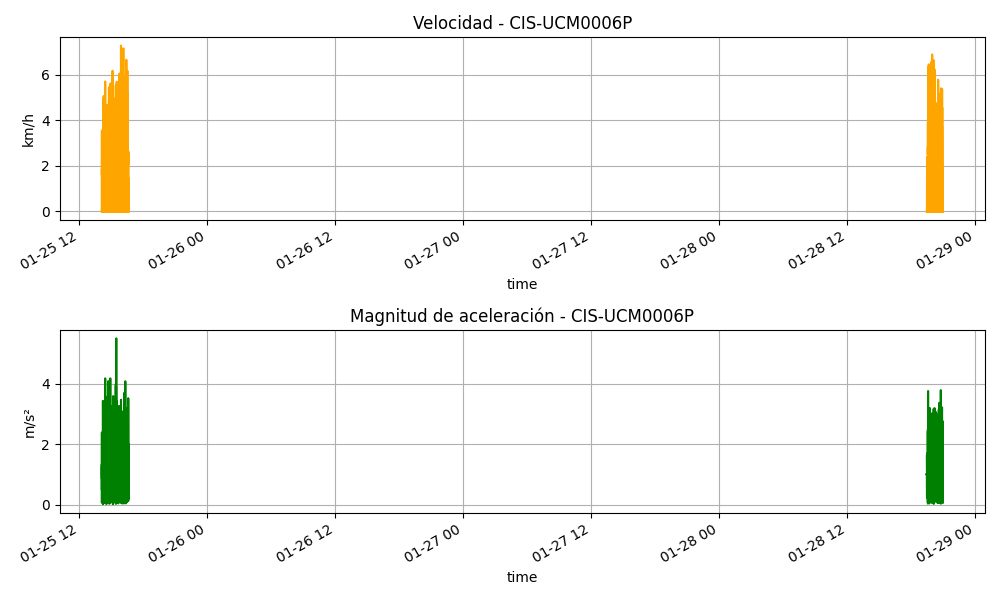

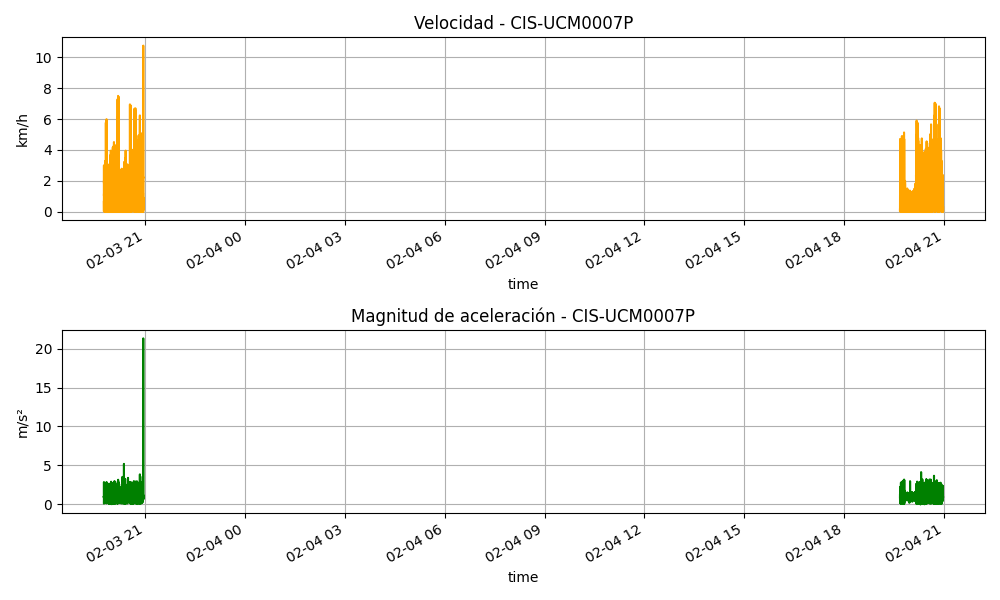

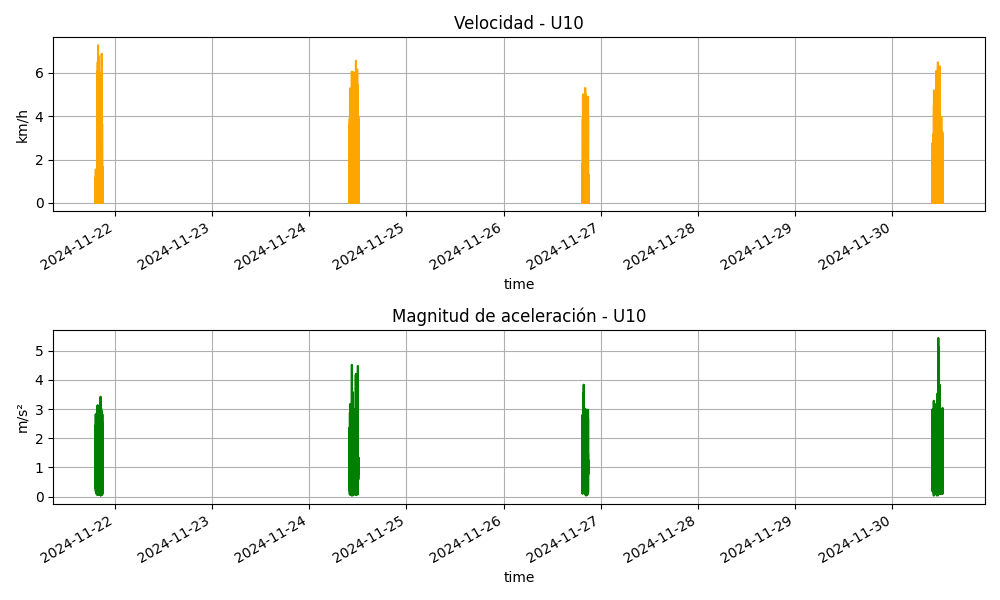

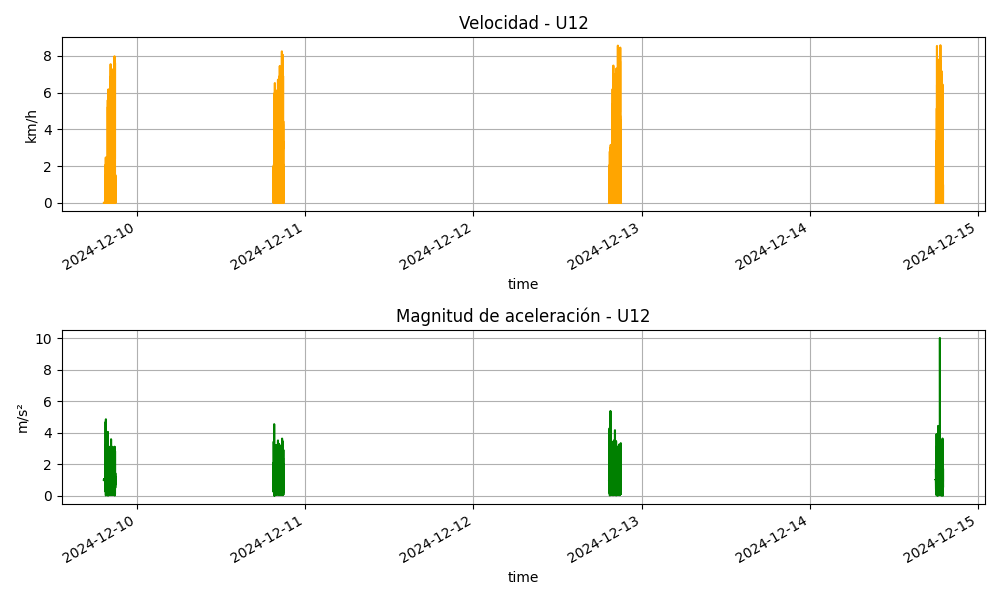

In [15]:
def main(folder_path, output_folder):
    """
    Procesa todos los archivos CSV en una carpeta, graficando velocidad y aceleración de cada uno y guardando las imágenes.

    Args:
        folder_path (str): Ruta a la carpeta donde se encuentran los archivos CSV.
        output_folder (str): Carpeta donde se guardarán las imágenes generadas.

    Returns:
        None.
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            explorar_velocidad_aceleracion(file_path, output_folder)

if __name__ == "__main__":
    carpeta = r'Data\Trusted\Completos'
    salida = r'Analysis\Velocidad y aceleracion'
    main(carpeta, salida)

In [16]:
plt.close('all')

#### B1.3 Pasos y calorías

In [17]:
def explorar_pasos_calorias(file_path, output_folder):
    """
    Carga y visualiza gráficamente un archivo trusted.
    Incluye: señales temporales de pasos y calorías.
    Guarda la imagen en la carpeta especificada.

    Args:
        file_path (str): Ruta al archivo CSV del usuario.
        output_folder (str): Carpeta donde guardar la imagen.

    Returns:
        output_path (str): Ruta de la imagen guardada.
    """
    print(f"\n📂 Explorando archivo: {file_path}")

    df = pd.read_csv(file_path, parse_dates=["time"])
    df.set_index("time", inplace=True)

    # Obtener nombre de usuario desde el archivo
    user_id = os.path.splitext(os.path.basename(file_path))[0]

    plt.figure(figsize=(10, 6))
    plotted = False

    if "steps" in df.columns:
        df["steps"].plot(label="Steps", color="purple")
        plotted = True
    if "calories" in df.columns:
        df["calories"].plot(label="Calories", color="red")
        plotted = True

    plt.title(f"Pasos y calorías - {user_id}")
    plt.ylabel("Unidades")
    plt.legend()
    plt.grid(True)
    plt.tight_layout()

    # Solo guarda si hay algo que graficar
    if plotted:
        os.makedirs(output_folder, exist_ok=True)
        output_filename = f"{user_id}_actividad_fisica.png"
        output_path = os.path.join(output_folder, output_filename)
        plt.savefig(output_path)
        print(f"Imagen guardada en: {output_path}")
        return output_path
    else:
        print(f"[ADVERTENCIA] No hay columnas 'steps' o 'calories' en {file_path}")
        return None



📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0005P.csv
Imagen guardada en: Analysis\Gráficas pasos y calorias\CIS-UCM0005P_actividad_fisica.png

📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0006P.csv
Imagen guardada en: Analysis\Gráficas pasos y calorias\CIS-UCM0006P_actividad_fisica.png

📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0007P.csv
Imagen guardada en: Analysis\Gráficas pasos y calorias\CIS-UCM0007P_actividad_fisica.png

📂 Explorando archivo: Data\Trusted\Completos\U10.csv
Imagen guardada en: Analysis\Gráficas pasos y calorias\U10_actividad_fisica.png

📂 Explorando archivo: Data\Trusted\Completos\U12.csv
Imagen guardada en: Analysis\Gráficas pasos y calorias\U12_actividad_fisica.png


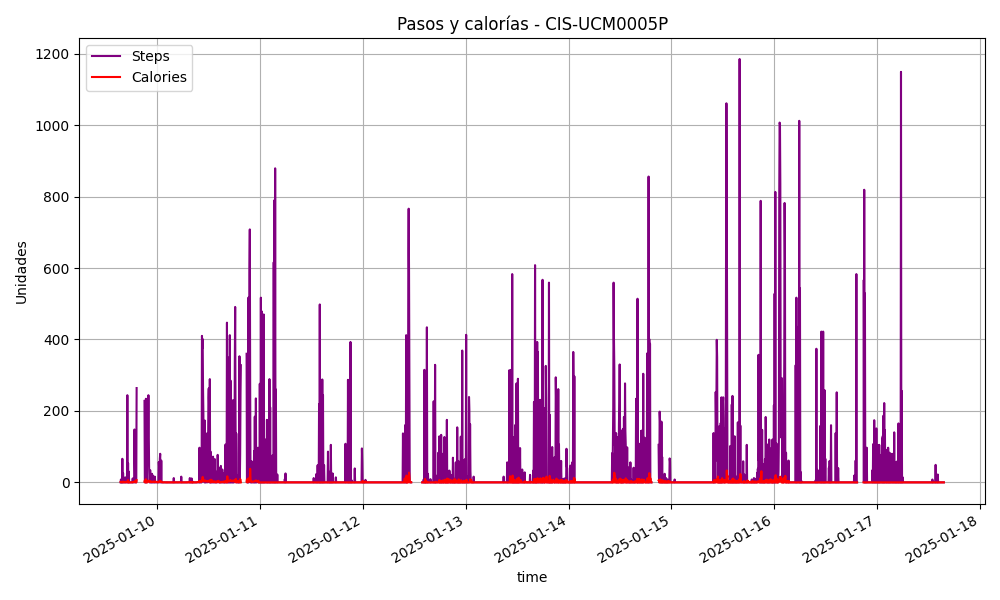

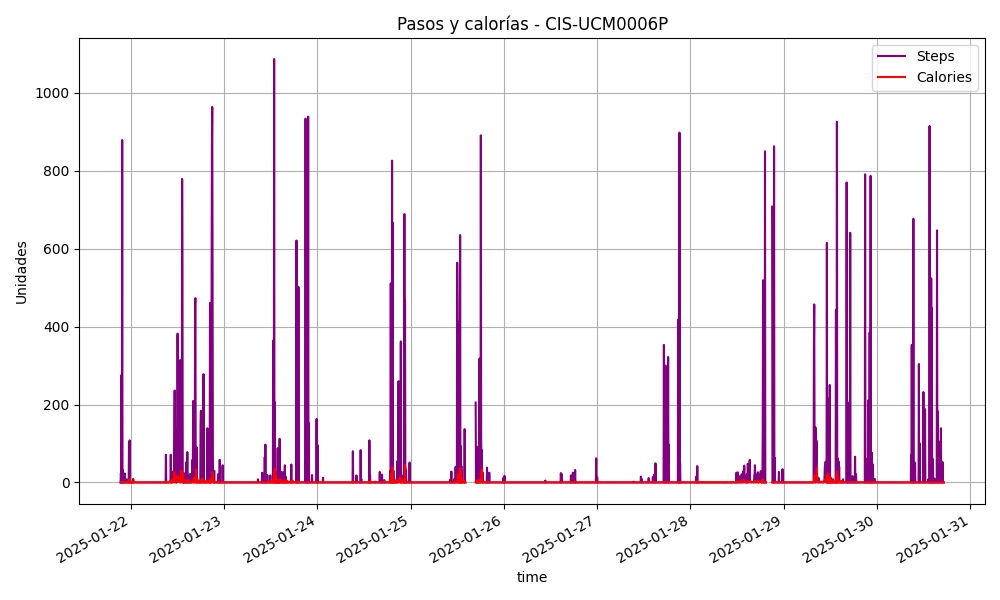

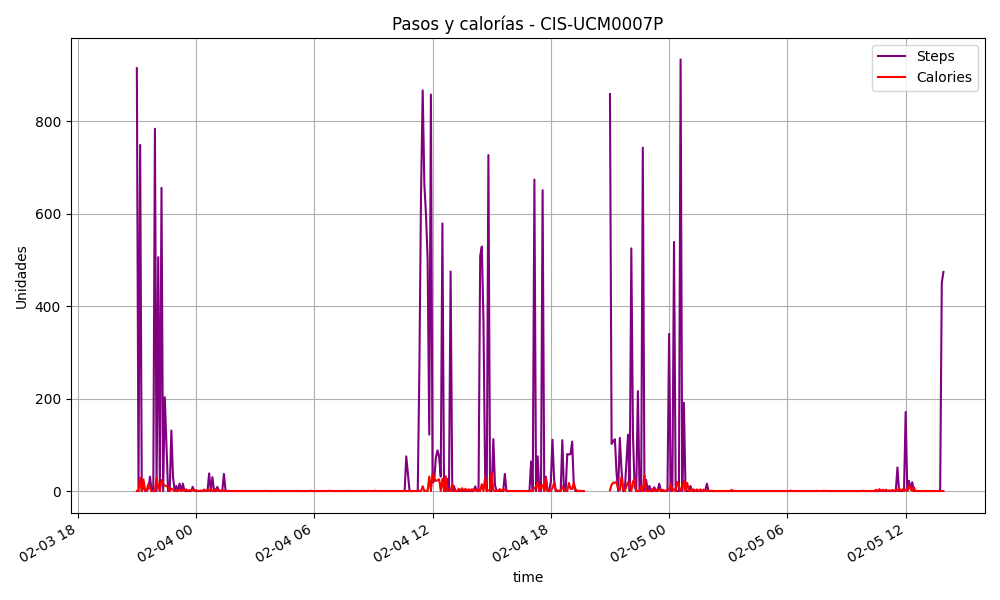

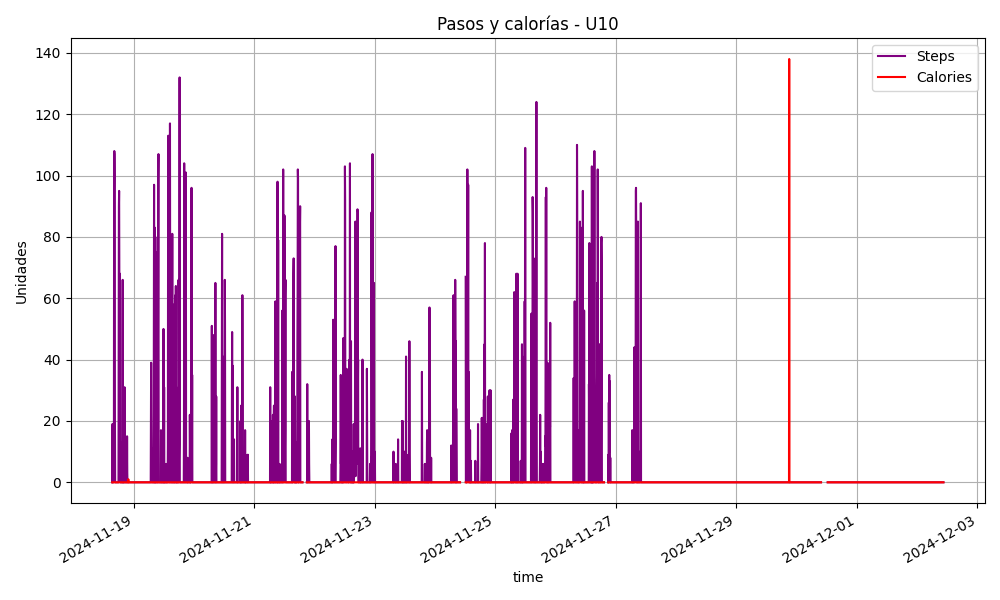

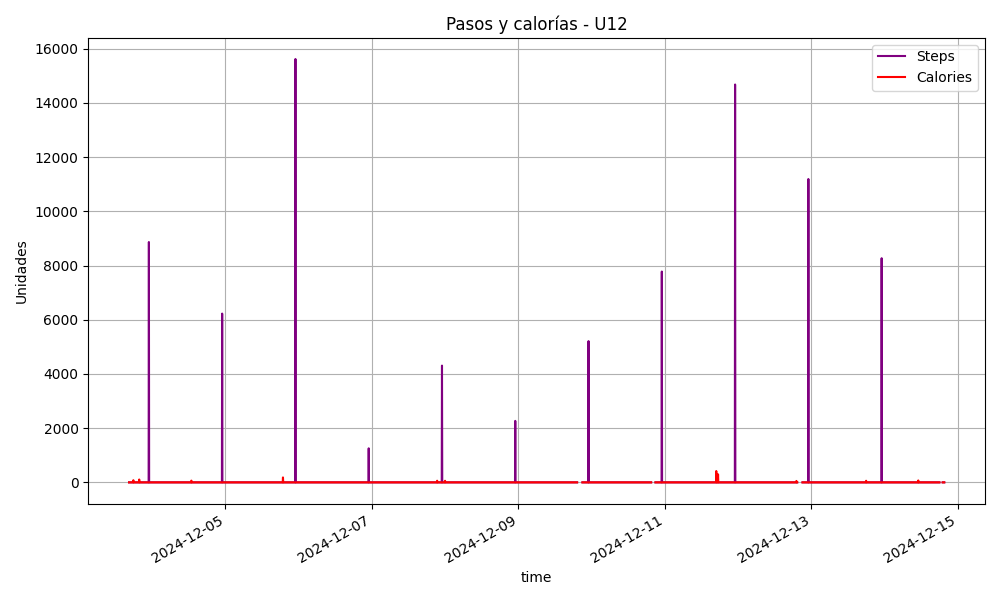

In [18]:
def main(folder_path, output_folder):
    """
    Procesa todos los archivos CSV en una carpeta, graficando pasos y calorías de cada uno y guardando las imágenes.

    Args:
        folder_path (str): Ruta a la carpeta donde se encuentran los archivos CSV.
        output_folder (str): Carpeta donde se guardarán las imágenes generadas.

    Returns:
        None.
    """
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            explorar_pasos_calorias(file_path, output_folder)

if __name__ == "__main__":
    carpeta = r'Data\Trusted\Completos'
    salida = r'Analysis\Gráficas pasos y calorias'
    main(carpeta, salida)

In [19]:
plt.close('all')

#### B1.4 Heatmap de la actividad física

In [20]:
def procesar_gps_carpeta(folder_path, output_folder, time_threshold='6H'):
    """
    Procesa todos los archivos CSV de una carpeta, generando mapas Folium por sesiones GPS.
    Guarda archivos HTML y muestra el mapa en Jupyter.

    Args:
        folder_path (str): Carpeta con archivos CSV trusted.
        output_folder (str): Carpeta donde guardar los mapas HTML.
        time_threshold (str): Umbral para separar sesiones, e.g. '6H' (6 horas).
    """
    os.makedirs(output_folder, exist_ok=True)
    for filename in os.listdir(folder_path):
        if filename.endswith('.csv'):
            file_path = os.path.join(folder_path, filename)
            explorar_usuario_gps(file_path, output_folder, time_threshold)

def explorar_usuario_gps(file_path, output_folder, time_threshold='6H'):
    """
    Genera mapas GPS interactivos (Folium) por sesiones.
    Guarda HTML y muestra en Jupyter.

    Args:
        file_path (str): Ruta al archivo CSV trusted.
        output_folder (str): Carpeta donde guardar los mapas HTML.
        time_threshold (str): Umbral para separar sesiones, e.g. '6H' (6 horas).
    """
    print(f"\n📂 Explorando archivo: {file_path}")
    df = pd.read_csv(file_path, parse_dates=["time"])
    user_id = os.path.splitext(os.path.basename(file_path))[0]

    if "latitude" in df.columns and "longitude" in df.columns:
        valid_gps = df.dropna(subset=["latitude", "longitude"]).copy()
        if not valid_gps.empty:
            valid_gps = valid_gps.sort_values('time')
            valid_gps['time_diff'] = valid_gps['time'].diff().dt.total_seconds().fillna(0)
            threshold_seconds = pd.to_timedelta(time_threshold).total_seconds()
            valid_gps['new_session'] = valid_gps['time_diff'] > threshold_seconds
            valid_gps['session_id'] = valid_gps['new_session'].cumsum()

            session_ids = valid_gps['session_id'].unique()
            print(f"  ➤ {len(session_ids)} sesión(es) encontrada(s) en {user_id}")

            for session_id in session_ids:
                session_data = valid_gps[valid_gps['session_id'] == session_id]
                if session_data.empty:
                    continue

                center = [session_data["latitude"].iloc[0], session_data["longitude"].iloc[0]]
                m = folium.Map(location=center, zoom_start=15, control_scale=True)

                # Ruta (línea)
                folium.PolyLine(
                    session_data[['latitude', 'longitude']].values,
                    color="blue", weight=2, opacity=0.7
                ).add_to(m)

                # Puntos GPS -> tarda mucho más si se incluye (22mins aprox)
                #for _, row in session_data.iterrows():
                #    folium.CircleMarker(
                #        location=[row["latitude"], row["longitude"]],
                #        radius=2,
                #        color="blue",
                #        fill=True,
                #        fill_opacity=0.6
                #    ).add_to(m)

                # HeatMap de densidad
                HeatMap(session_data[['latitude', 'longitude']].values, radius=15, blur=10).add_to(m)

                # Guardar HTML
                html_name = f"{user_id}_sesion{int(session_id)+1}.html"
                html_path = os.path.join(output_folder, html_name)
                m.save(html_path)
                print(f"    🗺️  Mapa HTML guardado: {html_path}")

                # Mostrar en Jupyter
                display(m)

        else:
            print("⚠️ No hay coordenadas GPS válidas para mostrar en el mapa.")
    else:
        print("⚠️ El archivo no contiene columnas latitude/longitude.")

In [21]:
if __name__ == "__main__":
    carpeta = r'Data\Trusted\Completos'
    salida = r'Analysis\Heatmaps'
    procesar_gps_carpeta(carpeta, salida, time_threshold='6H')


📂 Explorando archivo: Data\Trusted\Completos\CIS-UCM0005P.csv


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\2092475378.py:36: FutureWarning: 'H' is deprecated and will be removed in a future version. Please use 'h' instead of 'H'.
  threshold_seconds = pd.to_timedelta(time_threshold).total_seconds()


  ➤ 5 sesión(es) encontrada(s) en CIS-UCM0005P
    🗺️  Mapa HTML guardado: Analysis\Heatmaps\CIS-UCM0005P_sesion1.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\CIS-UCM0005P_sesion2.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\CIS-UCM0005P_sesion3.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\CIS-UCM0005P_sesion4.html


... (17 outputs left out)

  ➤ 4 sesión(es) encontrada(s) en U12
    🗺️  Mapa HTML guardado: Analysis\Heatmaps\U12_sesion1.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\U12_sesion2.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\U12_sesion3.html


    🗺️  Mapa HTML guardado: Analysis\Heatmaps\U12_sesion4.html


In [22]:
plt.close('all')

## C. ANÁLISIS AVANZADOS

**Metodología:**
En cada participante (y subserie) se evalúa la estructura y dependencia temporal de la glucosa mediante: 

1. Autocorrelación (ACF) y autocorrelación parcial (PACF) con lags de 5 minutos, siempre que exista un tamaño muestral efectivo para garantizar estabilidad numérica. En ACF/PACF marcaremos líneas verticales cada 12 lags (≈1 hora a muestreo de 5 minutos) para facilitar la lectura e interpretación fisiológica.
2. Pruebas de estacionariedad Dickey-Fuller aumentada (ADF) y Kwiatkowski-Phillips-Schmidt-Shin (KPSS)
3. Análisis espectral (periodograma y espectro suavizado tipo Welch). 

Primero realizamos una descomposición STL de periodo diario (288 pasos de 5 minutos), dado que muchos factores fisiológicos poseen un comportamiento circadiano recurrente, y por ello ésta puede ser una hipótesis inicial a seguir, y si los análisis posteriores nos confirman dicho comportamiento, la descomposición nos brinda una separación en componentes (tendencia, estacionalidad y residuo) con la que trabajar más adelante.

### C1. Descomposición STL

Divide la serie en componentes: tendencia, estacionalidad y residual. Ayuda a entender la estructura de los datos.

El modelo aditivo suele ser la opción más adecuada en la mayoría de los casos clínicos y fisiológicos, y en concreto para la descomposición STL de la glucosa.

**¿Por qué aditivo?**
- El modelo aditivo asume que la serie temporal se puede descomponer como suma de tendencia, estacionalidad y residuo:  
  $$ y_t = T_t + S_t + R_t $$
- Esto es apropiado cuando la magnitud de la variabilidad (por ejemplo, las oscilaciones diarias o semanales de glucosa) se mantiene relativamente constante a lo largo del tiempo, independientemente del nivel medio de glucosa.
- Vistas las gráficas del apartado de visualización, la amplitud de las oscilaciones de glucosa no parece aumentar ni disminuir claramente cuando el nivel medio sube o baja, lo que respalda el uso del modelo aditivo.

**¿Cuándo usar multiplicativo?**
- El modelo multiplicativo se usa cuando la variabilidad aumenta proporcionalmente con el nivel de la serie (por ejemplo, si los picos de glucosa fueran mucho más altos cuando el promedio es alto, y mucho menores cuando el promedio es bajo).

In [23]:
def descomponer_glucosa(df, period=288, output_path="decomposition_result.png", guardar_csv=False, modelo='aditivo'):
    """
    Realiza la descomposición estacional de una serie de glucosa.

    Args:
        df (pd.DataFrame): DataFrame con columna 'glucose' y 'time'.
        period (int): Periodo de la estacionalidad (por defecto 288 = 1 día a 5 min).
        output_path (str): Ruta donde guardar la figura del gráfico.
        guardar_csv (bool): Si True, guarda los componentes en CSV.
        modelo (str): Tipo de modelo para la descomposición ('aditivo' o 'multiplicativo').

    Returns:
        dict | None: Diccionario con componentes 'trend', 'seasonal', 'resid', 'observed' o None si no es posible.
    """
    df_clean = df.dropna(subset=["glucose"])

    if len(df_clean) < period:
        print(f"La serie tiene menos de {period} puntos. No se puede descomponer.")
        return None

    try:
        if "time" in df_clean.columns:
            df_clean = df_clean.set_index("time")
        df_clean.index = pd.to_datetime(df_clean.index)

        # Descomposición aditiva
        result = seasonal_decompose(df_clean["glucose"], model=modelo, period=period)

        # Graficar y guardar
        result.plot()
        plt.suptitle("Descomposición de la señal de glucosa", fontsize=14)
        plt.tight_layout()
        plt.savefig(output_path, dpi=300)
        print(f"📈 Gráfico guardado en: {output_path}")

        # Guardar componentes como CSV
        componentes = {
            "observed": result.observed,
            "trend": result.trend,
            "seasonal": result.seasonal,
            "resid": result.resid
        }

        if guardar_csv:
            base_dir = os.path.dirname(output_path)
            base_name = os.path.splitext(os.path.basename(output_path))[0]
            for nombre, serie in componentes.items():
                file_path = os.path.join(base_dir, f"{base_name}_{nombre}.csv")
                serie.to_frame(name=nombre).to_csv(file_path)
                print(f"📝 Componente '{nombre}' guardado en: {file_path}")

        return componentes

    except ValueError as e:
        print(f"❌ Error al descomponer la serie: {e}")
        return None

def procesar_carpeta_descomposicion(input_folder, output_folder, period=288, guardar_csv=True):
    """
    Aplica la descomposición de glucosa aditiva a todos los archivos CSV de una carpeta.
    Guarda los resultados en subcarpetas con el nombre del usuario (extraído del nombre del archivo).
    """
    for filename in os.listdir(input_folder):
        if filename.endswith('.csv'):
            file_path = os.path.join(input_folder, filename)
            # Extraer nombre de usuario del archivo (antes del .csv)
            user = os.path.splitext(filename)[0]
            # Crear carpeta de salida para ese usuario
            user_output_dir = os.path.join(output_folder, user)
            os.makedirs(user_output_dir, exist_ok=True)
            # Definir ruta de salida para la figura
            output_path = os.path.join(user_output_dir, f"{user}_decomposition.png")
            # Leer el archivo y aplicar la descomposición
            df = pd.read_csv(file_path)
            descomponer_glucosa(
                df,
                period=period,
                output_path=output_path,
                guardar_csv=guardar_csv,
                modelo='aditivo'
            )
            print(f"Procesado: {filename} → Resultados en {user_output_dir}")

📈 Gráfico guardado en: Analysis\Descomposición STL\CIS-UCM0005P\CIS-UCM0005P_decomposition.png
📝 Componente 'observed' guardado en: Analysis\Descomposición STL\CIS-UCM0005P\CIS-UCM0005P_decomposition_observed.csv
📝 Componente 'trend' guardado en: Analysis\Descomposición STL\CIS-UCM0005P\CIS-UCM0005P_decomposition_trend.csv
📝 Componente 'seasonal' guardado en: Analysis\Descomposición STL\CIS-UCM0005P\CIS-UCM0005P_decomposition_seasonal.csv
📝 Componente 'resid' guardado en: Analysis\Descomposición STL\CIS-UCM0005P\CIS-UCM0005P_decomposition_resid.csv
Procesado: CIS-UCM0005P.csv → Resultados en Analysis\Descomposición STL\CIS-UCM0005P
📈 Gráfico guardado en: Analysis\Descomposición STL\CIS-UCM0006P\CIS-UCM0006P_decomposition.png
📝 Componente 'observed' guardado en: Analysis\Descomposición STL\CIS-UCM0006P\CIS-UCM0006P_decomposition_observed.csv
📝 Componente 'trend' guardado en: Analysis\Descomposición STL\CIS-UCM0006P\CIS-UCM0006P_decomposition_trend.csv
📝 Componente 'seasonal' guardado en

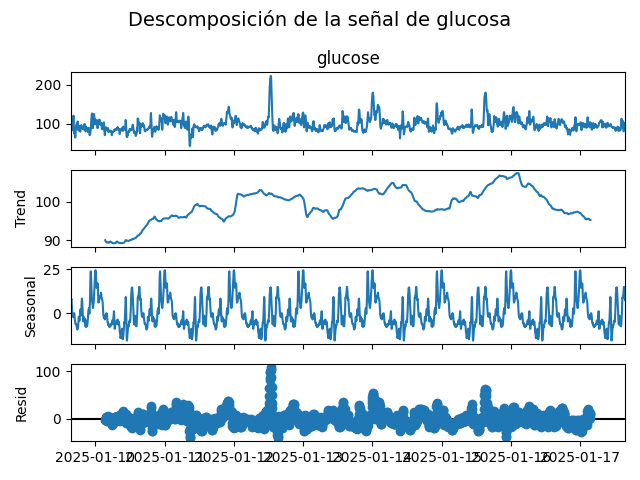

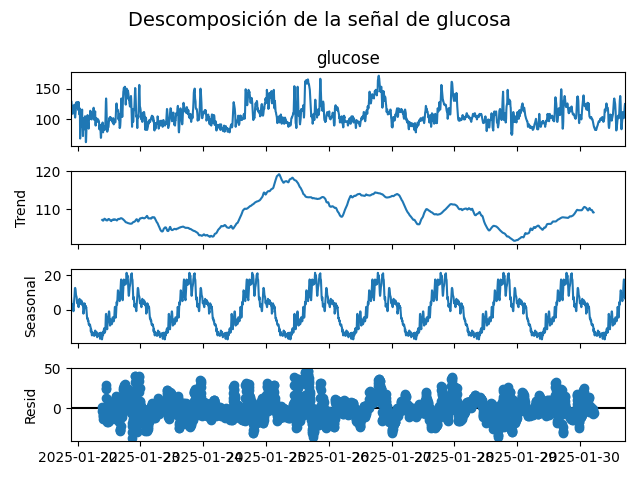

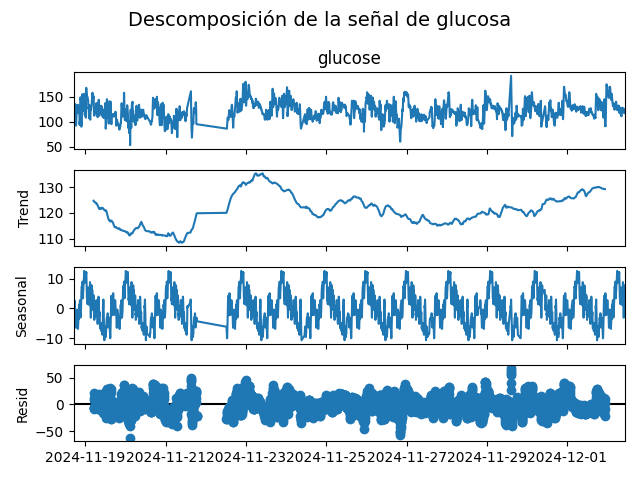

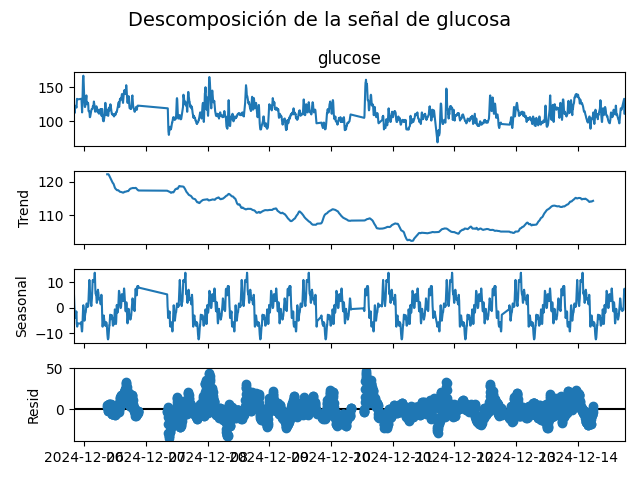

In [24]:
if __name__ == "__main__":
    carpeta_entrada = r'Data\Trusted\Completos'
    carpeta_salida = r'Analysis\Descomposición STL'
    procesar_carpeta_descomposicion(carpeta_entrada, carpeta_salida)

In [25]:
plt.close('all')

### C2. Estacionalidad

#### C2.1 Autocorrelación (ACF) y autocorrelación parcial (PACF)

La autocorrelación examina la dependencia entre valores de la serie en diferentes retrasos (lags). Útil para identificar patrones repetitivos.

La autocorrelación parcial permite entender la relación entre una serie temporal y sus rezagos, eliminando el efecto de los rezagos intermedios.

Para modificar los lags y hacer que el análisis sea más flexible, podemos usar la función acf de statsmodels en lugar de pd.plotting.autocorrelation_plot, ya que esta función permite especificar el número de lags que deseamos calcular y visualizar.

In [26]:
def analizar_autocorrelacion(df, variable, archivo, lags=300, out_dir='Analysis/Autocorrelación'):
    """
    Analiza y grafica la autocorrelación de la variable dada, marcando cada 12 lags.
    Guarda la imagen en la carpeta especificada.
    """
    nombre_base = os.path.splitext(os.path.basename(archivo))[0]
    titulo = f"Autocorrelación {nombre_base}"

    if df[variable].notna().sum() > 0:
        os.makedirs(out_dir, exist_ok=True)
        fig, ax = plt.subplots(figsize=(10, 6))
        plot_acf(df[variable].dropna(), lags=lags, ax=ax)
        ax.set_title(titulo)
        ax.set_xlabel("Lags")
        ax.set_ylabel("Autocorrelación")
        xticks = np.arange(0, lags + 1, 12)
        ax.set_xticks(xticks)
        for tick in xticks:
            ax.axvline(x=tick, color='gray', linestyle='--', linewidth=0.7)
        plt.tight_layout()
        plt.show()
        filename = os.path.join(out_dir, f"{nombre_base}_autocorrelacion.png")
        fig.savefig(filename, dpi=300)
        print(f"[OK] Guardado: {filename}")
    else:
        print(f"No hay suficientes datos válidos para el análisis de autocorrelación de {variable}.")

def analizar_autocorrelacion_parcial(df, variable, archivo, lags=300, out_dir='Analysis/Autocorrelación Parcial'):
    """
    Analiza y grafica la autocorrelación parcial de la variable dada, marcando cada 12 lags.
    Guarda la imagen en la carpeta especificada.
    """
    nombre_base = os.path.splitext(os.path.basename(archivo))[0]
    titulo = f"Autocorrelación Parcial {nombre_base}"

    if df[variable].notna().sum() > 0:
        os.makedirs(out_dir, exist_ok=True)
        fig, ax = plt.subplots(figsize=(10, 6))
        plot_pacf(df[variable].dropna(), lags=lags, ax=ax)
        ax.set_title(titulo)
        ax.set_xlabel("Lags")
        ax.set_ylabel("Autocorrelación Parcial")
        xticks = np.arange(0, lags + 1, 12)
        ax.set_xticks(xticks)
        for tick in xticks:
            ax.axvline(x=tick, color='gray', linestyle='--', linewidth=0.7)
        plt.tight_layout()
        plt.show()
        filename = os.path.join(out_dir, f"{nombre_base}_autocorrelacion_parcial.png")
        fig.savefig(filename, dpi=300)
        print(f"[OK] Guardado: {filename}")
    else:
        print(f"No hay suficientes datos válidos para el análisis de autocorrelación parcial de {variable}.")

def procesar_archivos(carpeta_archivos, lags=300):
    """
    Procesa todos los archivos CSV en la carpeta, y analiza autocorrelación y autocorrelación parcial para 'glucose'.
    El nombre base del archivo se usa para título y nombre de imagen.
    """
    for archivo in os.listdir(carpeta_archivos):
        if archivo.endswith('.csv'):
            ruta_archivo = os.path.join(carpeta_archivos, archivo)
            try:
                df = pd.read_csv(ruta_archivo)
                print(f"\nProcesando {archivo}...")
                analizar_autocorrelacion(df, 'glucose', archivo, lags=lags)
                analizar_autocorrelacion_parcial(df, 'glucose', archivo, lags=lags)
            except Exception as e:
                print(f"Error procesando el archivo {archivo}: {e}")


Procesando CIS-UCM0005P.csv...


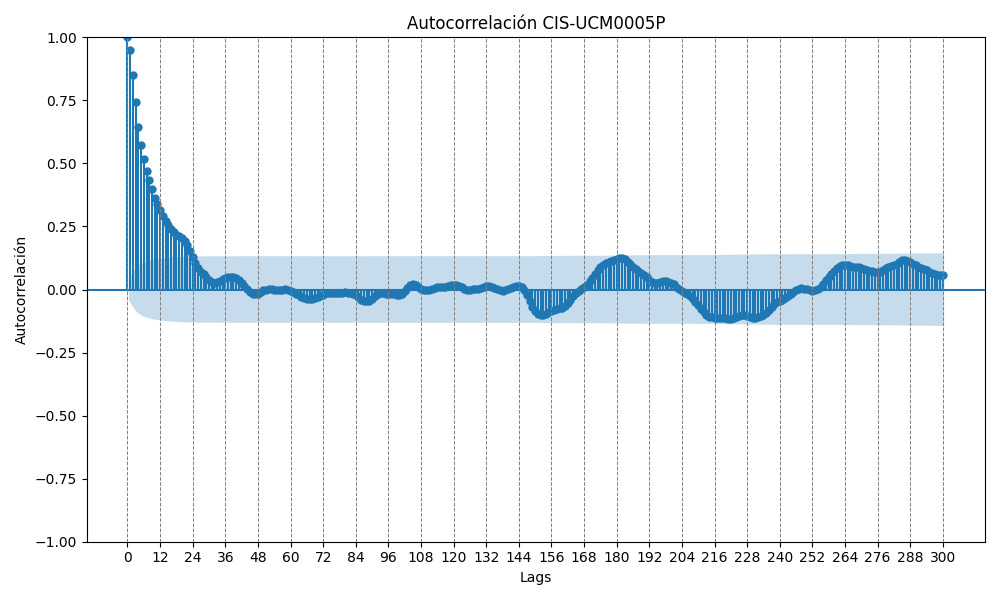

[OK] Guardado: Analysis/Autocorrelación\CIS-UCM0005P_autocorrelacion.png


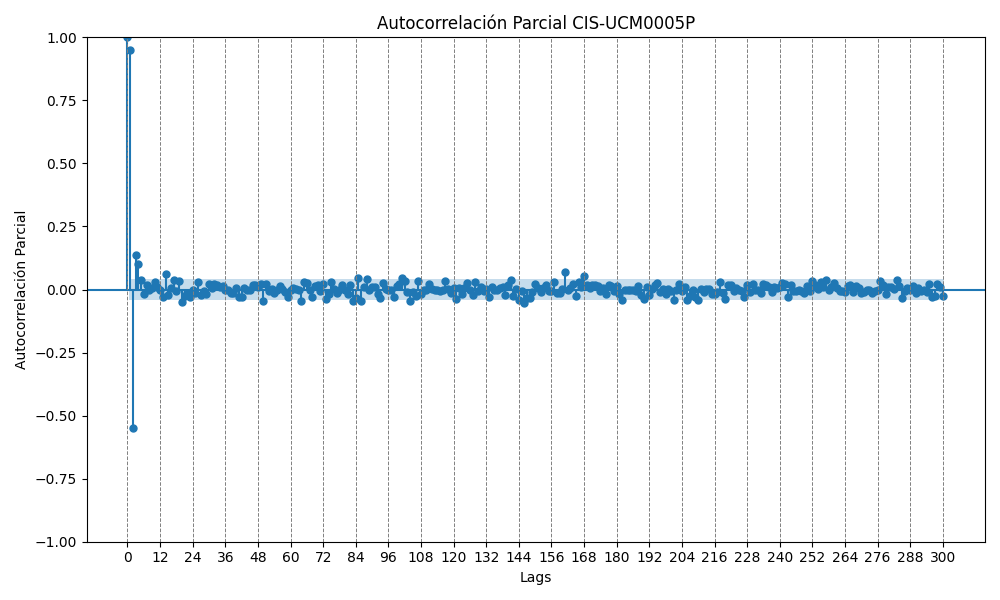

[OK] Guardado: Analysis/Autocorrelación Parcial\CIS-UCM0005P_autocorrelacion_parcial.png

Procesando CIS-UCM0006P.csv...


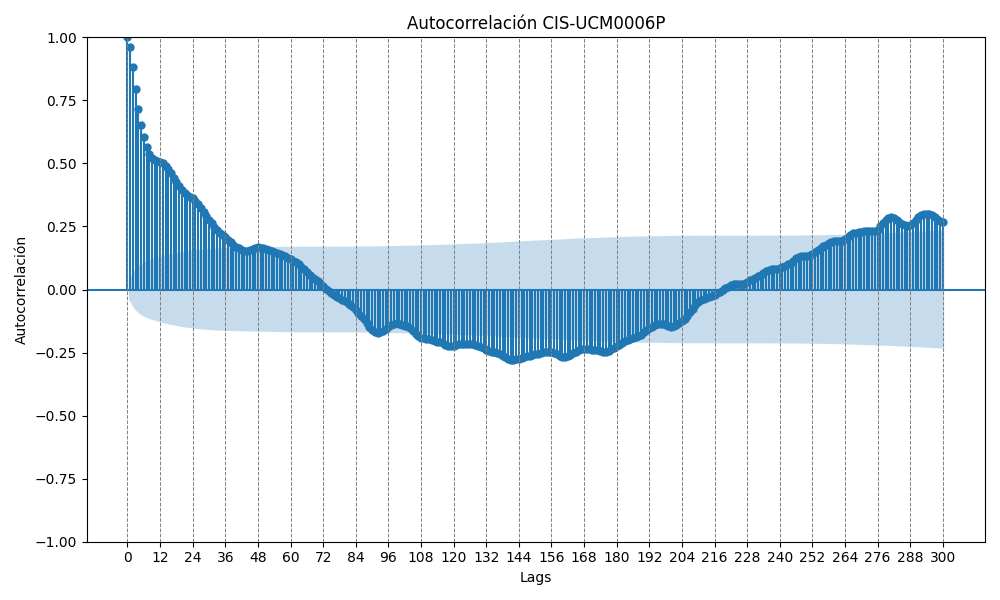

[OK] Guardado: Analysis/Autocorrelación\CIS-UCM0006P_autocorrelacion.png


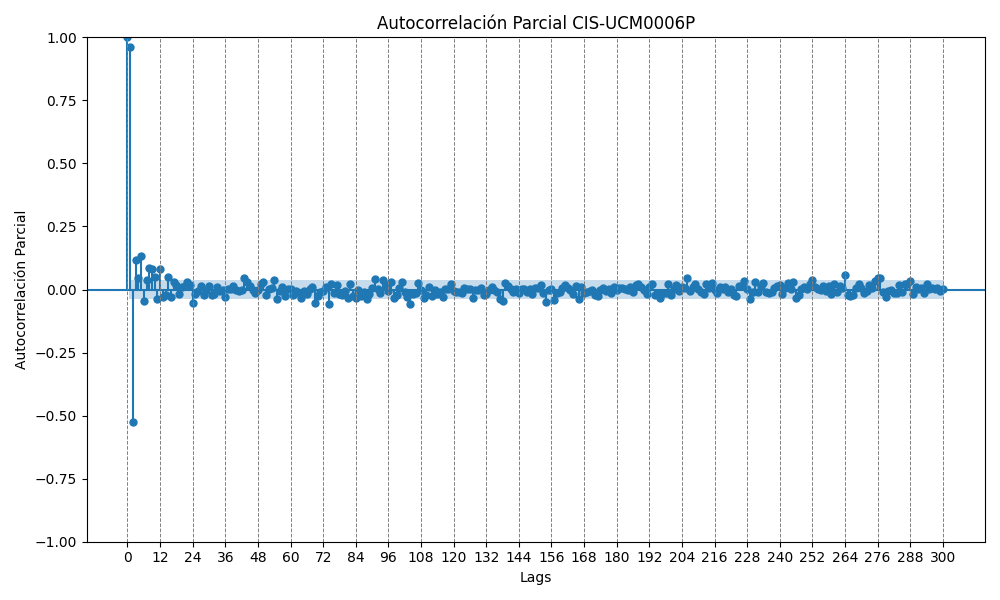

[OK] Guardado: Analysis/Autocorrelación Parcial\CIS-UCM0006P_autocorrelacion_parcial.png

Procesando CIS-UCM0007P.csv...


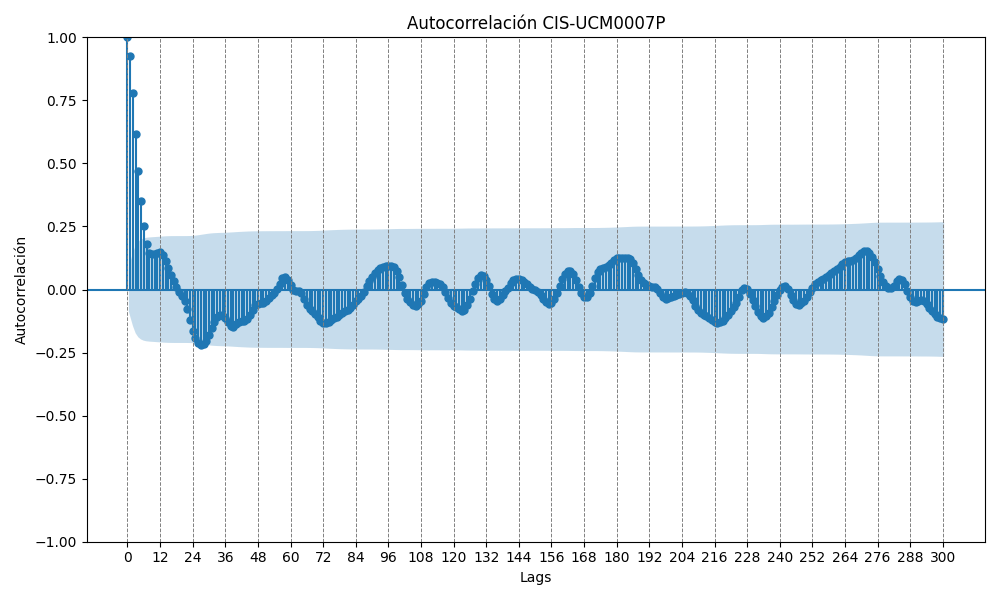

[OK] Guardado: Analysis/Autocorrelación\CIS-UCM0007P_autocorrelacion.png
Error procesando el archivo CIS-UCM0007P.csv: Can only compute partial correlations for lags up to 50% of the sample size. The requested nlags 300 must be < 250.

Procesando U10.csv...


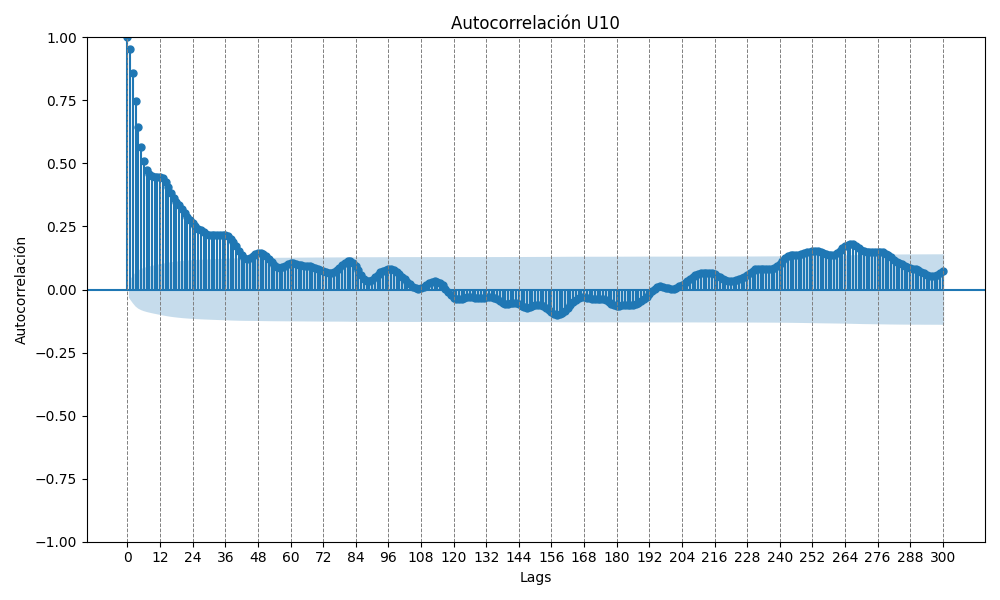

[OK] Guardado: Analysis/Autocorrelación\U10_autocorrelacion.png


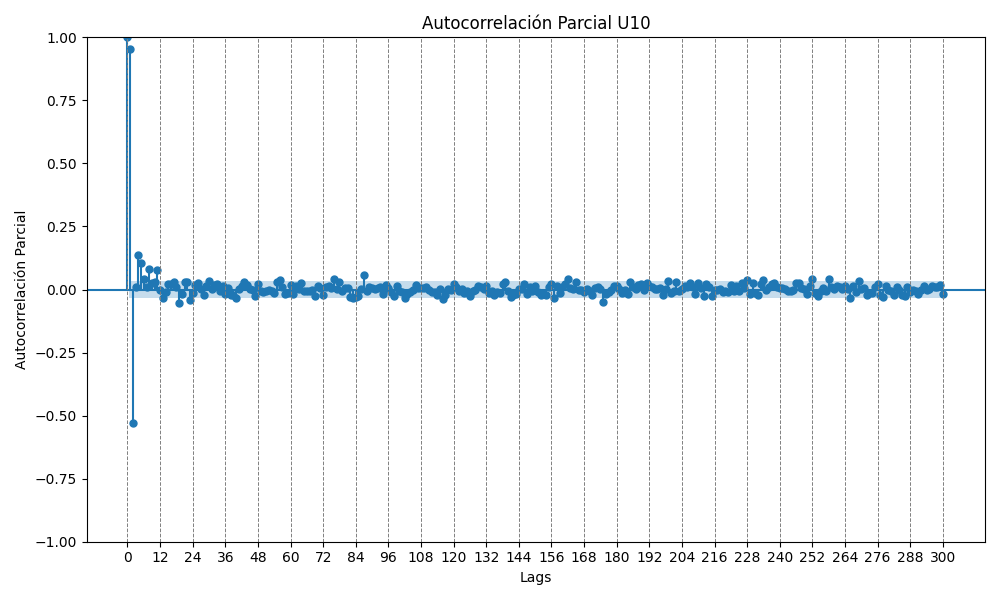

[OK] Guardado: Analysis/Autocorrelación Parcial\U10_autocorrelacion_parcial.png

Procesando U12.csv...


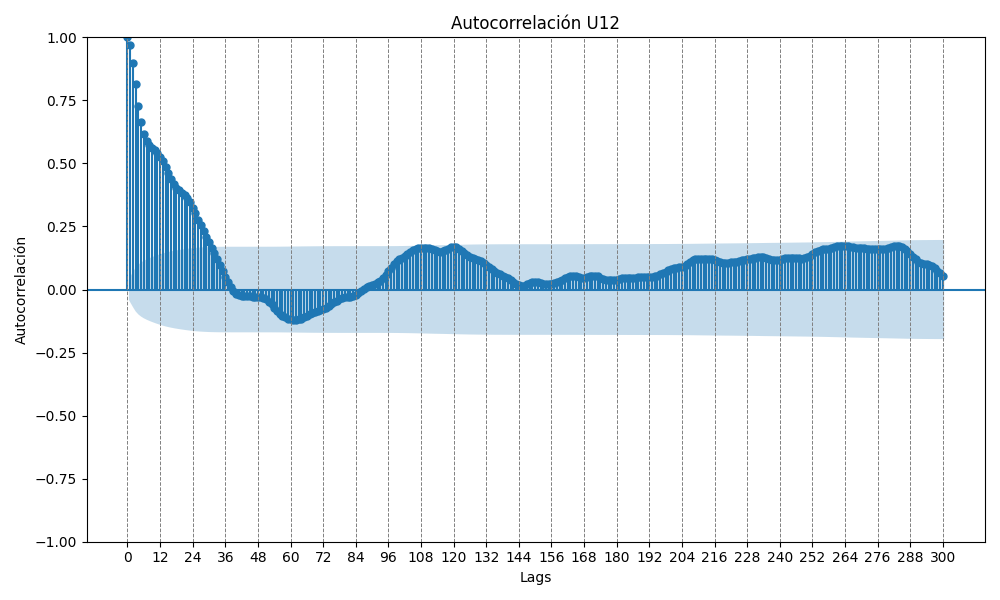

[OK] Guardado: Analysis/Autocorrelación\U12_autocorrelacion.png


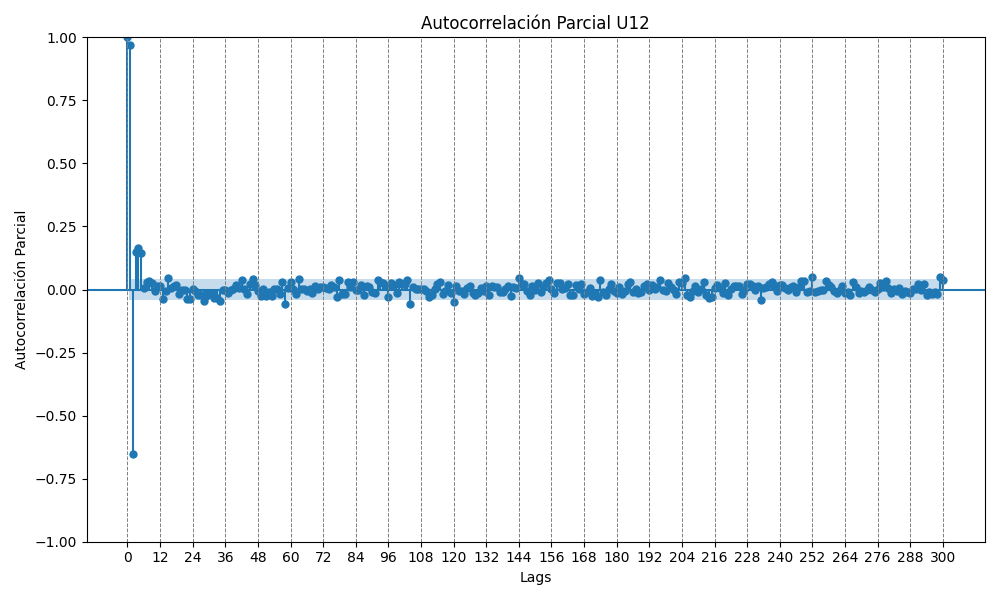

[OK] Guardado: Analysis/Autocorrelación Parcial\U12_autocorrelacion_parcial.png


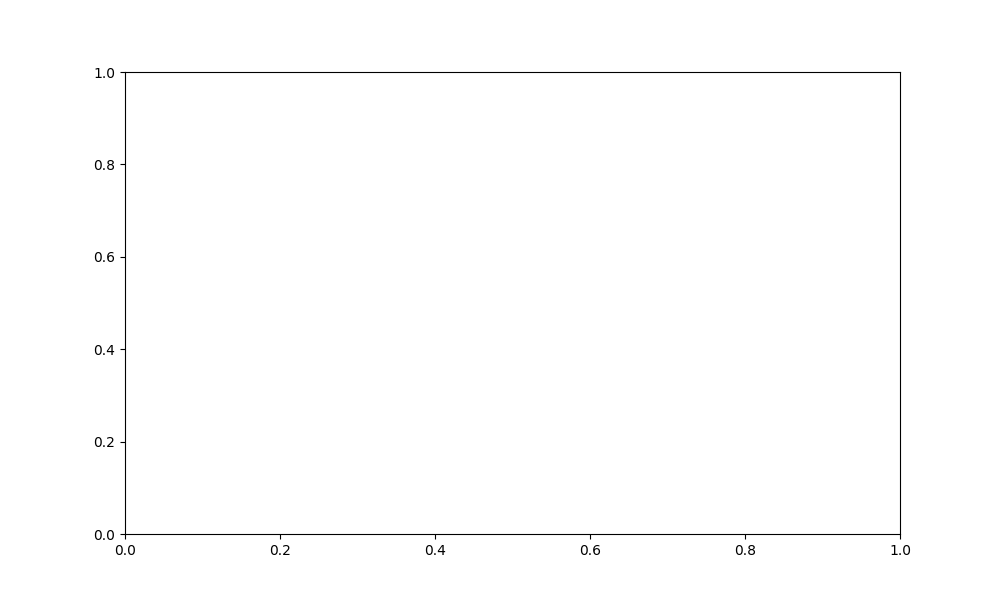

In [27]:
def main():
    carpeta_archivos = r'Data\Trusted\Completos'
    procesar_archivos(carpeta_archivos)

if __name__ == "__main__":
    main()

In [28]:
plt.close('all')

Debemos tener en cuenta que cada lag representa 5 minutos y que se visualiza un día completo más un pequeño margen (288 lags ≈ 24 horas):

---

1. **Comportamiento general**
    En todos los gráficos, la autocorrelación comienza en 1 (como es esperable), y luego cae rápidamente en los primeros lags, 1-2 horas (12-24 lags de 5 minutos), con oscilaciones débiles posteriores. Esto indica un patrón común de fuerte dependencia temporal a corto plazo: los valores cercanos en el tiempo están fuertemente correlacionados, lo que es típico en series fisiológicas o de actividad. 

    Existe cierta similitud entre CIS-UCM0006P y U10. Se aprecia que ambos comparten un patrón de decaimiento relativamente gradual en los primeros lags, con menor número de coeficientes fuera de las bandas de confianza en U10; es decir, U10 se parece en forma a CIS-UCM0006P, pero con menor “persistencia significativa”. Si destacamos a CIS-UCM0006P por su persistencia y tramos negativos recuperando después; esta cualidad también está presente en U10, aunque más atenuada. Por tanto, CIS-UCM0006P y U10 muestran patrones parecidos, coherentes con memoria algo más persistente que en otros sujetos, con U10 menos marcado.

    No hay una presencia clara de picos dominantes en el lag 288 (24 horas), de estacionalidad diaria marcada. Sin embargo, hay indicios débiles de periodicidad circadiana en algunos sujetos en los que podemos apreciar coeficientes reseñables en sus ACF en las vecindades de ese lag. Esto son indicios débiles de periodicidad diaria, o de resonancias a escalas cercanas.

    Existen diferencias interindividuales, lo que sugiere realizar la modelización por participante.

---

2. **Descomposición de patrones**

    1. **CIS-UCM0005P**
        - **Caída rápida en ACF**: En las primeras 1-2 horas (12-24 lags), la autocorrelación cae rápidamente de 1 a cerca de 0, lo que sugiere que la memoria del sistema es corta (los valores se parecen mucho solo en el corto plazo).
        - **Oscilaciones suaves en ACF**: Después de la caída, la autocorrelación oscila ligeramente alrededor de cero, con algunos picos positivos y negativos, pero en general se mantiene dentro de los intervalos de confianza (zona azul), sin picos dominantes en 24 joras. Esto indica ausencia de ciclos diarios claros, es decir, ausencia de estacionalidad diaria fuerte, aunque puede haber cierta tendencia o ruido estructurado.
        - **PACF**: Hay cortes tempranos compatibles con términos AR de bajo orden. 
        - **Implicación**: modelos ARMA/ARIMA parsimoniosos (p,q pequeños), d∈{0,1}. El espectro no revela picos circadianos dominantes (confirmación de que no procede imponer un SARIMA diario salvo evidencia adicional).

    2. **CIS-UCM0006P**
        - **Caída lenta y valores negativos en ACF**: Tras la caída inicial, la autocorrelación se vuelve negativa durante varias horas seguido de una recuperación donde vuelve a subir, incluso llegando a valores positivos significativos al final del día. Esto puede indicar la presencia de un ciclo o patrón más largo, posiblemente relacionado con ritmos circadianos o actividades repetitivas a lo largo del día.
        - **Mayor persistencia en ACF**: El hecho de que la autocorrelación no se estabilice cerca de cero sugiere que hay una estructura temporal más fuerte o un componente periódico. Esto apunta a estructuras de mediano plazo o polos/ceros complejos; posible AR(p) con raíces cercanas a la frontera de estabilidad o componentes MA que generen sobreoscilación.
        - **PACF**: Sugiere explorar órdenes algo mayores (p,q hasta 2–3).
        - **Implicación**: Probar ARMA(2,1)/ARIMA con d mínimo compatible con ADF/KPSS. El espectro debe revisarse para identificar energía a frecuencias ultradianas (2–6 h); si se confirma, justificar términos AR con polos complejos (p≥2).

    3. **CIS-UCM0007P**
        - **Oscilaciones periódicas en ACF**: Se observan oscilaciones más marcadas y periódicas, alternando entre valores positivos y negativos, con amplitud moderada aunque no superan mucho los intervalos de confianza. Esto podría indicar la presencia de ciclos ultradianos (más cortos que 24h) o patrones de actividad/descanso repetidos. Es un patrón compatible con pares complejos débiles.
        - **PACF**: No se puede realizar al haber un tamaño muestral únicamente de dos días.
        - **Implicación**: Candidatos AR(2)–AR(3) o ARMA(2,1). Evitar sobreparametrización. 

    4. **U10**
        - **Caída lenta y valores negativos en ACF**: Patrón similar a CIS-UCM0006P pero con menos significancias fuera de bandas de confianza. Tras la caída inicial, la autocorrelación se vuelve negativa durante varias horas seguido de una recuperación donde vuelve a subir, incluso llegando a valores positivos significativos al final del día. Esto puede indicar la presencia de un ciclo o patrón más largo, posiblemente relacionado con ritmos circadianos o actividades repetitivas a lo largo del día.
        - **Oscilaciones suaves**: Después de la caída, la autocorrelación oscila ligeramente alrededor de cero, con algunos picos positivos y negativos, pero en general se mantiene dentro de los intervalos de confianza. Esto indica que puede haber cierta tendencia o ruido estructurado.
        - **Mayor persistencia en ACF**: El hecho de que la autocorrelación no se estabilice cerca de cero sugiere que hay una estructura temporal más fuerte o un componente periódico. Esto apunta a estructuras de mediano plazo o polos/ceros complejos; posible AR(p) con raíces cercanas a la frontera de estabilidad o componentes MA que generen sobreoscilación.
        - **PACF**: Cortes tempranos, coherente con ARMA de orden bajo y d pequeño.
        - **Implicación**: ARIMA(p,d,q) con p,q ∈ {0,1,2} y d∈{0,1} (preferiblemente 0 si ADF/KPSS lo avalan); la evidencia no avala estacionalidad diaria fuerte.

    5. **U12**
        - **Caída rápida**: En las primeras 1-2 horas (12-24 lags), la autocorrelación cae rápidamente de 1 a cerca de 0, lo que sugiere que la memoria del sistema es corta (los valores se parecen mucho solo en el corto plazo).
        - **Oscilaciones suaves**: Después de la caída, la autocorrelación oscila ligeramente alrededor de cero, con algunos picos positivos y negativos, pero en general se mantiene dentro de los intervalos de confianza (zona azul). Esto indica ausencia de ciclos diarios claros, aunque puede haber cierta tendencia o ruido estructurado.
        - **PACF**: Cortes tempranos, coherente con ARMA de orden bajo y d pequeño.
        - **Implicación**: ARIMA(p,d,q) con p,q ∈ {0,1,2} y d∈{0,1}; la evidencia no avala estacionalidad diaria fuerte.

---

3. **Interpretación práctica**
    - **No hay estacionalidad diaria clara**: Ninguno de los gráficos muestra un pico fuerte en el lag 288 (24h), lo que sería indicativo de una fuerte periodicidad diaria.
    - **Patrones de corto plazo**: La mayor parte de la autocorrelación significativa ocurre en los primeros 1-2 horas, lo que sugiere que los valores recientes son los que más influyen en el presente.
    - **Posibles ciclos intermedios**: En algunos sujetos (especialmente CIS-UCM0006P y CIS-UCM0007P), hay indicios de ciclos de varias horas, pero no son lo suficientemente fuertes como para ser considerados ritmos circadianos puros.

---

4. **Conclusión**
    - Las series presentan memoria de corto plazo, con alguna estructura de mediano plazo en ciertos casos.
    - No hay evidencia de ciclos diarios robustos, pero sí posibles patrones de varias horas.
    - Si buscamos estacionalidad diaria o patrones circadianos, sería recomendable analizar más días o aplicar transformaciones adicionales (por ejemplo, descomposición estacional o espectral).

---

5. **Implicaciones para la modelización**
    La caída rápida en la autocorrelación indica memoria corta y justifica componentes AR/MA de bajo orden como punto de partida para cada sujeto, en todos los casos, la parsimonia en p y q es recomendable. 

    La ausencia de picos claros en el lag 288 (correspondiente a las 24 horas) sugiere que la estacionalidad diaria, si existe, sólo estaría justificada tras contrastes adicionales. En caso de estacionalidad diaria detectada posteriormente (por picos en ACF/PACF a múltiplos de s), se justificaría una parte SARIMA con D>0; d se determina empíricamente con ADF/KPSS y se mantiene en 0–1.
    La componente estacional diaria débil mostrada en algunos usuarios no justifica imponer SARIMA con D>0 a ciegas, pero sí comprobar con el análisis espectral (periodograma) si hay energía apreciable cerca de 1/24, y en caso de ver indicio consistente, probar una variante SARIMA con s=288, D=0 o 1, pero parsimoniosa, y compararla objetivamente por AIC/BIC y validación temporal frente a un ARIMA no estacional.

    Las diferencias entre participantes (persistencia más lenta y valores negativos intermedios en CIS-UCM0006P, oscilaciones más marcadas en CIS-UCM0007P...) apoyan la idea de modelos por sujeto frente a un único modelo global.

#### C2.2 Periodograma

**Finalidad**: El periodograma y el espectro de Welch por subserie permiten corroborar la ausencia o presencia de picos circadianos dominante (~1/24 h^-1) y detectar picos ultradianos (2–6 h) que expliquen oscilaciones observadas en ACF (por ejemplo antes de imponer SARIMA estacional). 

El periodograma clásico es un estimador no suavizado de la densidad espectral de potencia; presenta alta varianza punto a punto.
Estima la densidad espectral de potencia (PSD) a partir de la transformada discreta de Fourier de la serie. Muestra cuánta “energía” hay en cada frecuencia. Para muestreo a 5 minutos, es natural reportar la frecuencia en ciclos por hora (cph) o ciclos por día.

**Implicación**: En ausencia de energía concentrada a 24 h, evitar SARIMA con s=288 y D>0. 
La presencia de picos ultradianos justificaría modelos AR con polos complejos (AR(2)–AR(3)) y/o incorporar marcadores de ejercicio/post-ejercicio como covariables exógenas (ARIMAX).

En los usuarios con picos cercanos al lag 288, verificar con análisis espectral: si hay energía acumulada alrededor de la frecuencia 1/24 h, aunque no sea un pico agudo, puede ser razonable evaluar SARIMA con s=288 y D=0 (o D=1 sólo si hay estacionalidad clara en la media) y compararlo por AIC/BIC y validación temporal contra ARIMA sin estacionalidad. Esto alinearía la idea intuitiva inicial con una comprobación cuantitativa posterior.

**Método de Welch**: El método de Welch divide la serie en segmentos (posiblemente solapados), calcula periodogramas por segmento y los promedia. Esto reduce la varianza del estimador a costa de una menor resolución en frecuencia. Esto suaviza el ruido del periodograma y ayuda a distinguir picos reales de fluctuaciones aleatorias.
Para señales fisiológicas ruidosas, Welch da una visión más estable de dónde está la energía espectral, reduciendo el riesgo de sobreinterpretar picos espurios del periodograma. Es un complemento muy útil.

Si se sospecha periodicidad diaria débil, Welch dará una visión más estable: si hay energía consistente cerca de 1/24 h^-1, aparecerá como un pico que se mantiene pese al suavizado. Si solo es ruido, tenderá a diluirse. Es una validación objetiva antes de añadir complejidad estacional al modelo.

In [29]:
def calcular_periodograma(g, fs_per_hour=12.0):
    x = g.values - np.mean(g.values)
    n = len(x)
    X = rfft(x, n=n)
    Pxx = (1.0 / n) * np.abs(X) ** 2
    freqs = rfftfreq(n, d=1.0)
    freqs_cph = freqs * fs_per_hour
    return freqs_cph, Pxx

def calcular_welch(g, fs_per_hour=12.0, nperseg=None, noverlap=None, window="hann"):
    x = g.values - np.mean(g.values)
    fs = fs_per_hour
    f, Pxx = welch(x, fs=fs, window=window, nperseg=nperseg, noverlap=noverlap, detrend="constant")
    return f, Pxx

def graficar_espectro(freqs_cph, P_per, f_welch, P_welch, nombre_base, out_dir='Analysis/Periodograma'):
    os.makedirs(out_dir, exist_ok=True)
    plt.figure(figsize=(10, 6))
    plt.semilogy(freqs_cph, P_per, color="tab:blue", alpha=0.6, label="Periodograma")
    plt.semilogy(f_welch, P_welch, color="tab:orange", alpha=0.8, label="Welch")
    marcas = [1.0/24.0, 1.0/12.0, 1.0/6.0, 1.0/3.0, 0.5, 1.0, 2.0]
    for m in marcas:
        plt.axvline(m, color="gray", linestyle="--", linewidth=0.8, alpha=0.7)
    plt.xlim(0, 3.0)
    plt.xlabel("Frecuencia (ciclos/hora)")
    plt.ylabel("Densidad espectral de potencia (escala log)")
    plt.title(f"Espectro (Periodograma y Welch) - {nombre_base}")
    plt.legend()
    plt.tight_layout()
    filename = os.path.join(out_dir, f"periodograma_{nombre_base}.png")
    plt.savefig(filename, dpi=300)
    print(f"[OK] Guardado: {filename}")

def procesar_archivos(carpeta_archivos, fs_per_hour=12.0, nperseg_welch=None, noverlap_welch=None):
    for archivo in os.listdir(carpeta_archivos):
        if archivo.endswith('.csv'):
            ruta_archivo = os.path.join(carpeta_archivos, archivo)
            try:
                df = pd.read_csv(ruta_archivo, parse_dates=['time'])
                print(f"\nProcesando {archivo}...")
                g = df['glucose'].astype(float)
                g = g[(~g.isna()) & (g != 0)]
                t = df['time'].loc[g.index]
                serie = pd.Series(g.values, index=t).sort_index().dropna()
                if len(serie) < 24:
                    print(f"[WARN] Muy pocos datos válidos en {archivo}")
                    continue
                freqs_cph, P_per = calcular_periodograma(serie, fs_per_hour=fs_per_hour)
                f_welch, P_welch = calcular_welch(serie, fs_per_hour=fs_per_hour, nperseg=nperseg_welch, noverlap=noverlap_welch)
                nombre_base = os.path.splitext(archivo)[0]
                graficar_espectro(freqs_cph, P_per, f_welch, P_welch, nombre_base)
            except Exception as e:
                print(f"Error procesando el archivo {archivo}: {e}")


Procesando CIS-UCM0005P.csv...
[OK] Guardado: Analysis/Periodograma\periodograma_CIS-UCM0005P.png

Procesando CIS-UCM0006P.csv...
[OK] Guardado: Analysis/Periodograma\periodograma_CIS-UCM0006P.png

Procesando CIS-UCM0007P.csv...
[OK] Guardado: Analysis/Periodograma\periodograma_CIS-UCM0007P.png

Procesando U10.csv...
[OK] Guardado: Analysis/Periodograma\periodograma_U10.png

Procesando U12.csv...
[OK] Guardado: Analysis/Periodograma\periodograma_U12.png


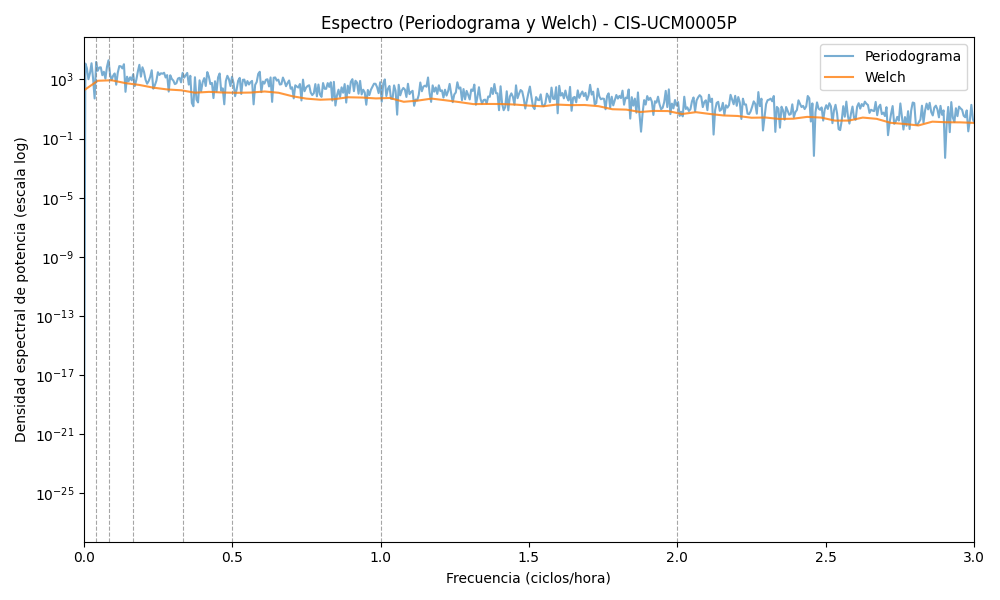

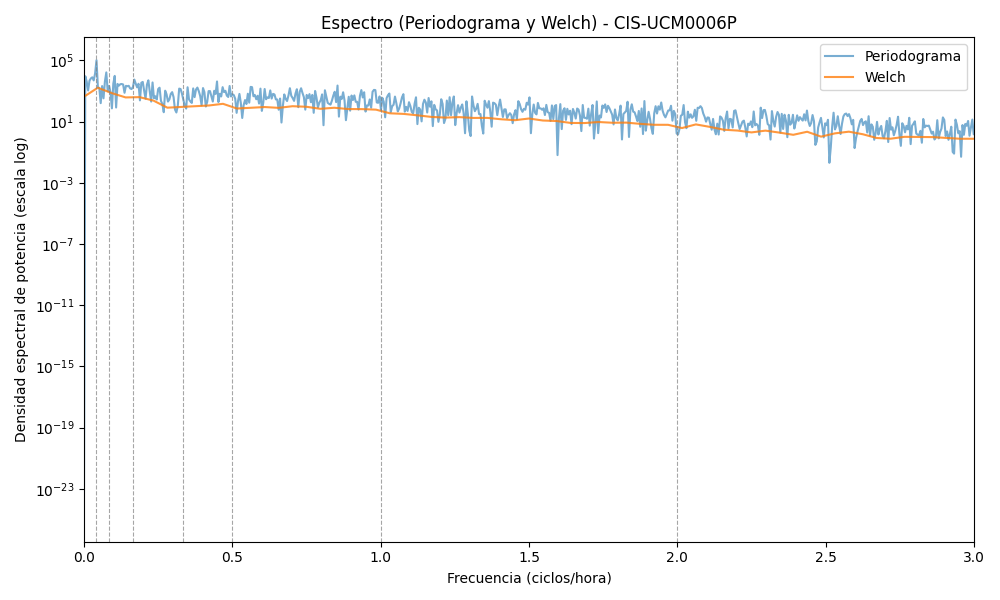

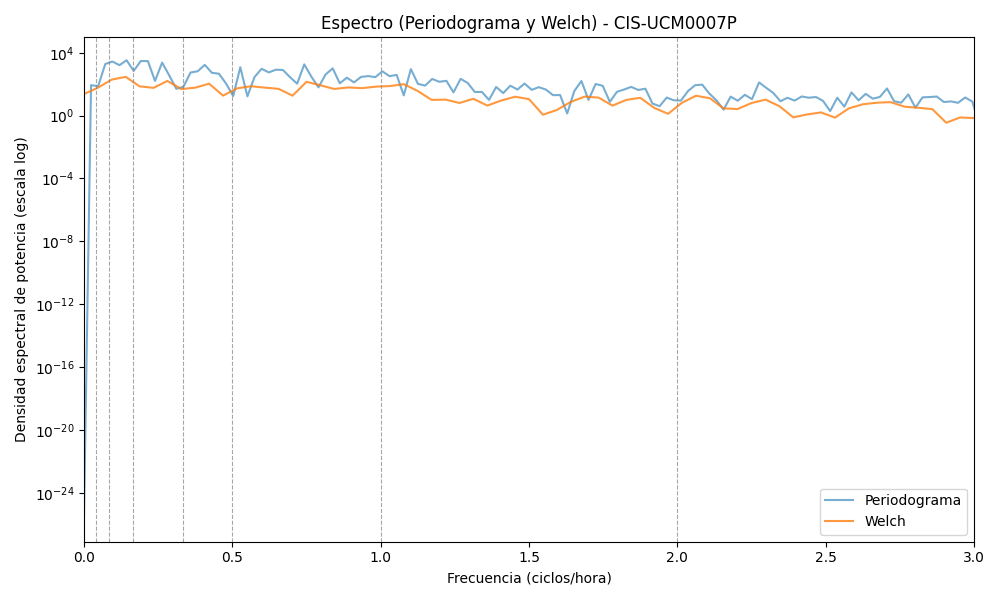

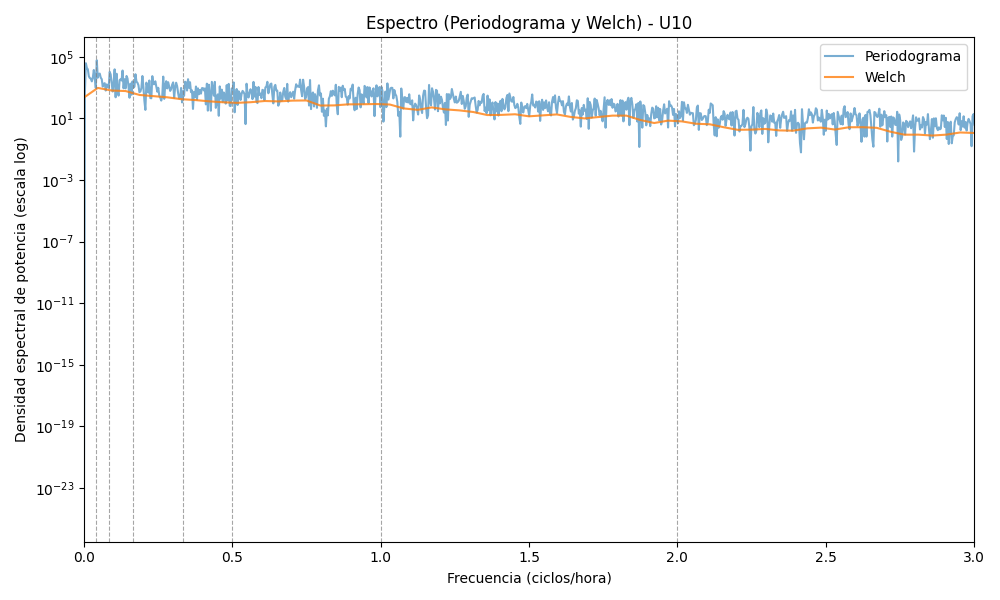

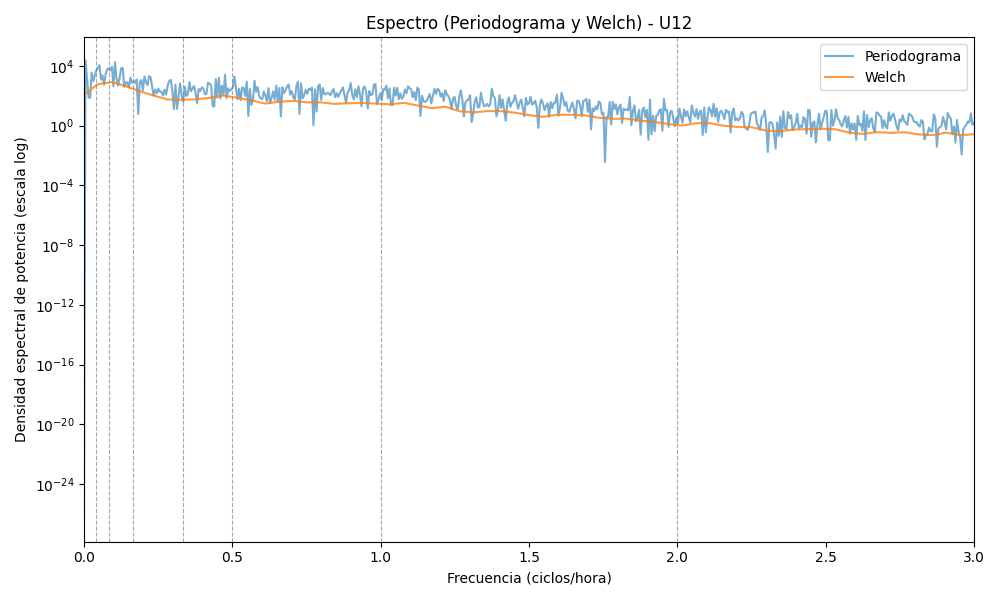

In [30]:
def main():
    carpeta_archivos = r'Data\Trusted\Completos'
    procesar_archivos(carpeta_archivos)

if __name__ == "__main__":
    main()

In [31]:
plt.close('all')

**Conclusiones generales**:

No aparece un pico estrecho y dominante en 1/24 cph (≈0.0417 cph). 
La curva de Welch (naranja), que es una estimación de menor varianza, cae suavemente desde frecuencias muy bajas y no marca resonancias agudas en el vecindario circadiano. 
Esto respalda que no existe una estacionalidad diaria fuerte y estable en glucosa para estas series; por tanto, no es recomendable imponer a priori un SARIMA con s=288 y D>0.

Espectro de tipo “red noise” o 1/f^α: hay mayor potencia en frecuencias bajas y un declive progresivo hacia frecuencias más altas. 
Ese patrón es coherente con la ACF que decae de forma relativamente rápida pero no instantánea: dependencia a corto plazo con algo de persistencia suave. Modelísticamente avala ARMA/ARIMA de bajo orden con d pequeño (0 o, si lo piden ADF/KPSS en alguna subserie, 1).

---

**Resultados por usuario**:

1. CIS-UCM0005P: 
    - Welch desciende casi monótonamente sin picos destacados ni hombros pronunciados. 
    - Indicio: dinámica predominantemente de corto plazo. Con lo observado antes en ACF/PACF, mantiene la recomendación de ARIMA parsimonioso (p,q en {0,1,2}), d=0 salvo que ADF/KPSS en alguna subserie puntual pidan d=1.
    - Mantener enfoque parsimonioso; no proponer SARIMA diario.
2. CIS-UCM0006P: 
    - Potencia más alta en muy baja frecuencia y descenso más gradual que en otros; sugiere persistencia relativamente mayor. No hay pico circadiano neto, pero el “hombro” a bajas frecuencias es compatible con lo que veíamos en ACF (caída más lenta, tramos negativos y recuperación). 
    - Implicación: explorar ARMA con p algo mayor que en otros (p,q hasta 2–3) y confirmar con AIC/BIC. Si en algunas subseries la Welch muestra un leve realce en 0.1–0.2 cph (periodos 5–10 h), puede justificarse un AR(2) con polos complejos.´
    - El espectro de Welch confirma potencia elevada a muy baja frecuencia y ausencia de pico circadiano nítido; justifica explorar p hasta 2–3, y pares complejos si aparecen hombros 5–10 h
3. CIS-UCM0007P: 
    - Espectro relativamente más “plano” dentro del rango hasta 3 cph, sin resonancias nítidas. Consistente con ACF de oscilaciones moderadas pero sin periodicidad estable. 
    - Recomendación: AR(2)–AR(3) o ARMA(2,1) como candidatos iniciales; d=0 salvo evidencia puntual.
    - Mantener enfoque parsimonioso; no proponer SARIMA diario.
4. U10: 
    - Muy parecido a CIS-UCM0006P en forma global: potencia alta a baja frecuencia y caída progresiva; Welch suave sin picos circadianos. Coincide con tu percepción de similitud (ACF de morfología pareja pero con menos barras significativas en U10). 
    - Implicación: probar la misma rejilla parsimoniosa que en 0006P, dejando que AIC/BIC y residuos decidan.
    - Similitud a CIS-UCM0006P pero con “señal más limpia”; recomendar p,q en {0,1,2} como base, comprobar p=2 si ACF/PACF lo sugiere y el espectro muestra leve realce ultradiano.
5. U12: 
    - Perfil intermedio: potencia notable en baja frecuencia y descenso visible; sin picos agudos en circadiano. 
    - Igual que en 0005P, preferencia por ARIMA de bajo orden; d=0 en general.
    - Mantener enfoque parsimonioso; no proponer SARIMA diario.

---

**Conclusiones**:

El periodograma y el espectro de Welch muestran potencia dominante en bajas frecuencias y ausencia de un pico estrecho en 1/24. Esto sugiere que la glucosa intersticial presenta dependencia de corto plazo con persistencia suave y que no existe una estacionalidad diaria robusta. En consecuencia, priorizamos modelos ARIMA/ARMA de bajo orden y consideraríamos SARIMA diario sólo exploratoriamente si una serie concreta presentara evidencia reforzada.

Sobre el “indicio circadiano” que veíamos en lags cercanos a 288 en algunos usuarios: a la luz de estos espectros, no hay refuerzo claro. 
Aunque se aprecian leves elevaciones en lags próximos a 24 h, el análisis espectral no las respalda como una periodicidad diaria estable, pues no se traducen en picos espectrales robustos; por tanto, las consideramos fluctuaciones no periódicas (o, en todo caso, periodicidades no estables) y no justifican incluir un término estacional diario en los modelos base.

Las diferencias entre sujetos (p. ej., mayor energía de muy baja frecuencia en CIS-UCM0006P y U10) son coherentes con la caída de ACF más lenta en esos casos; esto justifica explorar p algo mayores (hasta 2–3) o pares complejos en AR.

Dado el patrón espectral y la ACF de memoria corta, d=0 debería ser la opción por defecto. 
Si alguna subserie concreta tuvo ADF que no rechaza raíz unitaria y KPSS que rechaza estacionariedad, aplicar d=1 únicamente en esa subserie. 
Evitar d>1.

### C3. Estacionariedad

Dado el patrón observado en ACF, es razonable esperar no estacionariedad débil (tendencias suaves/ruido coloreado).

Si ADF no rechaza H0 y/o KPSS rechaza H0, corresponde aplicar diferenciación (∇^d) para lograr estacionariedad en media antes de ajustar modelos ARMA; esto se traduce en ARIMA(p,d,q) con d mínimo que estabilice la serie.
Si ADF rechaza y KPSS no rechaza, no se diferencia.
En casos ambiguos, se decide observando ACF/PACF de la serie (y, si es necesario, de la diferenciada) y la estabilidad de la media.

En glucosa intersticial es infrecuente requerir d>1.

#### C3.1 Pruebas de Dickey-Fuller aumentada (ADF) y Kwiatkowski.Phillips-Schmidt-Shin (KPSS)

Prueba ADF (Augmented Dickey-Fuller)
Objetivo: Determinar si una serie temporal tiene una raíz unitaria, lo que implica que no es estacionaria.
Estacionariedad: Una serie es estacionaria si sus propiedades estadísticas (media, varianza) no cambian a lo largo del tiempo. Esto es importante porque muchas técnicas de análisis de series temporales asumen que los datos son estacionarios.
Hipótesis:
  - Hipótesis nula (H0): La serie tiene una raíz unitaria (no es estacionaria).
  - Hipótesis alternativa (H1): La serie no tiene una raíz unitaria (es estacionaria).
Interpretación: Si el p-valor es bajo (por ejemplo, menos de 0.05), se rechaza la hipótesis nula, sugiriendo que la serie es estacionaria. La prueba es especialmente útil para detectar tendencias a largo plazo.

Resumen prueba ADF: Evalúa si la serie tiene una raíz unitaria (no es estacionaria).

---

Prueba KPSS (Kwiatkowski-Phillips-Schmidt-Shin)
Objetivo: Evaluar si una serie temporal es estacionaria en torno a una media o una tendencia determinista.
Hipótesis:
  - Hipótesis nula (H0): La serie es estacionaria.
  - Hipótesis alternativa (H1): La serie no es estacionaria.
Interpretación: Si el p-valor es bajo (por ejemplo, menos de 0.05), se rechaza la hipótesis nula, indicando que la serie no es estacionaria. Esta prueba es más sensible a la presencia de tendencias y estacionalidad.

Resumen prueba KPSS: Evalúa si la serie es estacionaria.

---

https://www.statsmodels.org/dev/examples/notebooks/generated/stationarity_detrending_adf_kpss.html

In [32]:
def adf_test(series):
    """
    Realiza el test de Dickey-Fuller aumentado (ADF) para comprobar la estacionariedad de una serie temporal.
    Filtra ceros y NaNs automáticamente.
    """
    series = series[(series != 0) & (~series.isna())]
    if len(series) < 3:
        return {
            'ADF Statistic': None,
            'p-value': None,
            'Critical Values': None,
            'Stationary': None,
            'Observaciones': 'No hay suficientes datos válidos para el test'
        }
    result = adfuller(series)
    return {
        'ADF Statistic': result[0],
        'p-value': result[1],
        'Critical Values': result[4],
        'Stationary': result[1] < 0.05
    }

def kpss_test(series):
    """
    Realiza el test KPSS para comprobar la estacionariedad de una serie temporal.
    Filtra ceros y NaNs automáticamente.
    """
    series = series[(series != 0) & (~series.isna())]
    if len(series) < 3:
        return {
            'KPSS Statistic': None,
            'p-value': None,
            'Critical Values': None,
            'Stationary': None,
            'Observaciones': 'No hay suficientes datos válidos para el test'
        }
    result = kpss(series, regression='c')
    return {
        'KPSS Statistic': result[0],
        'p-value': result[1],
        'Critical Values': result[3],
        'Stationary': result[1] > 0.05
    }

def analyze_files(folder_path, variable='glucose'):
    """
    Analiza la estacionariedad de una variable en todos los archivos CSV de una carpeta usando ADF y KPSS,
    filtrando ceros y NaNs automáticamente.
    """
    results = {}
    for file in os.listdir(folder_path):
        if file.endswith('.csv'):
            df = pd.read_csv(os.path.join(folder_path, file))
            if variable in df.columns:
                adf_result = adf_test(df[variable])
                kpss_result = kpss_test(df[variable])
                results[file] = {
                    variable: {
                        'ADF': adf_result,
                        'KPSS': kpss_result
                    }
                }
    return results

def create_results_table(results):
    # Crear una lista para almacenar los resultados
    data = []
    for file, result in results.items():
        glucose_adf = result['glucose']['ADF']
        glucose_kpss = result['glucose']['KPSS']
        file_name = file.replace('_', ' ').replace('.csv', '')
        data.append({
            'Archivo': file_name,
            'ADF Statistic': glucose_adf['ADF Statistic'],
            'ADF p-value': glucose_adf['p-value'],
            'ADF Estacionaria': glucose_adf['Stationary'],
            'KPSS Statistic': glucose_kpss['KPSS Statistic'],
            'KPSS p-value': glucose_kpss['p-value'],
            'KPSS Estacionaria': glucose_kpss['Stationary']
        })
    results_df = pd.DataFrame(data)
    return results_df

def format_value(value):
    """Formatea los valores para que sean más legibles."""
    if isinstance(value, bool):
        return "Sí" if value else "No"
    elif isinstance(value, float):
        return f"{value:.10f}"
    return value

def plot_results_as_image(results_df):
    fig, ax = plt.subplots(figsize=(10, len(results_df) * 0.5))
    ax.axis('tight')
    ax.axis('off')
    table = ax.table(cellText=[[format_value(cell) for cell in row] for row in results_df.values],
                     colLabels=results_df.columns,
                     cellLoc='center',
                     loc='center')
    table.auto_set_font_size(True)
    table.scale(1.3, 1.3)
    table.auto_set_column_width([0])
    for (i, j), cell in table.get_celld().items():
        if i == 0 or j == -1:
            cell.set_fontsize(10)
            cell.set_text_props(weight='bold')
        cell.set_edgecolor('black')
        cell.set_facecolor('white')
        cell.set_text_props(ha='center', va='center')
        cell.set_linewidth(0.5)
    plt.title('Resultados de Pruebas ADF y KPSS', fontsize=14)
    plt.show()

C:\Users\regin\AppData\Local\Temp\ipykernel_25496\1049538325.py:37: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression='c')
C:\Users\regin\AppData\Local\Temp\ipykernel_25496\1049538325.py:37: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression='c')
C:\Users\regin\AppData\Local\Temp\ipykernel_25496\1049538325.py:37: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is greater than the p-value returned.

  result = kpss(series, regression='c')


Resultados para CIS-UCM0005P.csv:
  glucose:
    ADF: {'ADF Statistic': -10.145354338803438, 'p-value': 8.213528981406305e-18, 'Critical Values': {'1%': -3.433192641654535, '5%': -2.8627958167698004, '10%': -2.5674385278825085}, 'Stationary': True}
    KPSS: {'KPSS Statistic': 0.4069846180484955, 'p-value': 0.07414456118599332, 'Critical Values': {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}, 'Stationary': True}
Resultados para CIS-UCM0006P.csv:
  glucose:
    ADF: {'ADF Statistic': -6.0135508718542505, 'p-value': 1.5528629564840376e-07, 'Critical Values': {'1%': -3.4329434877271816, '5%': -2.862685793891119, '10%': -2.567379949649765}, 'Stationary': True}
    KPSS: {'KPSS Statistic': 0.130781932646335, 'p-value': 0.1, 'Critical Values': {'10%': 0.347, '5%': 0.463, '2.5%': 0.574, '1%': 0.739}, 'Stationary': True}
Resultados para CIS-UCM0007P.csv:
  glucose:
    ADF: {'ADF Statistic': -6.827997497522298, 'p-value': 1.9257280861089078e-09, 'Critical Values': {'1%': -3.443549452

C:\Users\regin\AppData\Local\Temp\ipykernel_25496\1049538325.py:37: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  result = kpss(series, regression='c')


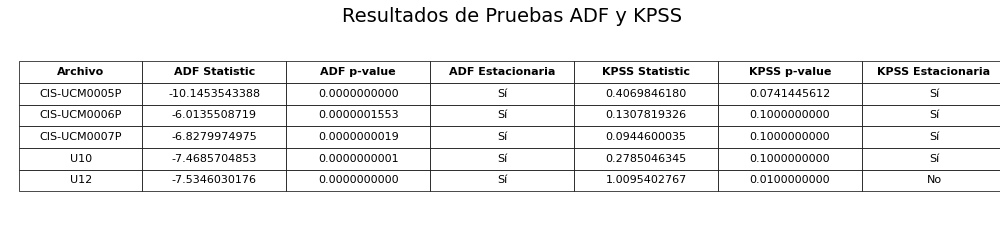

In [33]:
def main():
    folder_path = r'Data\Trusted\Completos'
    results = analyze_files(folder_path)
    for file, result in results.items():
        print(f'Resultados para {file}:')
        for variable, tests in result.items():
            print(f'  {variable}:')
            print(f'    ADF: {tests["ADF"]}')
            print(f'    KPSS: {tests["KPSS"]}')
    results_table = create_results_table(results)
    plot_results_as_image(results_table)

if __name__ == "__main__":
    main()

In [34]:
plt.close('all')

### C4. Correlación cruzada

Evalúa la relación entre dos series temporales desplazadas en el tiempo.

En el código que utilizamos, los lags se calculan automáticamente en función de la longitud de las series. Cuando utilizas la función correlate() de scipy, se generan lags que van desde -𝑁+1 hasta N-1, donde 𝑁 es la longitud de la serie más corta. Esto significa que se evalúa la correlación para todos los desfases posibles.

Interpretación de los Lags:

- Lags Negativos: Indican que la primera serie está adelantada respecto a la segunda. Por ejemplo, un lag de -2 significa que estás comparando la serie de glucemias en el tiempo t−2 con la serie de heart_rate en el tiempo 𝑡.
- Lags Positivos: Indican que la primera serie está retrasada respecto a la segunda. Un lag de +2 significa que estás comparando la serie de glucemias en el tiempo 𝑡 con la serie de heart_rate en el tiempo 𝑡+2.
- Lag 0: Representa la correlación en el mismo tiempo, es decir, cómo se relacionan las dos series en el mismo instante.

Para correlación cruzada necesitamos pares de series con el mismo índice temporal y paso de muestreo. Si mezclamos granularidades sin alinear, la CCF se distorsiona: los picos se atenúan, cambian de lag.

Recomendación: usar 5 minutos como set principal para inferencia (CCF, ACF/PACF, ARIMAX). Se puede añadir en un anexo una comparación en 1 minuto o datos completos con interpolación para comprobar robustez, dejando claro que es análisis exploratorio y que la glucosa está interpolada. Esto concilia rigor con sensibilidad.

Procesando 5 archivos en Data\Trusted\Agrupados...


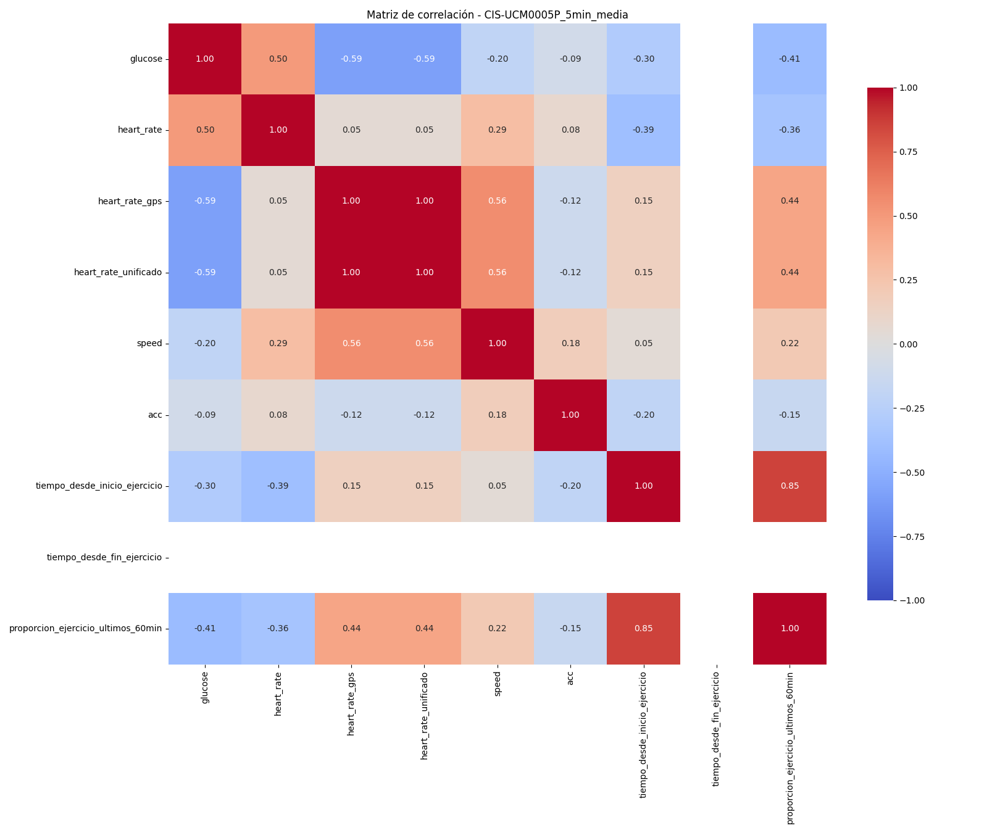

[OK] Guardado: Analysis\Correlación\matriz_correlacion_CIS-UCM0005P_5min_media.png


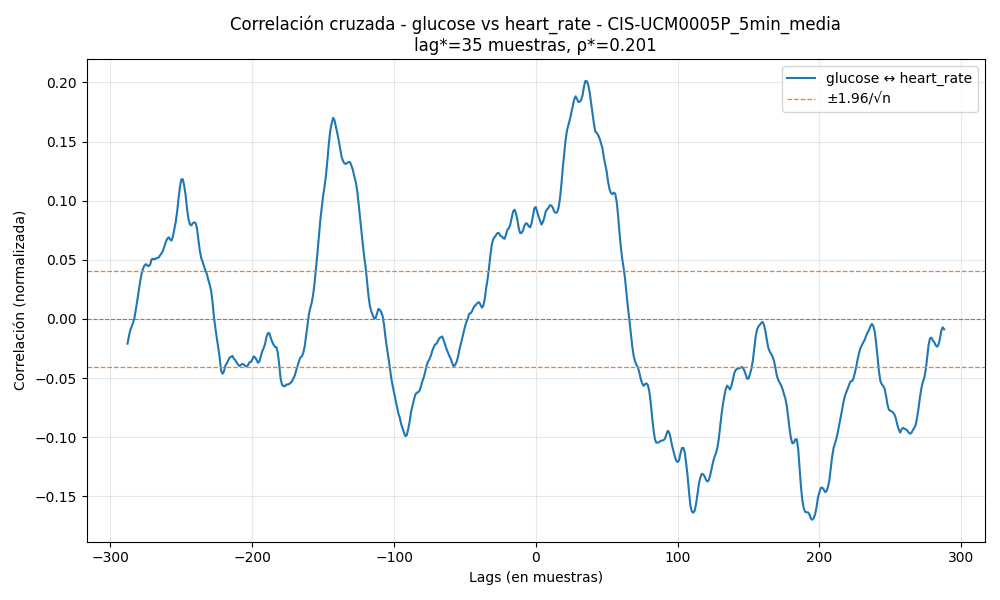

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_CIS-UCM0005P_5min_media.png


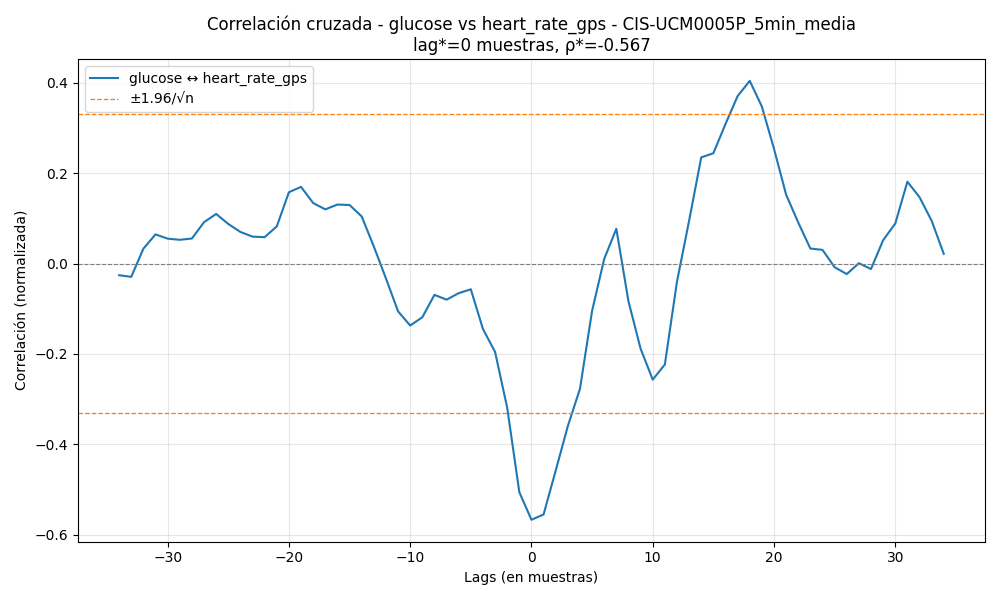

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_gps_CIS-UCM0005P_5min_media.png


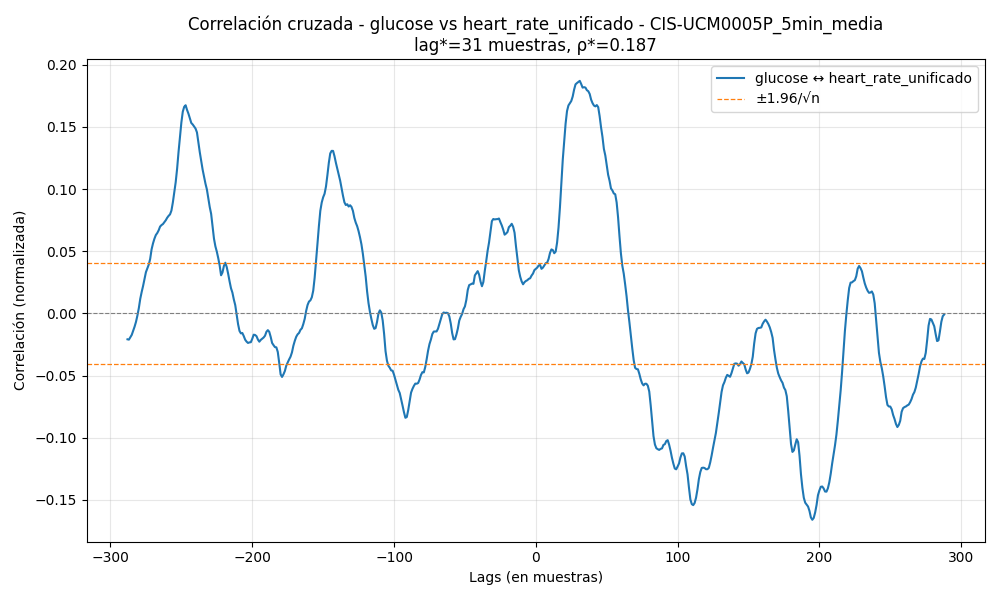

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_unificado_CIS-UCM0005P_5min_media.png


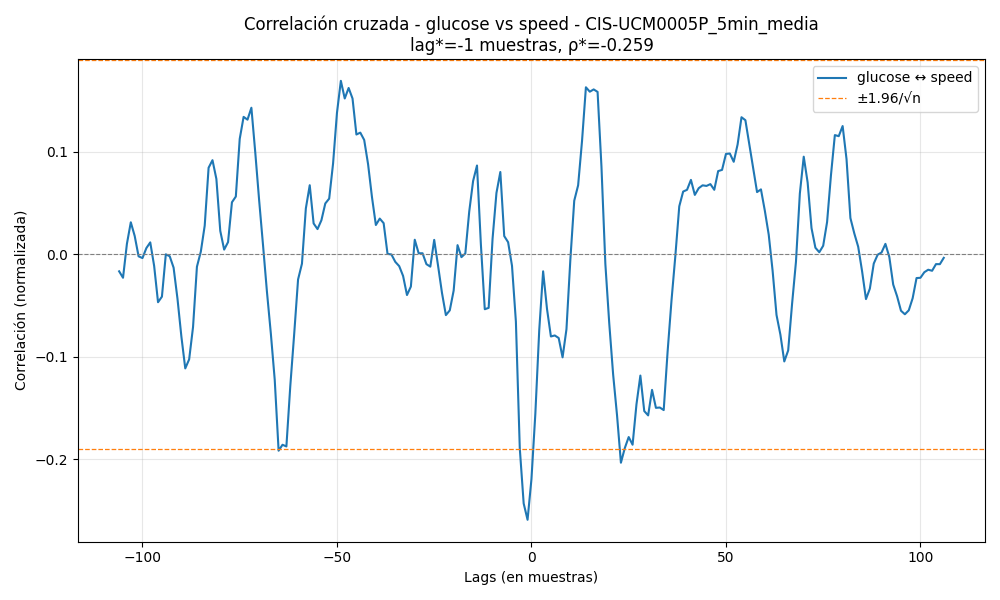

[OK] Guardado: Analysis\Correlación\correlacion_glucose_speed_CIS-UCM0005P_5min_media.png


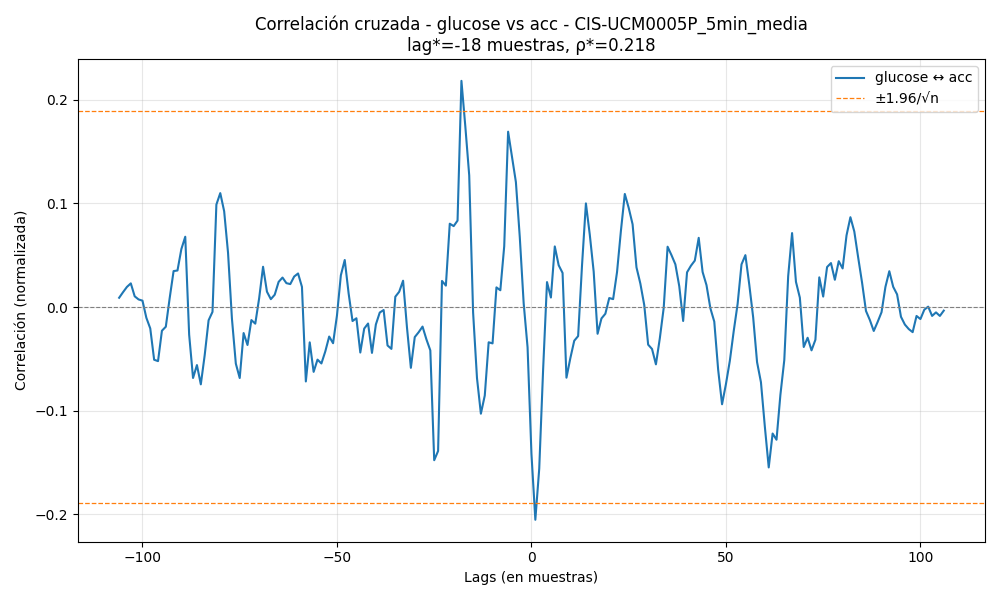

[OK] Guardado: Analysis\Correlación\correlacion_glucose_acc_CIS-UCM0005P_5min_media.png


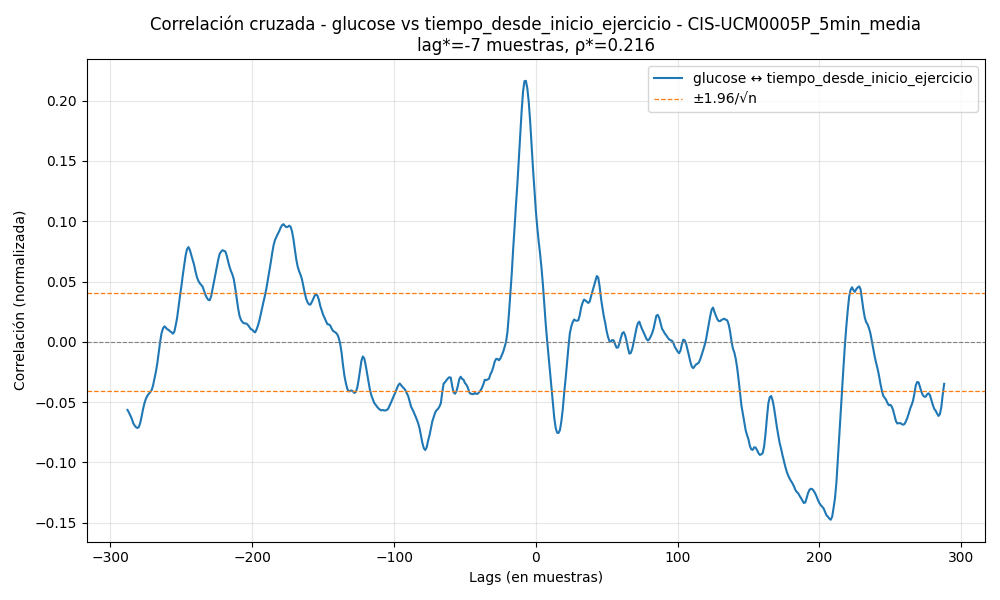

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_inicio_ejercicio_CIS-UCM0005P_5min_media.png


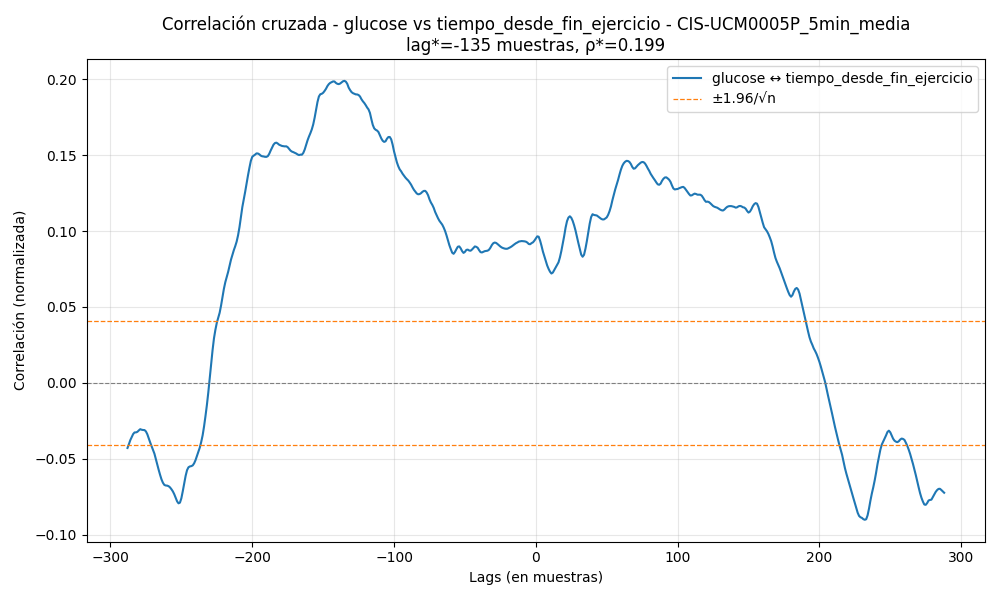

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_fin_ejercicio_CIS-UCM0005P_5min_media.png


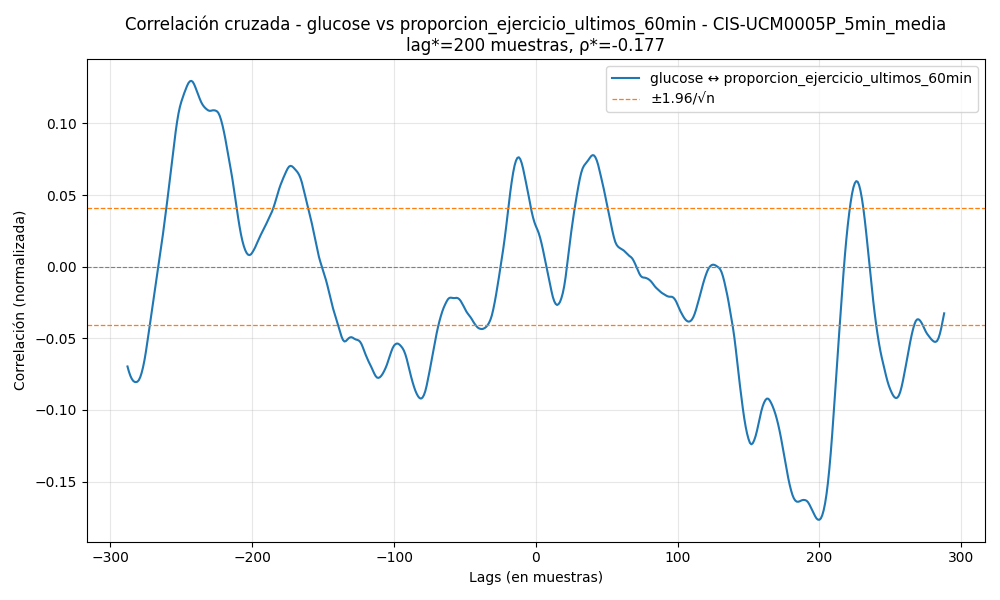

[OK] Guardado: Analysis\Correlación\correlacion_glucose_proporcion_ejercicio_ultimos_60min_CIS-UCM0005P_5min_media.png


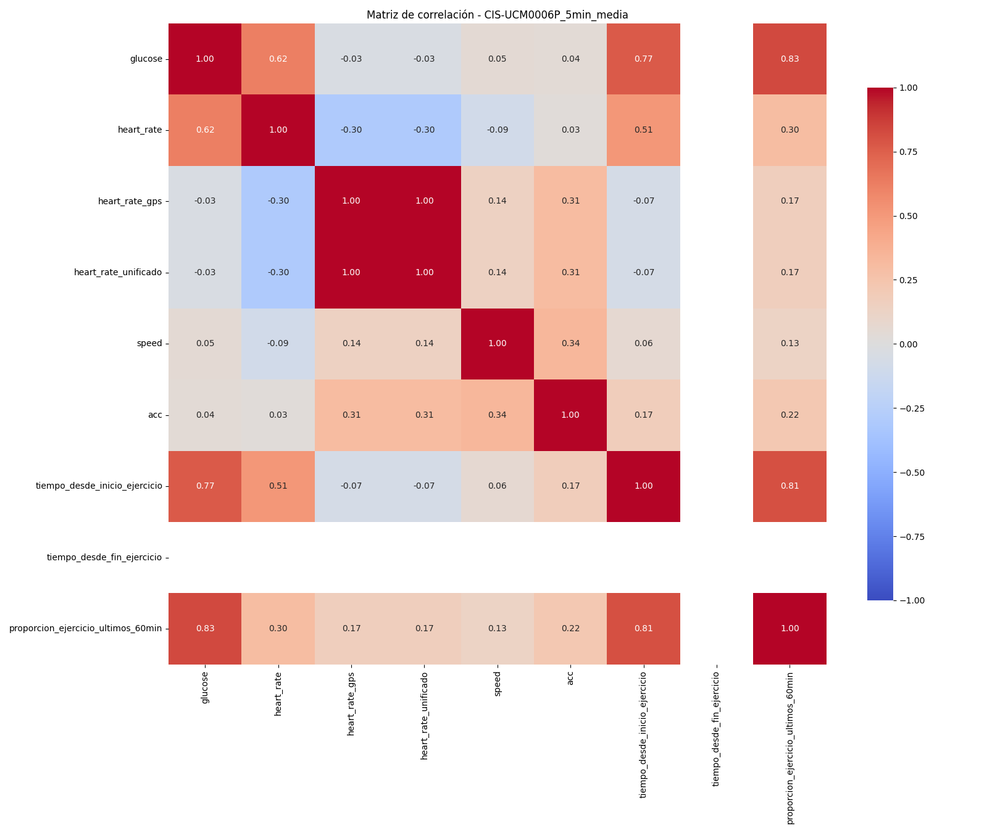

[OK] Guardado: Analysis\Correlación\matriz_correlacion_CIS-UCM0006P_5min_media.png


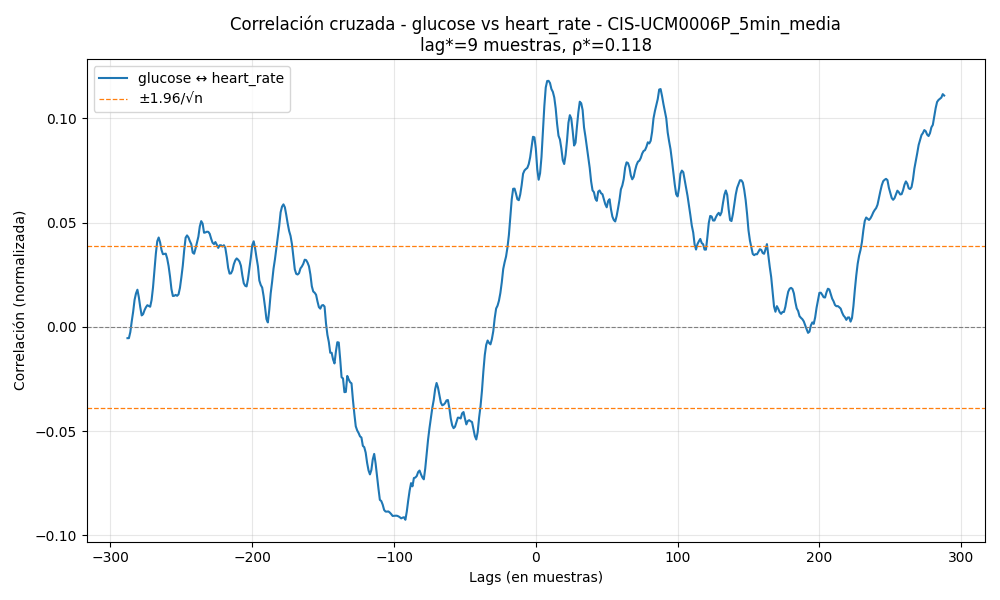

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_CIS-UCM0006P_5min_media.png


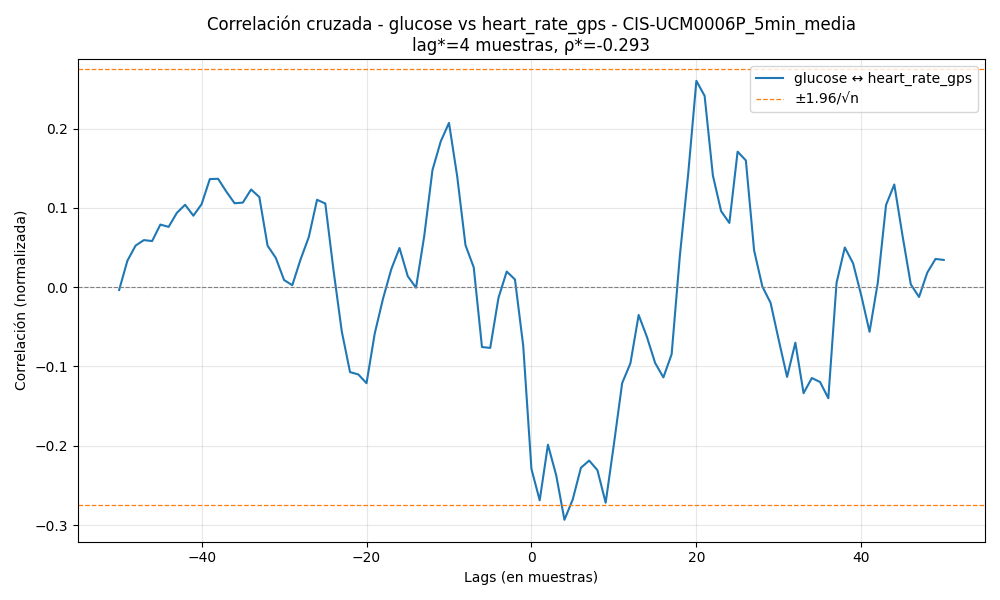

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_gps_CIS-UCM0006P_5min_media.png


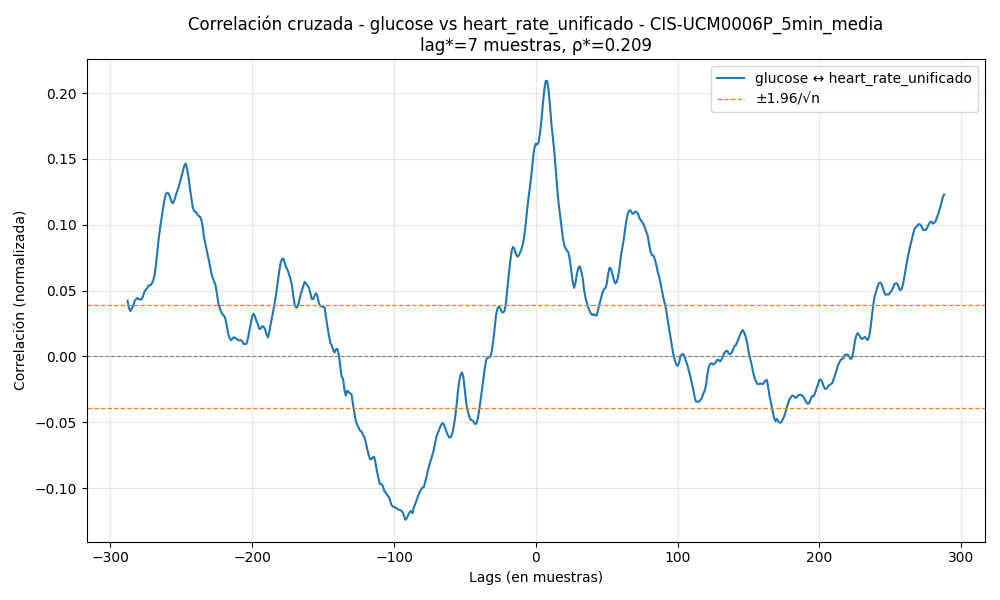

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_unificado_CIS-UCM0006P_5min_media.png


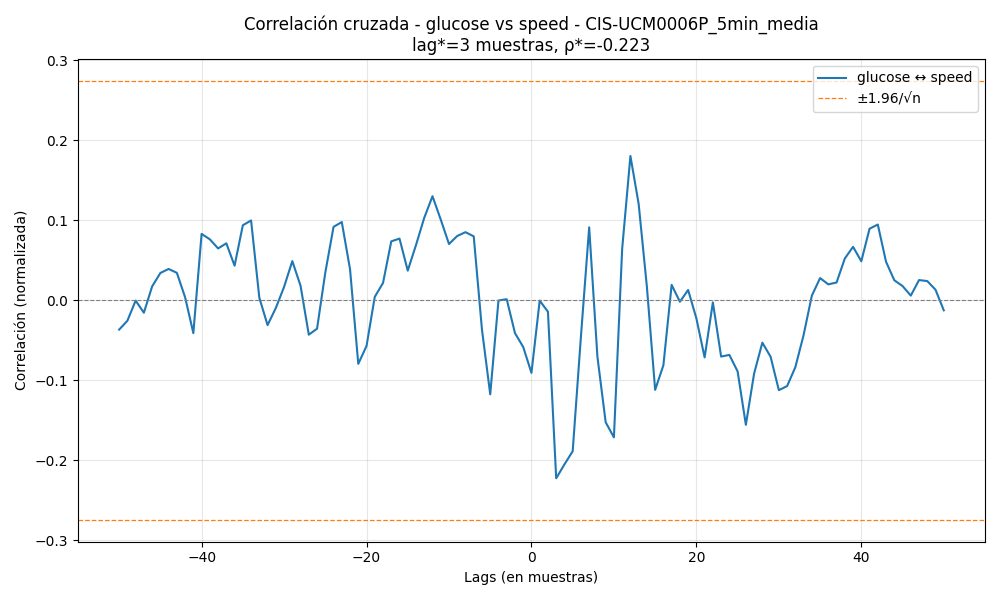

[OK] Guardado: Analysis\Correlación\correlacion_glucose_speed_CIS-UCM0006P_5min_media.png


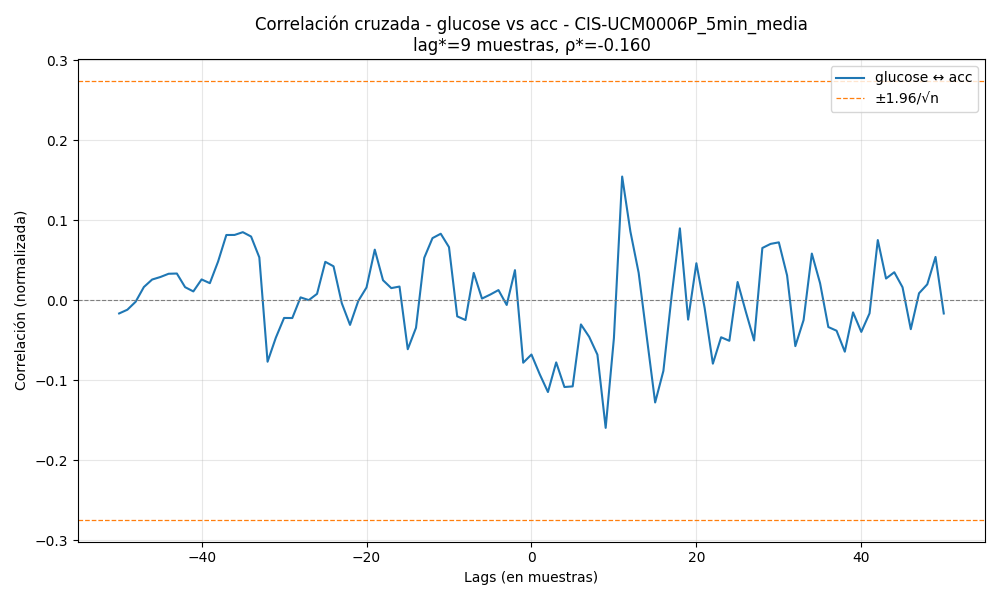

[OK] Guardado: Analysis\Correlación\correlacion_glucose_acc_CIS-UCM0006P_5min_media.png


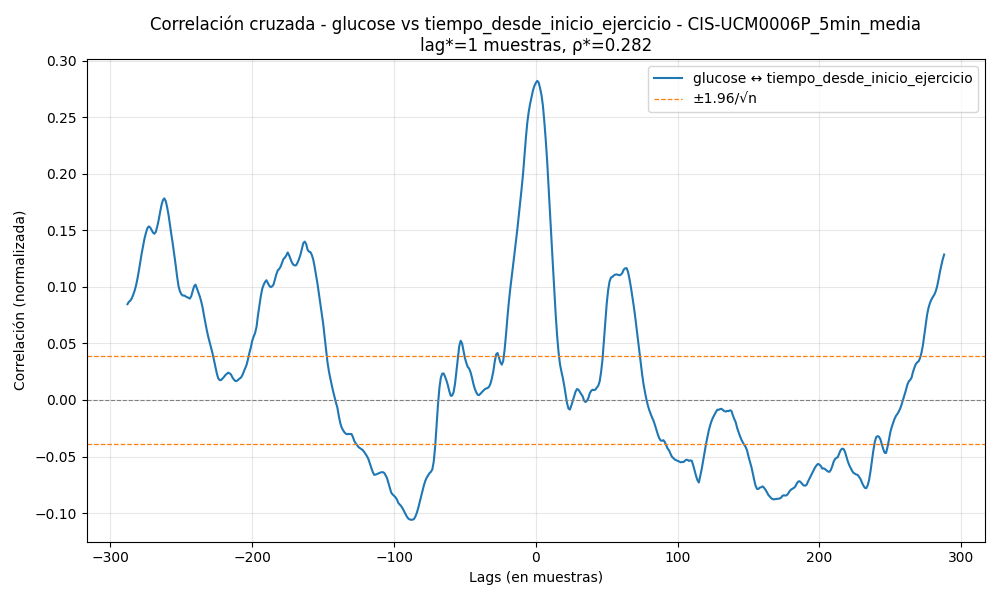

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_inicio_ejercicio_CIS-UCM0006P_5min_media.png


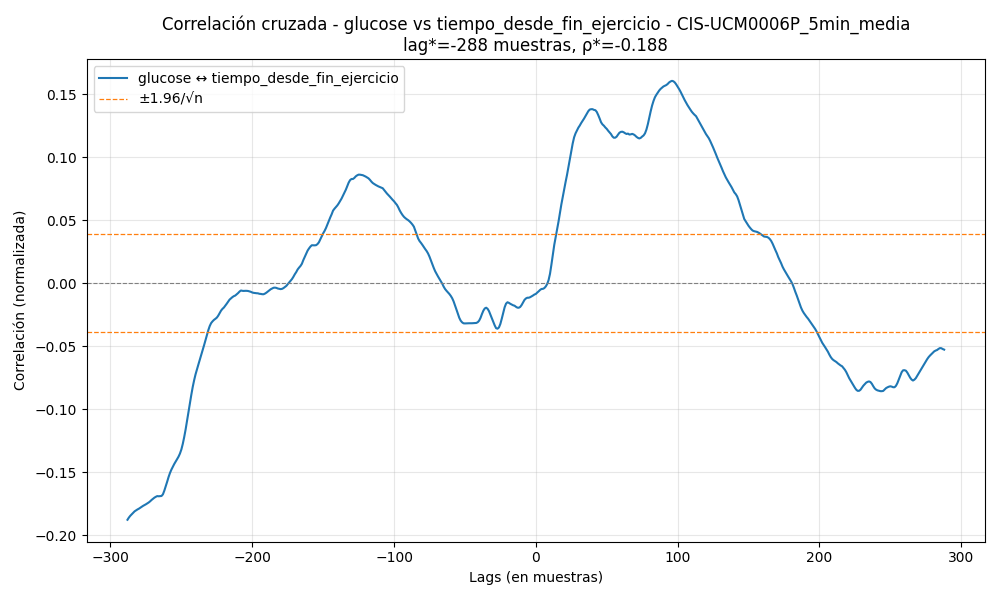

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_fin_ejercicio_CIS-UCM0006P_5min_media.png


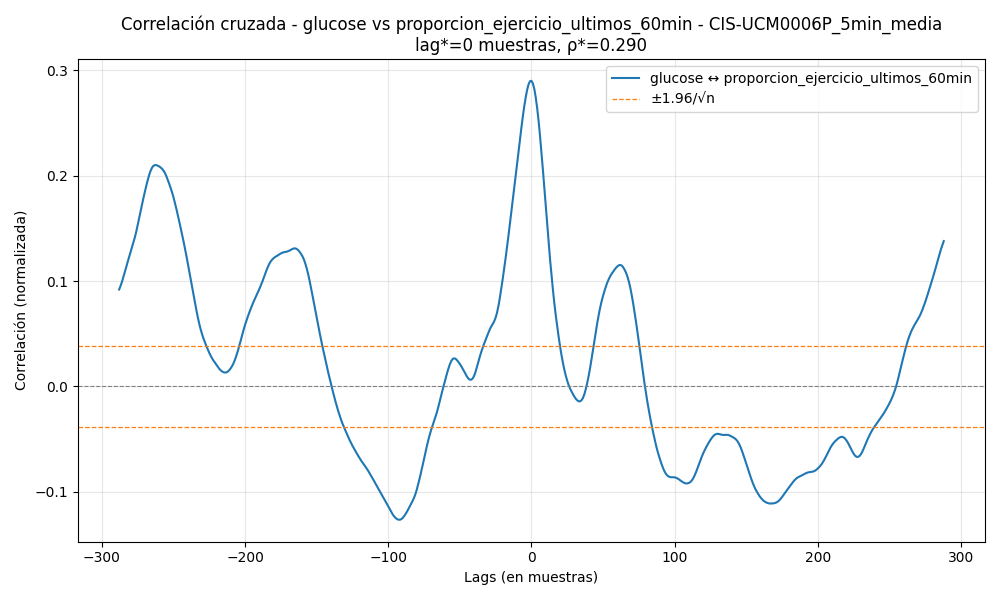

[OK] Guardado: Analysis\Correlación\correlacion_glucose_proporcion_ejercicio_ultimos_60min_CIS-UCM0006P_5min_media.png


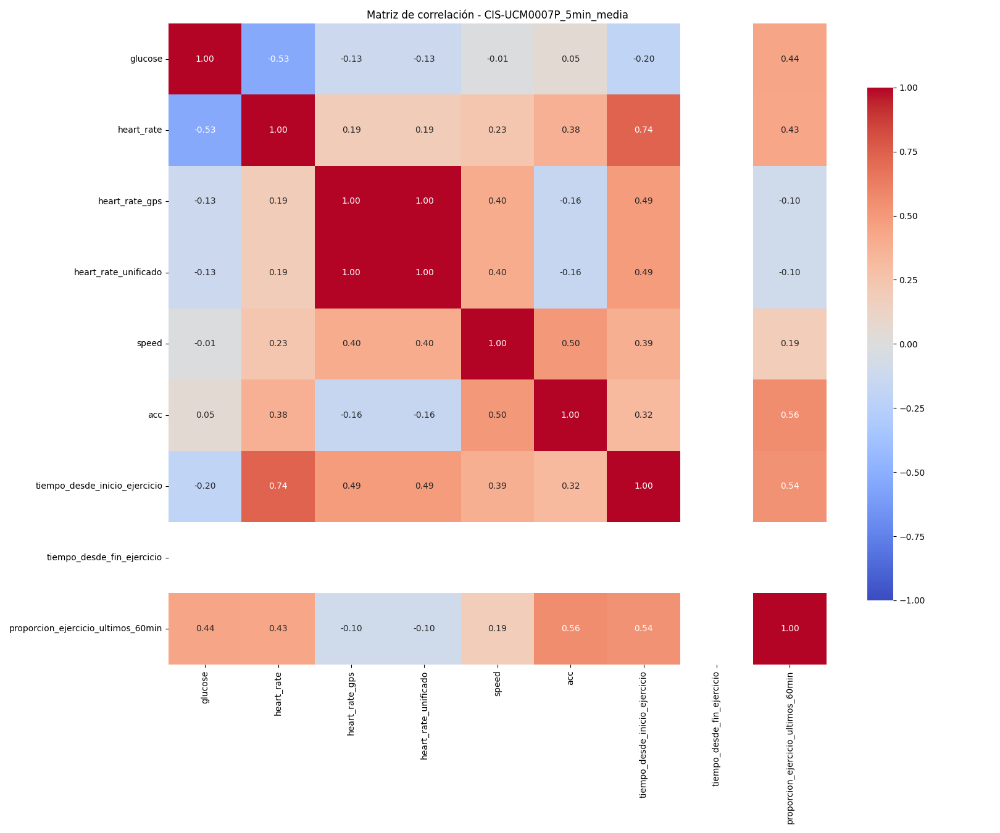

[OK] Guardado: Analysis\Correlación\matriz_correlacion_CIS-UCM0007P_5min_media.png


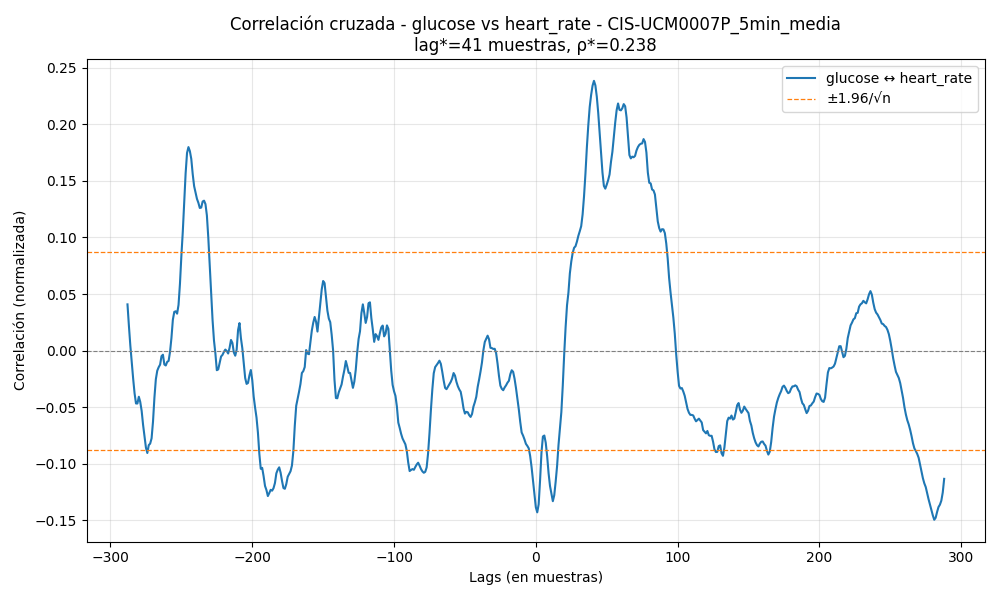

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_CIS-UCM0007P_5min_media.png


C:\Users\regin\AppData\Local\Temp\ipykernel_25496\1444867258.py:269: RuntimeWarning: More than 20 figures have been opened. Figures created through the pyplot interface (`matplotlib.pyplot.figure`) are retained until explicitly closed and may consume too much memory. (To control this warning, see the rcParam `figure.max_open_warning`). Consider using `matplotlib.pyplot.close()`.
  plt.figure(figsize=(10, 6))


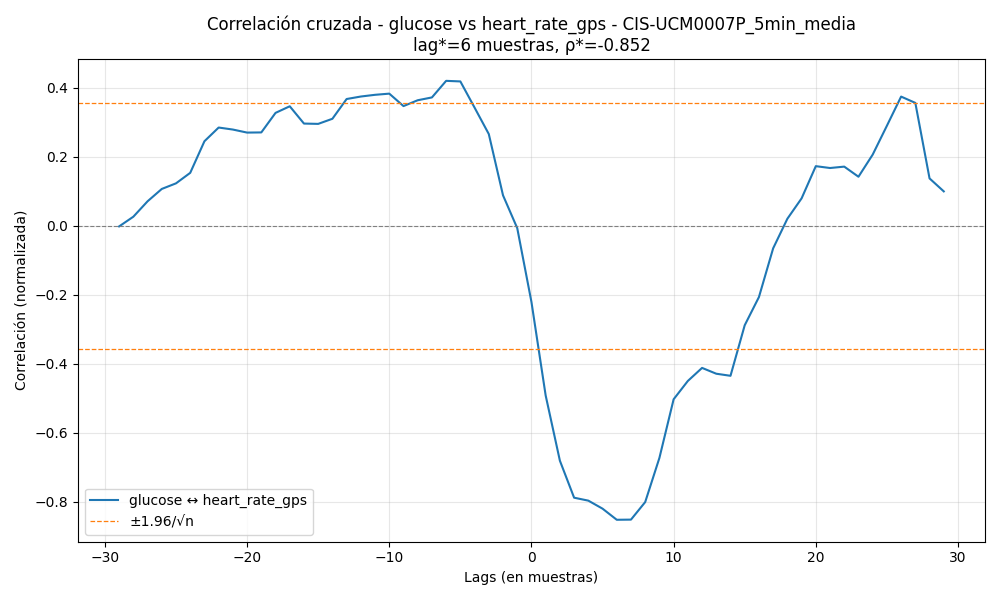

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_gps_CIS-UCM0007P_5min_media.png


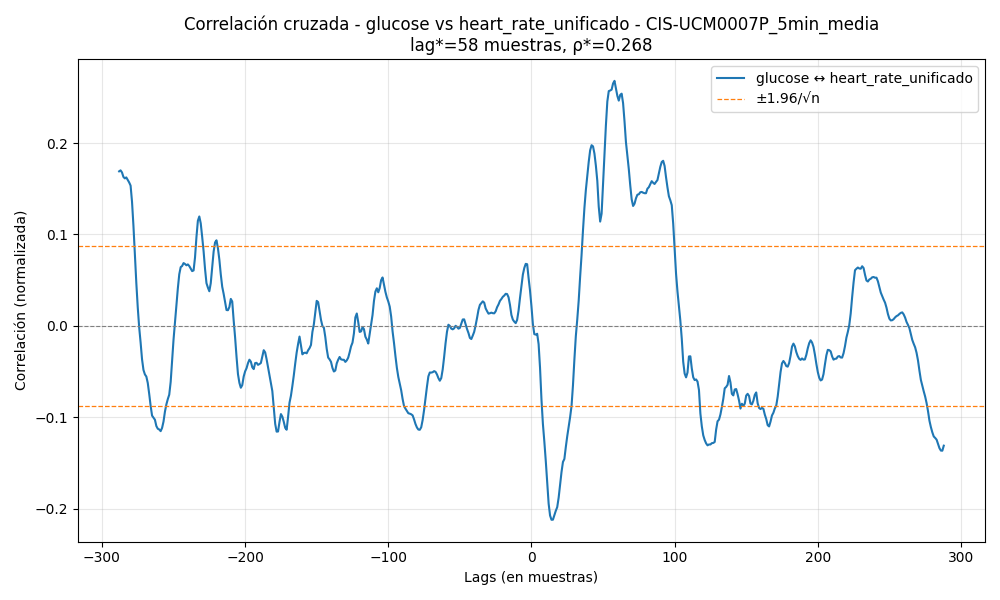

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_unificado_CIS-UCM0007P_5min_media.png


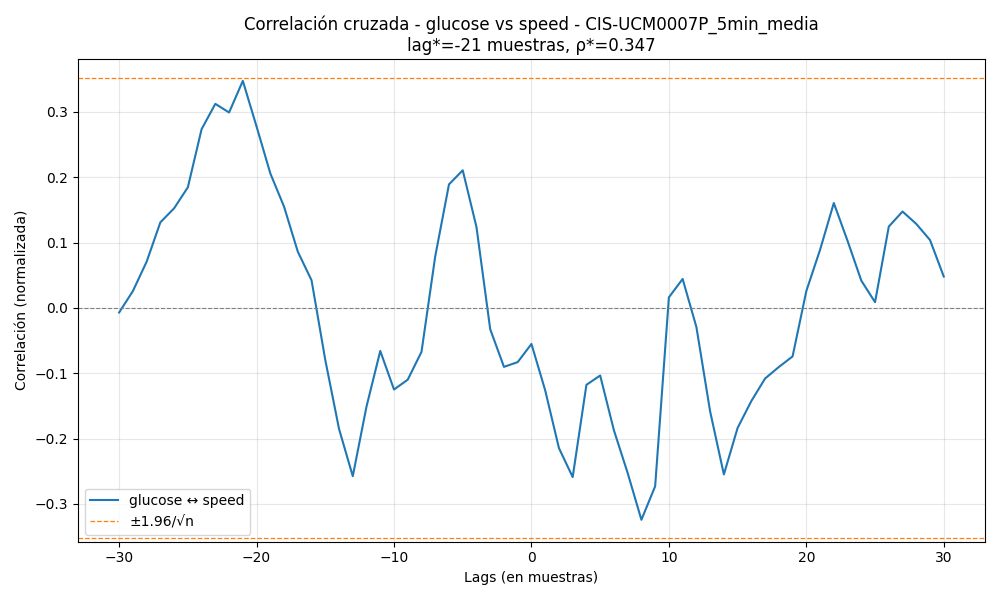

[OK] Guardado: Analysis\Correlación\correlacion_glucose_speed_CIS-UCM0007P_5min_media.png


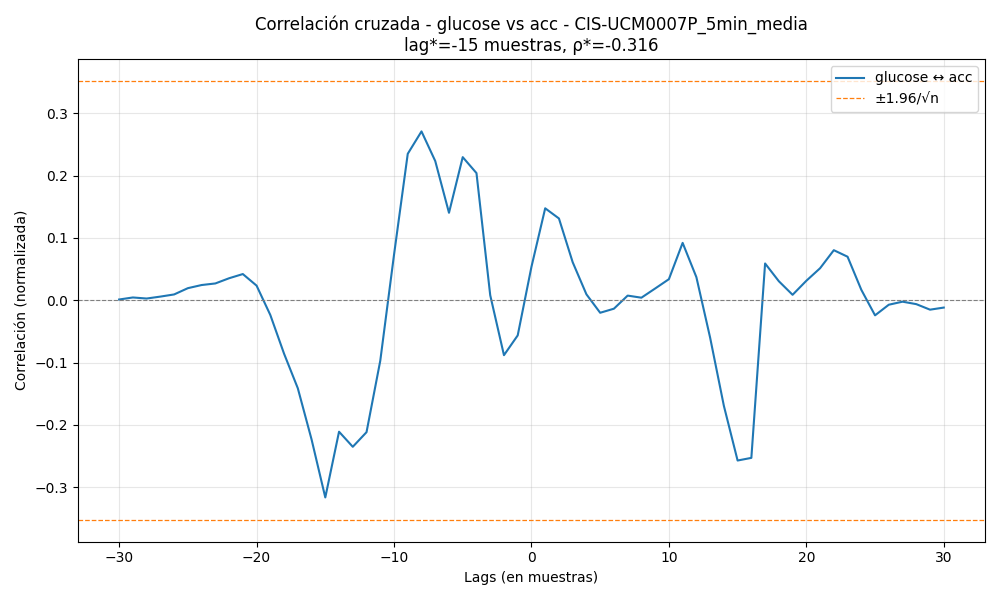

[OK] Guardado: Analysis\Correlación\correlacion_glucose_acc_CIS-UCM0007P_5min_media.png


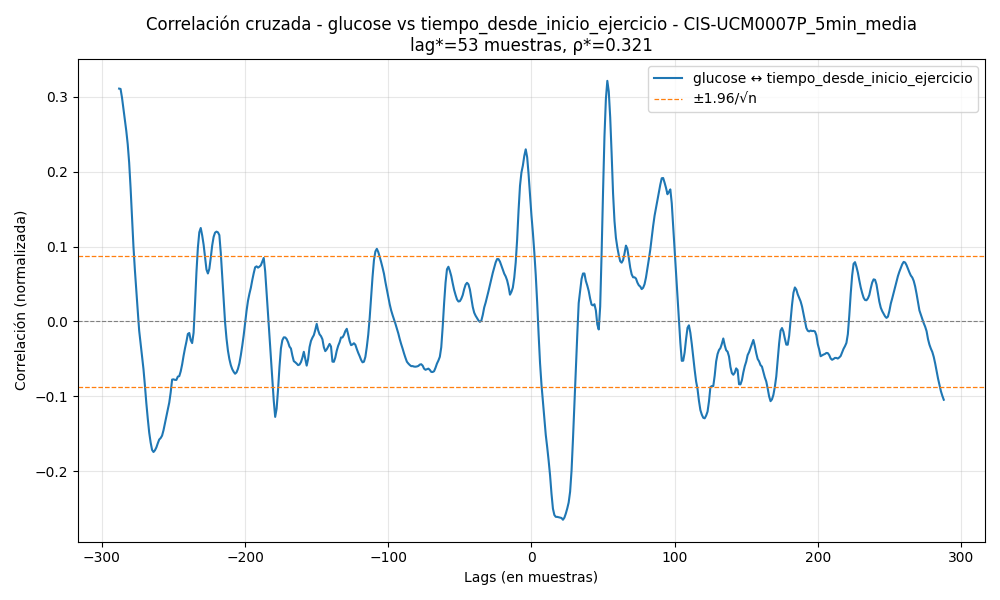

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_inicio_ejercicio_CIS-UCM0007P_5min_media.png


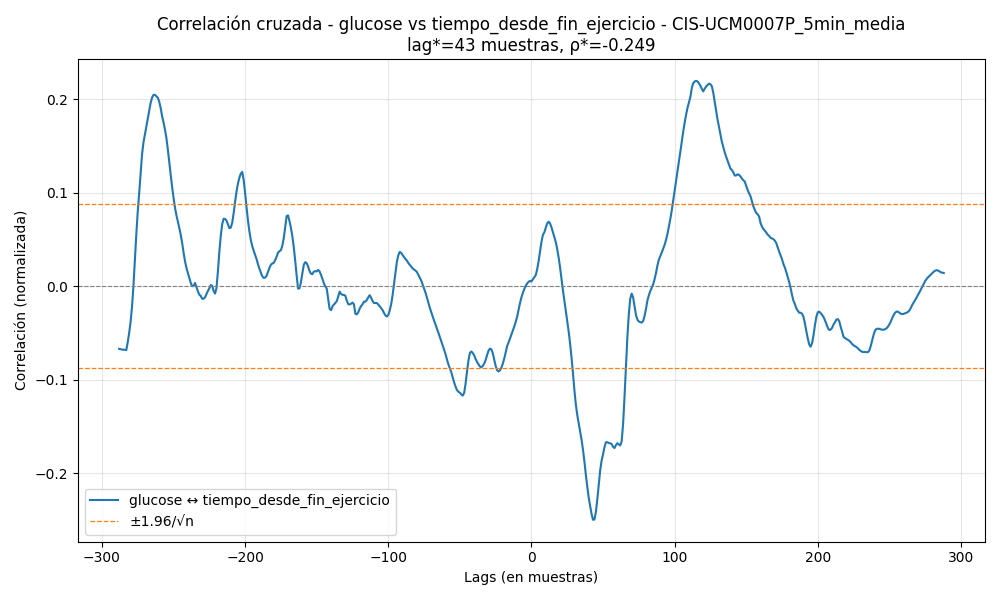

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_fin_ejercicio_CIS-UCM0007P_5min_media.png


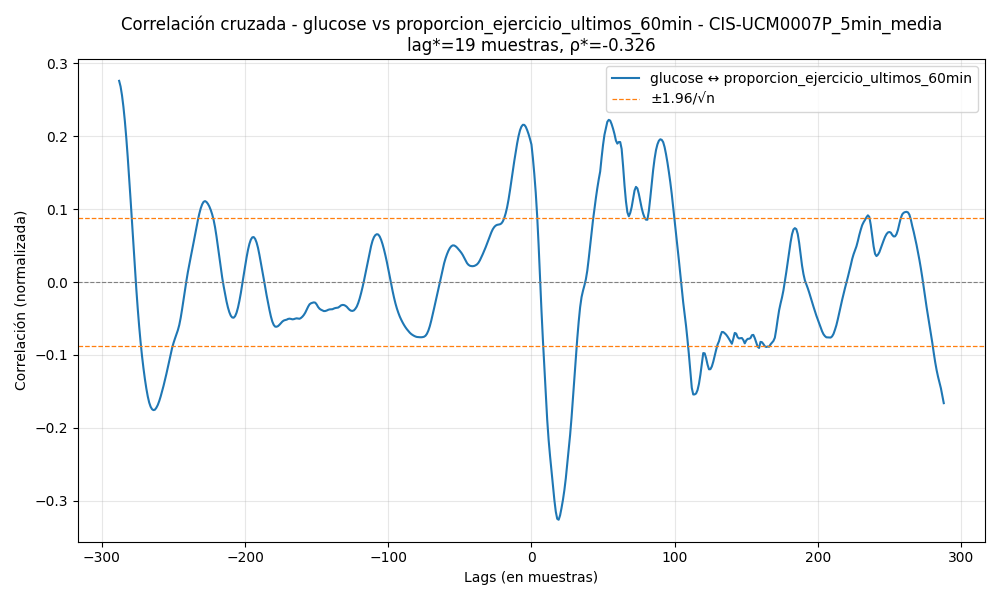

[OK] Guardado: Analysis\Correlación\correlacion_glucose_proporcion_ejercicio_ultimos_60min_CIS-UCM0007P_5min_media.png


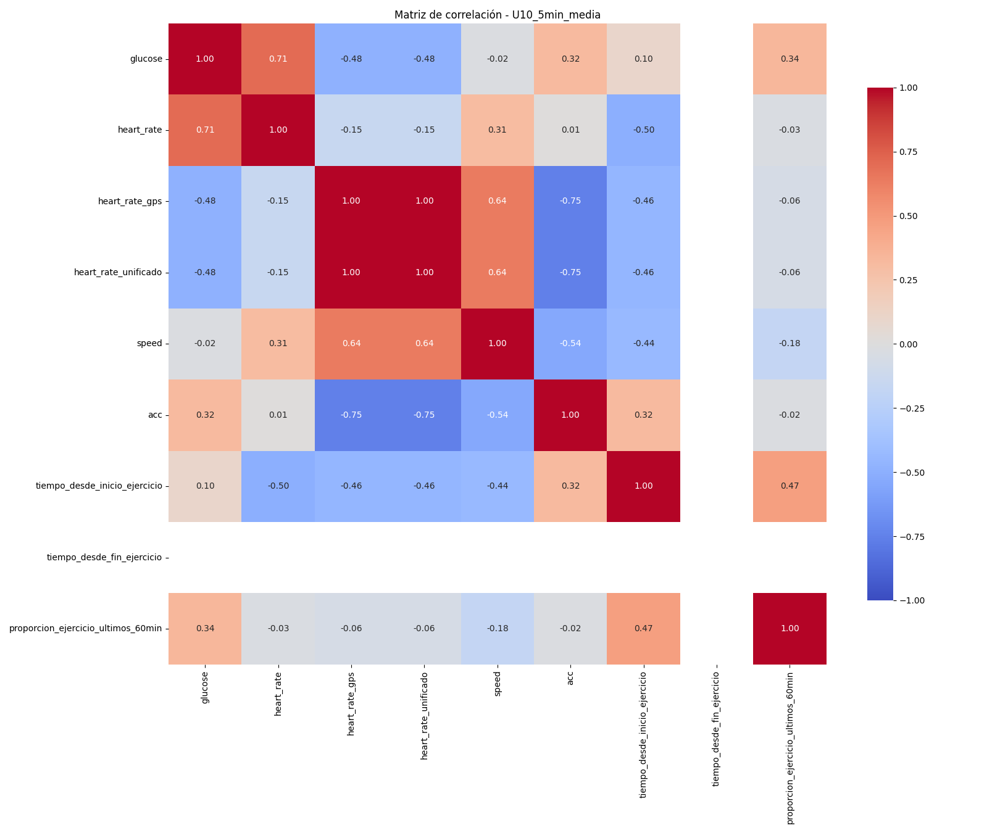

[OK] Guardado: Analysis\Correlación\matriz_correlacion_U10_5min_media.png


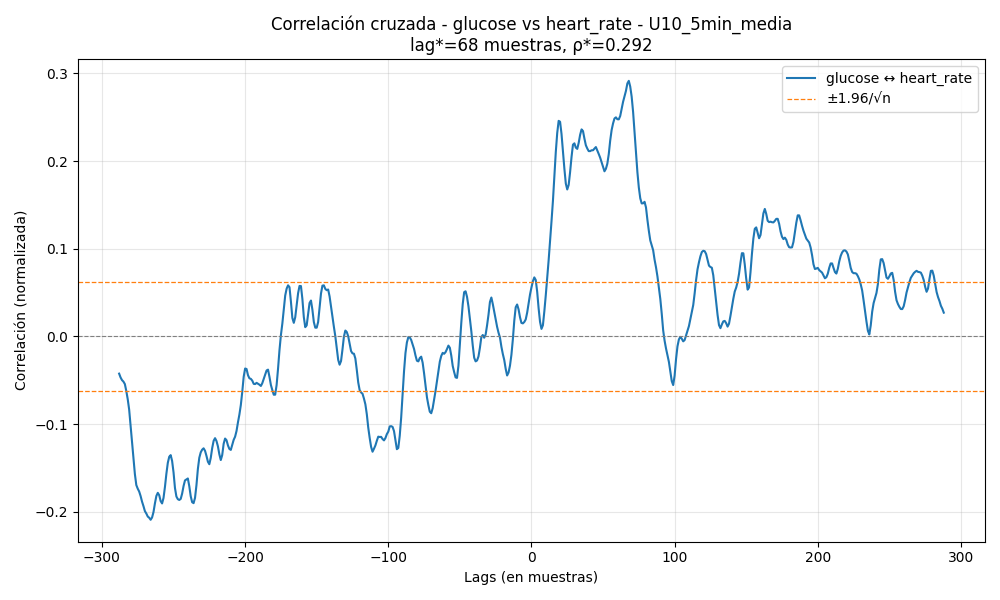

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_U10_5min_media.png


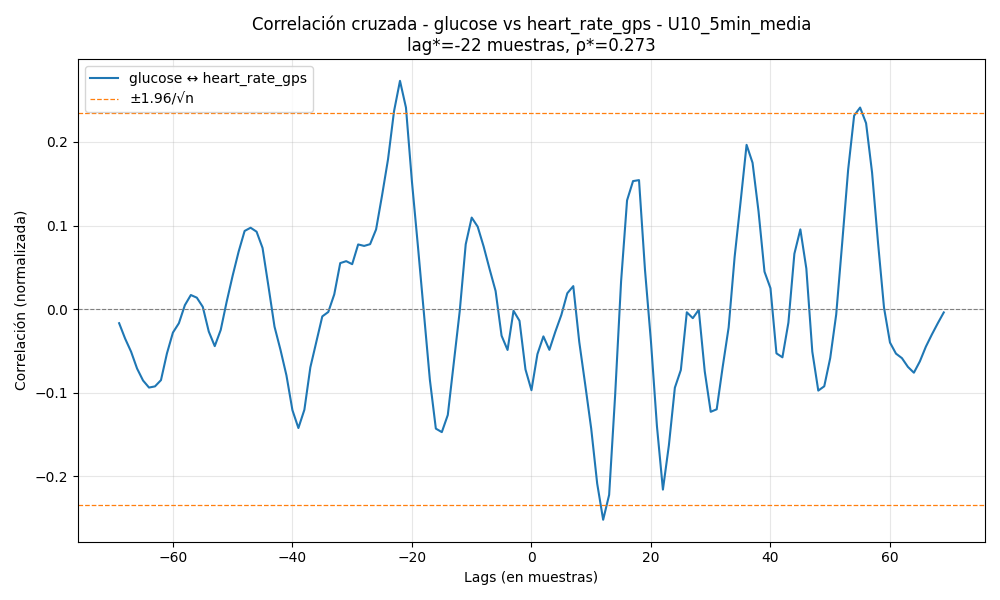

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_gps_U10_5min_media.png


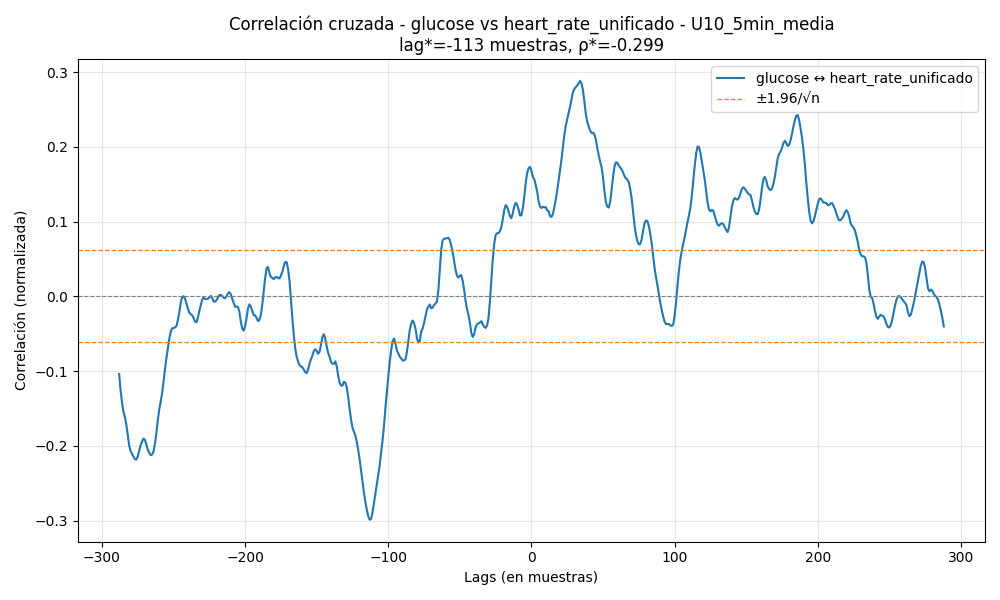

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_unificado_U10_5min_media.png


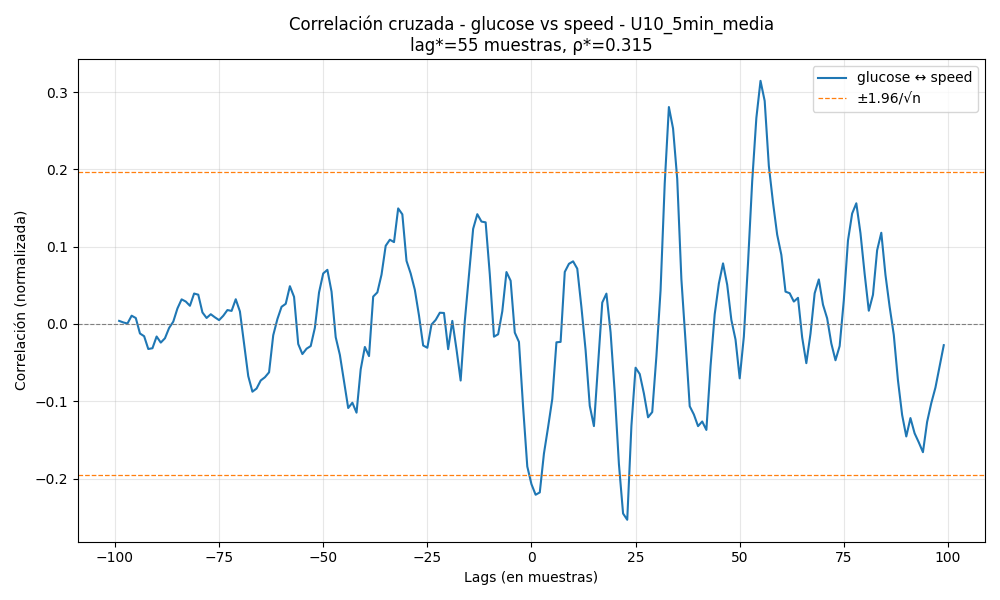

[OK] Guardado: Analysis\Correlación\correlacion_glucose_speed_U10_5min_media.png


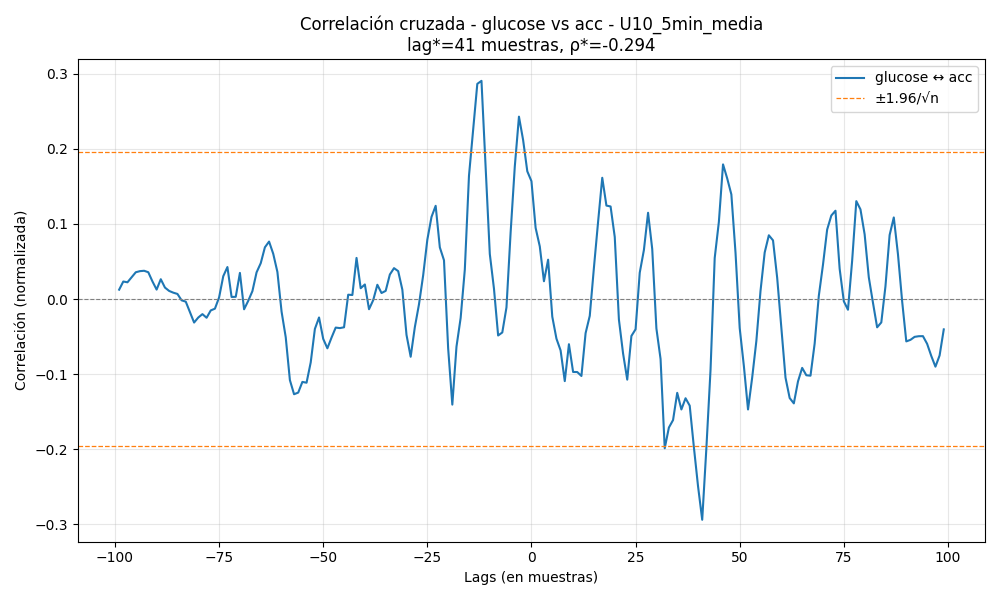

[OK] Guardado: Analysis\Correlación\correlacion_glucose_acc_U10_5min_media.png


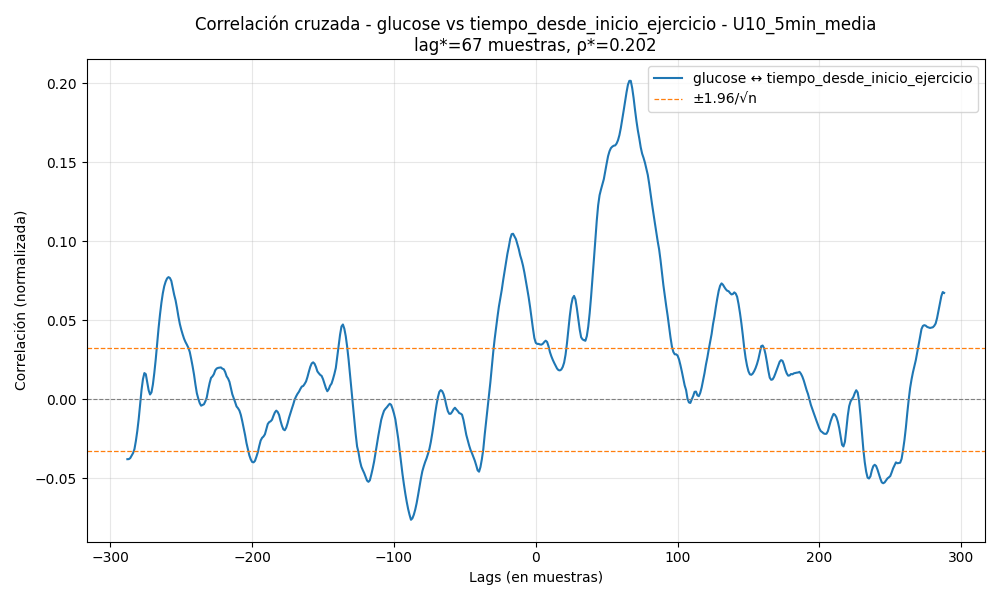

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_inicio_ejercicio_U10_5min_media.png


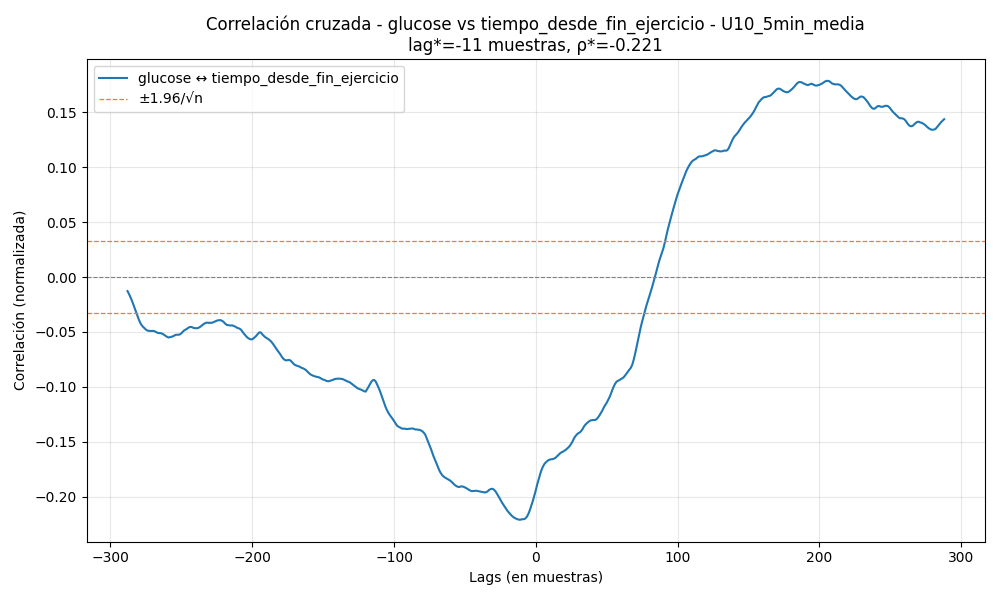

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_fin_ejercicio_U10_5min_media.png


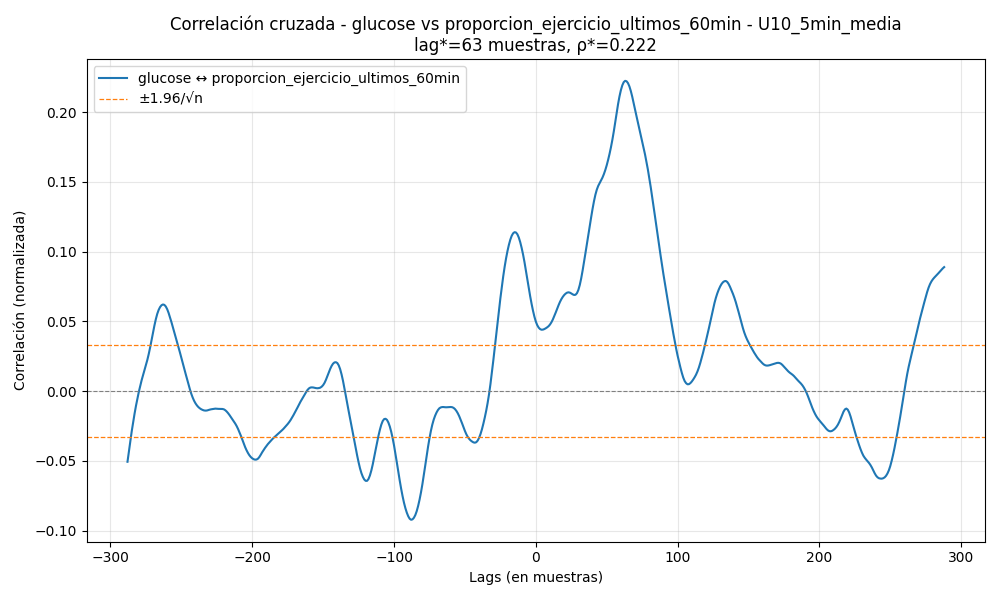

[OK] Guardado: Analysis\Correlación\correlacion_glucose_proporcion_ejercicio_ultimos_60min_U10_5min_media.png


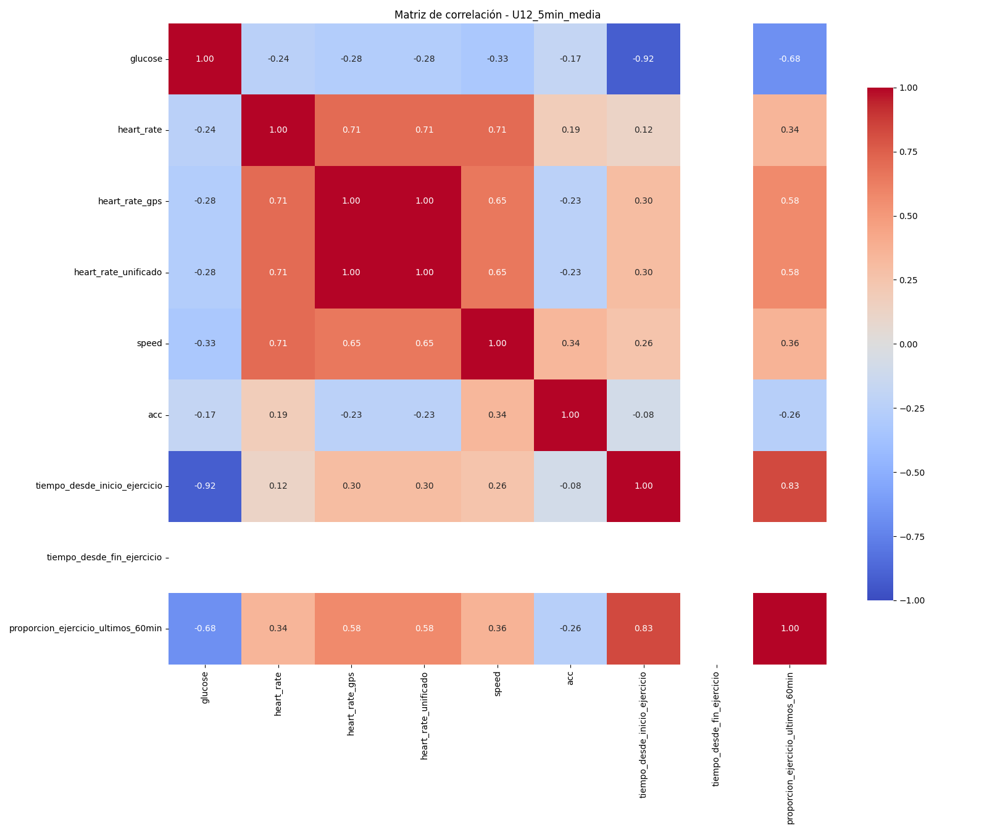

[OK] Guardado: Analysis\Correlación\matriz_correlacion_U12_5min_media.png


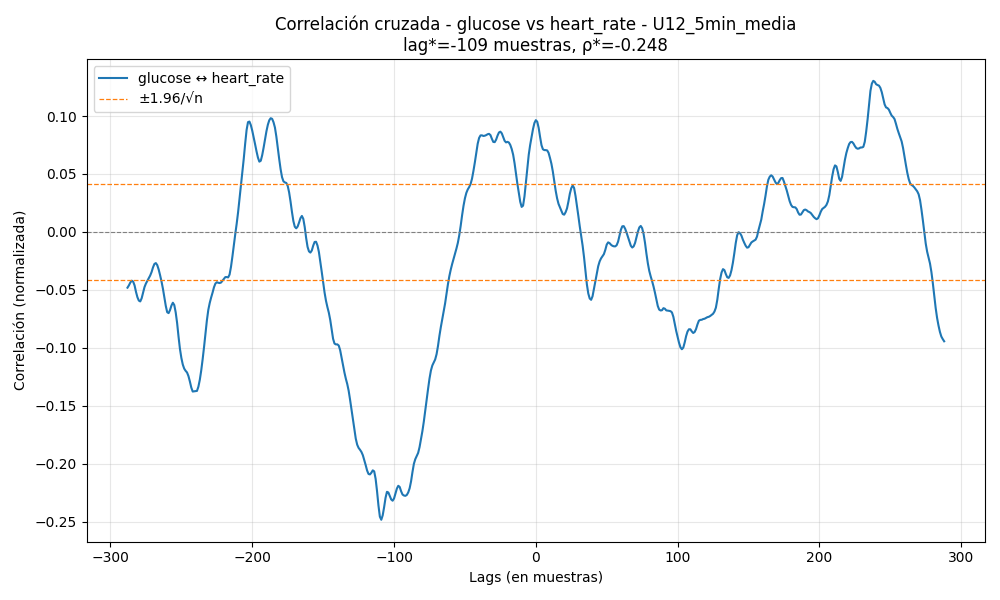

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_U12_5min_media.png


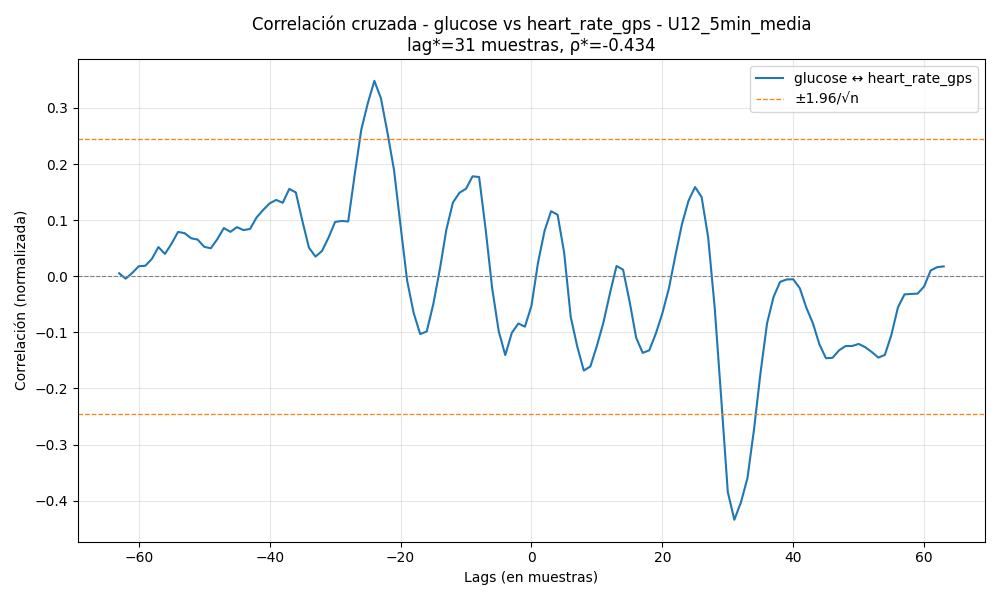

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_gps_U12_5min_media.png


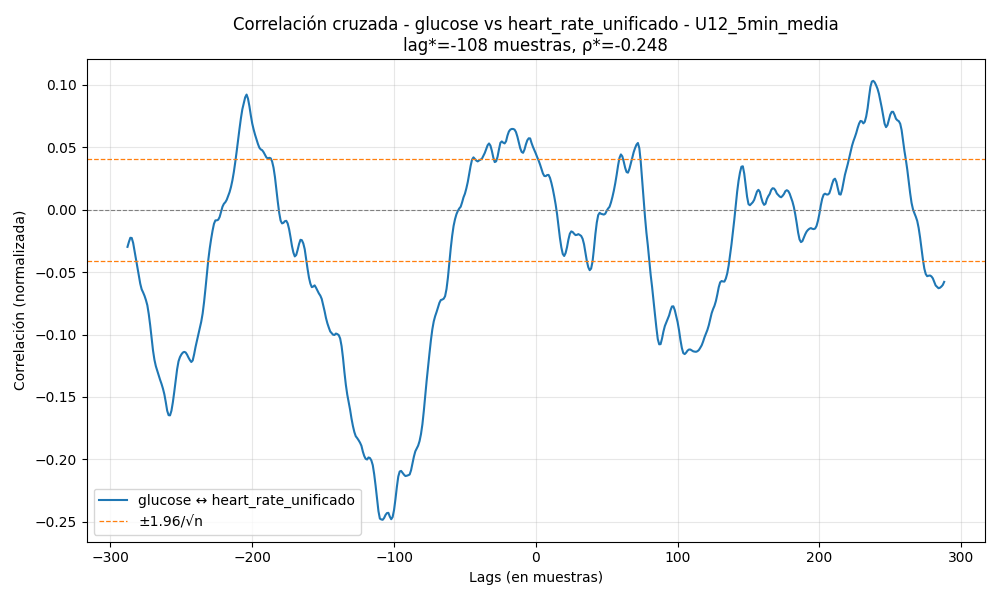

[OK] Guardado: Analysis\Correlación\correlacion_glucose_heart_rate_unificado_U12_5min_media.png


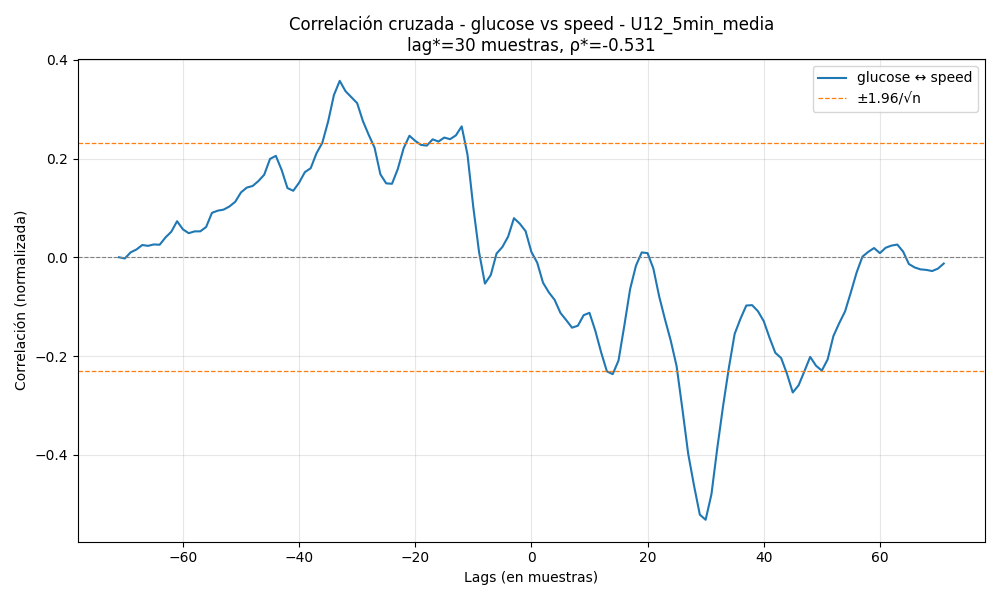

[OK] Guardado: Analysis\Correlación\correlacion_glucose_speed_U12_5min_media.png


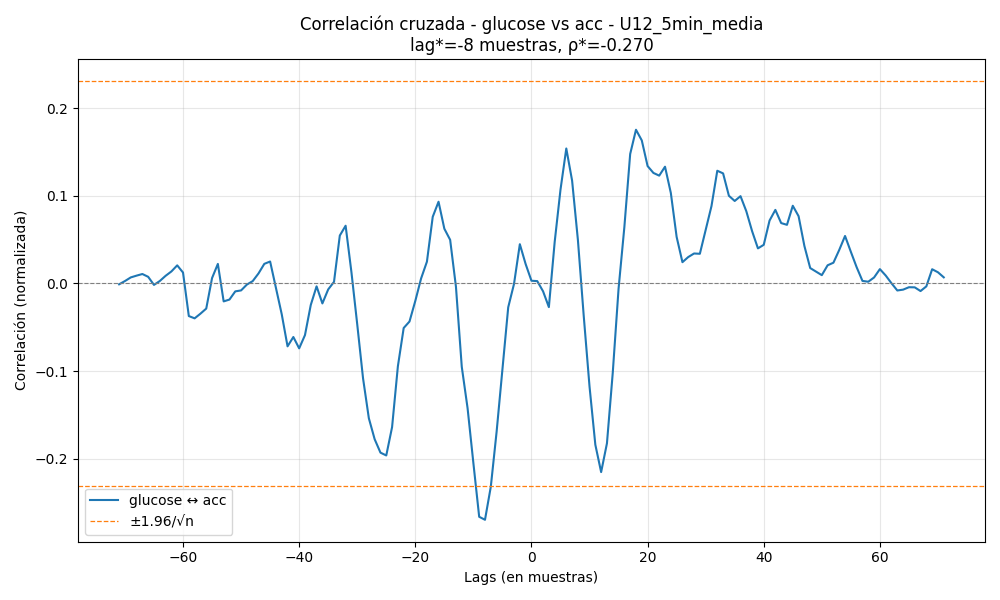

[OK] Guardado: Analysis\Correlación\correlacion_glucose_acc_U12_5min_media.png


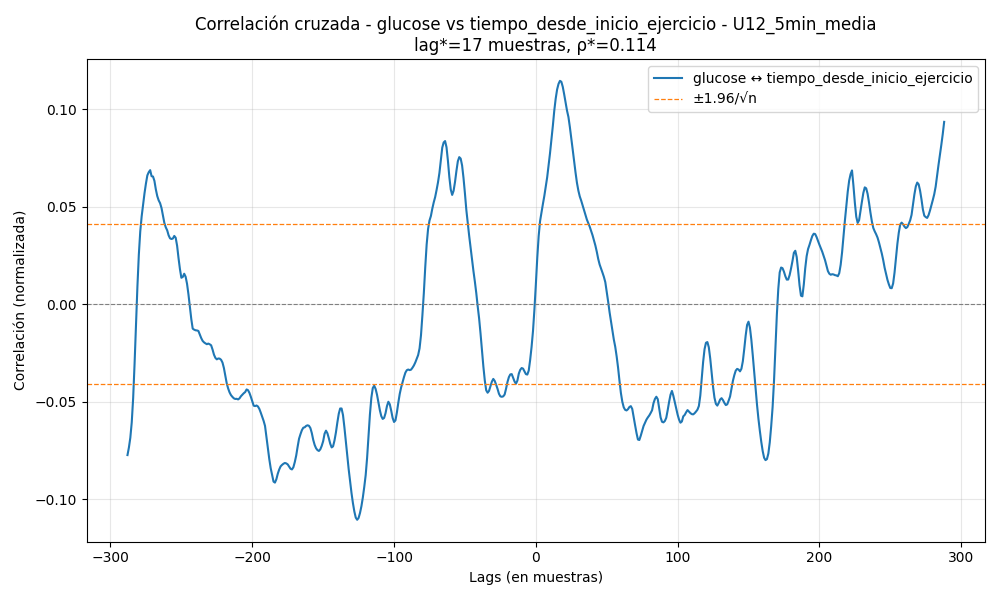

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_inicio_ejercicio_U12_5min_media.png


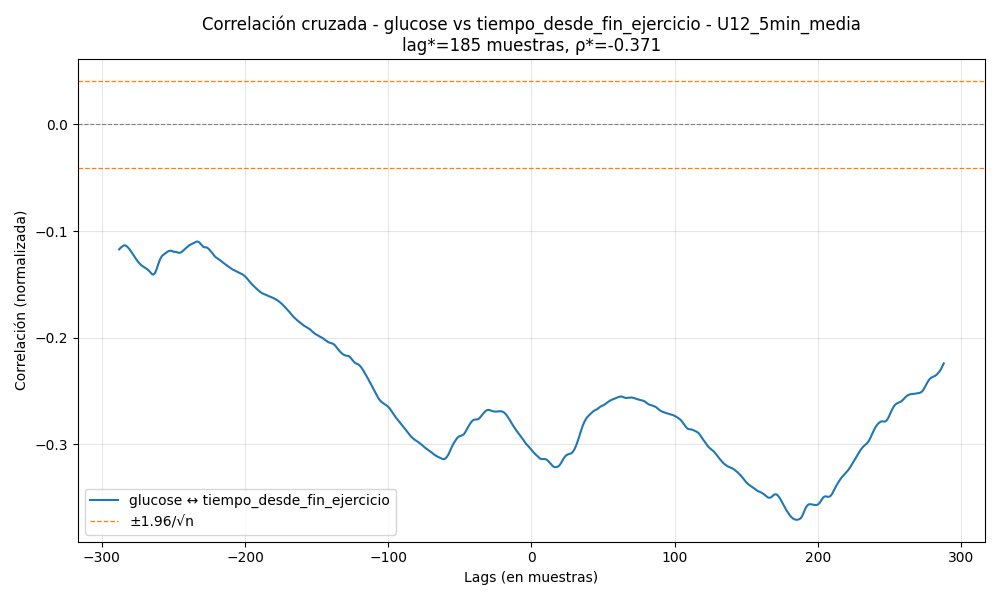

[OK] Guardado: Analysis\Correlación\correlacion_glucose_tiempo_desde_fin_ejercicio_U12_5min_media.png


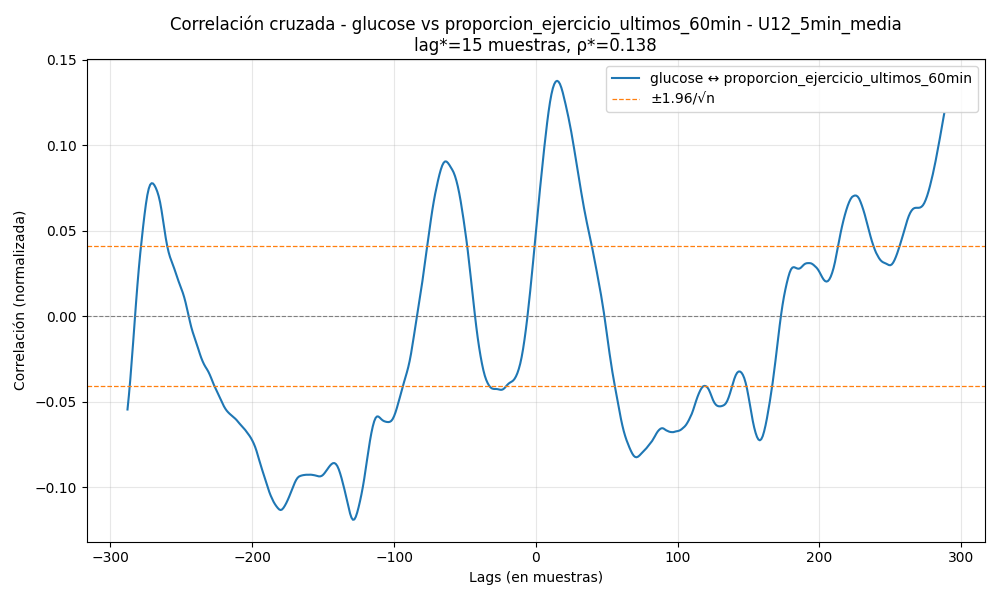

[OK] Guardado: Analysis\Correlación\correlacion_glucose_proporcion_ejercicio_ultimos_60min_U12_5min_media.png
¡Listo!


In [35]:
# =========================
# Configuración
# =========================

INPUT_DIR = r"Data\Trusted\Agrupados"
OUT_DIR   = r"Analysis\Correlación"
os.makedirs(OUT_DIR, exist_ok=True)

FILTRO_NOMBRE = "5min_media"  

# Variables para matriz de correlación
VARS_MATRIX = [
    "glucose",
    "heart_rate",
    "heart_rate_gps",
    "heart_rate_unificado",
    "speed",
    "acc",
    "tiempo_desde_inicio_ejercicio",
    "tiempo_desde_fin_ejercicio",
    "proporcion_ejercicio_ultimos_60min",
]

# Pares de variables para la correlación cruzada bidireccional
VAR_PAIRS = [
    ("glucose", "heart_rate"),
    ("glucose", "heart_rate_gps"),
    ("glucose", "heart_rate_unificado"),
    ("glucose", "speed"),
    ("glucose", "acc"),
    ("glucose", "tiempo_desde_inicio_ejercicio"),
    ("glucose", "tiempo_desde_fin_ejercicio"),
    ("glucose", "proporcion_ejercicio_ultimos_60min"),
]

PLOT_REF_BANDS = True

# =========================
# Utilidades de variables derivadas
# =========================

def infer_step_minutes(df, time_col="time"):
    if time_col not in df.columns:
        return None
    t = pd.to_datetime(df[time_col], errors="coerce")
    t = t.dropna().sort_values()
    if len(t) < 2:
        return None
    dt = t.diff().dt.total_seconds().dropna()
    if len(dt) == 0:
        return None
    return np.median(dt) / 60.0

def crear_heart_rate_unificado(df, hr_col="heart_rate", hrgps_col="heart_rate_gps", out_col="heart_rate_unificado"):
    df = df.copy()
    out = pd.Series(np.nan, index=df.index, dtype=float)
    if hrgps_col in df.columns:
        mask_hrgps = df[hrgps_col].notna()
        try:
            mask_hrgps &= (df[hrgps_col].astype(float) != 0)
        except:
            pass
        out.loc[mask_hrgps] = df.loc[mask_hrgps, hrgps_col].astype(float)
    if hr_col in df.columns:
        mask_missing = out.isna()
        mask_hr = df[hr_col].notna()
        try:
            mask_hr &= (df[hr_col].astype(float) != 0)
        except:
            pass
        mask_hr &= mask_missing
        out.loc[mask_hr] = df.loc[mask_hr, hr_col].astype(float)
    df[out_col] = out
    return df

def _durations_since_events(binary_series, step_minutes):
    ex = binary_series.fillna(0).astype(int).values
    n = len(ex)
    since_start = np.zeros(n, dtype=float)
    since_end = np.zeros(n, dtype=float)
    last_start_idx = None
    last_end_idx = None
    for i in range(n):
        if i == 0:
            if ex[i] == 1:
                last_start_idx = i
            else:
                last_end_idx = i
            continue
        if ex[i-1] == 0 and ex[i] == 1:
            last_start_idx = i
            since_start[i] = 0.0
            since_end[i] = 0.0
        elif ex[i-1] == 1 and ex[i] == 0:
            last_end_idx = i
            since_start[i] = 0.0
            since_end[i] = 0.0
        else:
            if ex[i] == 1:
                if last_start_idx is None:
                    last_start_idx = i
                since_start[i] = (i - last_start_idx) * step_minutes
                since_end[i] = 0.0
            else:
                if last_end_idx is None:
                    last_end_idx = i
                since_end[i] = (i - last_end_idx) * step_minutes
                since_start[i] = 0.0
    return pd.Series(since_start, index=binary_series.index), pd.Series(since_end, index=binary_series.index)

def _rolling_proportion(binary_series, window_minutes, step_minutes):
    if step_minutes is None or step_minutes <= 0:
        return pd.Series(np.nan, index=binary_series.index)
    window_lags = max(1, int(round(window_minutes / step_minutes)))
    return binary_series.fillna(0).astype(float).rolling(window_lags, min_periods=1).mean()

def crear_variables_ejercicio(df,
                              time_col="time",
                              exercise_col="exercise",
                              out_since_start="tiempo_desde_inicio_ejercicio",
                              out_since_end="tiempo_desde_fin_ejercicio",
                              out_prop60="proporcion_ejercicio_ultimos_60min",
                              prop_window_minutes=60.0):
    df = df.copy()
    if exercise_col not in df.columns:
        df[out_since_start] = np.nan
        df[out_since_end] = np.nan
        df[out_prop60] = np.nan
        return df
    step_min = infer_step_minutes(df, time_col=time_col)
    if step_min is None or step_min <= 0:
        ex = df[exercise_col].fillna(0).astype(int)
        since_start_steps = np.zeros(len(ex), dtype=float)
        since_end_steps = np.zeros(len(ex), dtype=float)
        last_start = None
        last_end = None
        for i in range(len(ex)):
            if i == 0:
                if ex.iloc[i] == 1:
                    last_start = i
                else:
                    last_end = i
                continue
            if ex.iloc[i-1] == 0 and ex.iloc[i] == 1:
                last_start = i
                since_start_steps[i] = 0.0
                since_end_steps[i] = 0.0
            elif ex.iloc[i-1] == 1 and ex.iloc[i] == 0:
                last_end = i
                since_start_steps[i] = 0.0
                since_end_steps[i] = 0.0
            else:
                if ex.iloc[i] == 1:
                    if last_start is None:
                        last_start = i
                    since_start_steps[i] = (i - last_start)
                    since_end_steps[i] = 0.0
                else:
                    if last_end is None:
                        last_end = i
                    since_end_steps[i] = (i - last_end)
                    since_start_steps[i] = 0.0
        df[out_since_start] = since_start_steps
        df[out_since_end] = since_end_steps
        df[out_prop60] = ex.rolling(1, min_periods=1).mean()
        return df
    ex = df[exercise_col].fillna(0).astype(int)
    since_start, since_end = _durations_since_events(ex, step_minutes=step_min)
    prop60 = _rolling_proportion(ex, window_minutes=prop_window_minutes, step_minutes=step_min)
    df[out_since_start] = since_start
    df[out_since_end] = since_end
    df[out_prop60] = prop60
    return df

def crear_acc_magnitud(df, x_col='accX', y_col='accY', z_col='accZ', out_col='acc'):
    df = df.copy()
    if all(col in df.columns for col in [x_col, y_col, z_col]):
        df[out_col] = np.sqrt(
            df[x_col].astype(float)**2 +
            df[y_col].astype(float)**2 +
            df[z_col].astype(float)**2
        )
    else:
        df[out_col] = np.nan
    return df

def crear_variables_completas(df,
                              time_col="time",
                              exercise_col="exercise",
                              hr_col="heart_rate",
                              hrgps_col="heart_rate_gps",
                              out_hr_unif="heart_rate_unificado",
                              out_since_start="tiempo_desde_inicio_ejercicio",
                              out_since_end="tiempo_desde_fin_ejercicio",
                              out_prop60="proporcion_ejercicio_ultimos_60min",
                              prop_window_minutes=60.0):
    df = crear_heart_rate_unificado(df, hr_col=hr_col, hrgps_col=hrgps_col, out_col=out_hr_unif)
    df = crear_variables_ejercicio(df,
                                   time_col=time_col,
                                   exercise_col=exercise_col,
                                   out_since_start=out_since_start,
                                   out_since_end=out_since_end,
                                   out_prop60=out_prop60,
                                   prop_window_minutes=prop_window_minutes)
    df = crear_acc_magnitud(df, x_col='accX', y_col='accY', z_col='accZ', out_col='acc')
    return df

# =========================
# Utilidades de correlación y gráficos
# =========================

def estandarizar(x: pd.Series) -> np.ndarray:
    x = x.dropna().astype(float)
    if len(x) == 0:
        return np.array([])
    mu = x.mean()
    sd = x.std(ddof=1)
    if sd == 0 or np.isnan(sd):
        return (x - mu).values
    return ((x - mu) / sd).values

def sincronizar_longitud(a: np.ndarray, b: np.ndarray):
    n = min(len(a), len(b))
    return a[:n], b[:n]

def lags_vector(n: int) -> np.ndarray:
    return np.arange(-n + 1, n)

def parse_user_from_filename(fname: str):
    return os.path.splitext(os.path.basename(fname))[0]

def plot_corr_matrix(df, cols, user_id, out_dir=OUT_DIR):
    cols_present = [c for c in cols if c in df.columns]
    if len(cols_present) < 2:
        return
    mat = df[cols_present].dropna()
    if mat.empty:
        return
    plt.figure(figsize=(1.8*len(cols_present), 1.5*len(cols_present)))
    corr = mat.corr()
    sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", vmin=-1, vmax=1, cbar_kws={"shrink": 0.8})
    plt.title(f"Matriz de correlación - {user_id}")
    plt.tight_layout()
    fname = os.path.join(out_dir, f"matriz_correlacion_{user_id}.png")
    plt.savefig(fname, dpi=300)
    plt.show()
    print(f"[OK] Guardado: {fname}")

def plot_ccf(series1: pd.Series, series2: pd.Series, user_id: str,
             var1: str, var2: str, out_dir=OUT_DIR, max_lag=288):
    x = estandarizar(series1)
    y = estandarizar(series2)
    if len(x) == 0 or len(y) == 0:
        print(f"[WARN] {user_id}: sin datos válidos para {var1} vs {var2}")
        return
    x, y = sincronizar_longitud(x, y)
    n = len(x)
    cc = correlate(x, y, mode="full") / n
    lags = lags_vector(n)
    
    mask = (lags >= -max_lag) & (lags <= max_lag)
    lags = lags[mask]
    cc = cc[mask]

    idx = np.argmax(np.abs(cc))
    lag_star = lags[idx]
    rho_star = cc[idx]

    plt.figure(figsize=(10, 6))
    plt.plot(lags, cc, color="tab:blue", label=f"{var1} ↔ {var2}")
    plt.axhline(0, color="gray", linestyle="--", linewidth=0.8)
    if PLOT_REF_BANDS:
        band = 1.96 / np.sqrt(n)
        plt.axhline(band, color="tab:orange", linestyle="--", linewidth=0.9, label="±1.96/√n")
        plt.axhline(-band, color="tab:orange", linestyle="--", linewidth=0.9)
    plt.xlabel("Lags (en muestras)")
    plt.ylabel("Correlación (normalizada)")
    plt.title(f"Correlación cruzada - {var1} vs {var2} - {user_id}\n"
              f"lag*={lag_star} muestras, ρ*={rho_star:.3f}")
    plt.grid(True, alpha=0.3)
    plt.legend()
    plt.tight_layout()
    fname = os.path.join(out_dir, f"correlacion_{var1}_{var2}_{user_id}.png")
    plt.savefig(fname, dpi=300)
    plt.show()
    print(f"[OK] Guardado: {fname}")


# =========================
# Pipeline principal
# =========================

def process_file(csv_path: str):
    user_id = parse_user_from_filename(csv_path)
    try:
        df = pd.read_csv(csv_path)
    except Exception as e:
        print(f"Error procesando el archivo: {e}")
        return
    
    # Preparar variables derivadas
    df = crear_variables_completas(
        df,
        time_col="time",
        exercise_col="exercise",
        hr_col="heart_rate",
        hrgps_col="heart_rate_gps",
        out_hr_unif="heart_rate_unificado",
        out_since_start="tiempo_desde_inicio_ejercicio",
        out_since_end="tiempo_desde_fin_ejercicio",
        out_prop60="proporcion_ejercicio_ultimos_60min",
        prop_window_minutes=60.0
    )

    # Matriz de correlación
    plot_corr_matrix(df, VARS_MATRIX, user_id, out_dir=OUT_DIR)
    
    # Correlaciones cruzadas
    for var1, var2 in VAR_PAIRS:
        if var1 in df.columns and var2 in df.columns:
            plot_ccf(df[var1], df[var2], user_id, var1, var2, out_dir=OUT_DIR)
        else:
            print(f"[WARN] {user_id}: faltan columnas para {var1} vs {var2}")

def main():
    patron = f"*{FILTRO_NOMBRE}*.csv" if FILTRO_NOMBRE else "*.csv"
    archivos = glob.glob(os.path.join(INPUT_DIR, patron))
    if not archivos:
        print(f"No se encontraron archivos CSV en {INPUT_DIR} con filtro '{FILTRO_NOMBRE}'")
        return
    print(f"Procesando {len(archivos)} archivos en {INPUT_DIR}...")
    for archivo in archivos:
        process_file(archivo)
    print("¡Listo!")

if __name__ == "__main__":
    main()


In [36]:
plt.close('all')

Las gráficas de correlación cruzada muestran cómo se relacionan dos señales (por ejemplo, glucosa y aceleración, glucosa y pasos, etc.) a diferentes lags (desplazamientos temporales) dentro de los datos de un mismo usuario.
En nuestro caso la variable glucosa siempre va como primera variable, y veremos su correlación con otras variables derivadas del ejercicio.

**Cómo leer gráficas de correlación cruzada**:

1. Eje X: Lags (en muestras de 5 minutos)
    - Lag = 0: compara las dos señales en el mismo instante de tiempo.
    - Lag negativo: la segunda señal (por ejemplo, aceleración) va por delante de la primera (siempre glucosa en nuestro caso). Es decir, cambios en aceleración preceden a cambios en glucosa.
    - Lag positivo: la segunda señal va por detrás de la primera. Por ejemplo, cambios en glucosa preceden a cambios en aceleración.
    
    Ejemplo:
    Si vemos un pico de correlación en el lag = -18, significa que la variable "acc" (aceleración) se adelanta a la glucosa en 18 muestras (en nuestro caso, como cada muestra es de 5 minutos, serían 90 minutos).

2. Eje Y: Correlación normalizada
    - Valores cerca de 0 indican poca o ninguna relación.
    - Valores positivos: cuando una sube, la otra tiende a subir (relación directa).
    - Valores negativos: cuando una sube, la otra tiende a bajar (relación inversa).

3. Curva (azul):
    Muestra la correlación cruzada para cada lag.
    Los picos (ya sean máximos o mínimos) indican los lags donde la relación es más fuerte.

4. Bandas de confianza (naranjas) ±1.96/√n:
    Son bandas de referencia: si la curva (azul) está fuera de estas bandas, la correlación es potencialmente significativa (aunque no estrictamente, ya que no se tiene en cuenta la autocorrelación).
    Si la curva está dentro de las bandas, la relación podría ser debida al azar.

**Cómo interpretar las gráficas**
- _¿Qué variable precede a cuál?_ 
    Si el máximo está en lag negativo, la segunda variable (ej. acc) precede a la primera (glucose).
    Si está en lag positivo, la segunda variable sigue a la primera.
- _¿Hay relación significativa?_
    Si el pico está fuera de las bandas naranjas, la relación es posiblemente real.
- _¿Es directa o inversa?_
    - Valor positivo: directa.
    - Valor negativo: inversa.

**Cómo interpretar “varios picos”**

La presencia de varias crestas y valles suele darse cuando ambas series tienen autocorrelación fuerte (memoria) y/o hay respuesta retardada con cierta forma “oscilatoria” (por ejemplo, sube, luego compensa y baja).

Que existan picos tanto en lags negativos como positivos significa que, en distintos horizontes, a veces FC se adelanta a glucosa y en otros la glucosa se adelanta al FC. En fisiología esto puede ocurrir porque hay mecanismos con latencias diferentes (fases de ejercicio agudo, fases de recuperación, ingestas de comida o regulación hormonal, por ejemplo).

**Interpretación y sentido fisiológico de ciertas correlaciones cruzadas**

1. Naturaleza de las variables “desde” y “proporción”:

    - "tiempo_desde_inicio_ejercicio": Es una variable que solo crece mientras no se realiza ejercicio, y se resetea a 0 cuando empieza.
    - "tiempo_desde_fin_ejercicio": Solo crece tras terminar el ejercicio, y se resetea a 0 cuando termina.
    - "proporcion_ejercicio_ultimos_60min": Es una media móvil del binario de ejercicio en una ventana pasada.
    
    Estas variables no son independientes ni "modificables" directamente por la glucosa. Son sólo indicadores de la historia reciente de la actividad física.

2. ¿Cómo correlacionarlas con glucosa?

    - Como análisis descriptivo o de respuesta fisiológica:
        - ¿Cómo responde la glucosa tras terminar el ejercicio?
        - ¿Cómo evoluciona la glucosa conforme pasa el tiempo desde el inicio o fin del ejercicio?
        - ¿Cómo afecta la cantidad de ejercicio reciente a la glucosa?
    - No tiene sentido causal en sentido inverso:
        La glucosa no puede “modificar” el tiempo desde que empezó o terminó el ejercicio.
        Si sube la glucosa, no va a hacer que “haga más tiempo desde que se termina de hacer ejercicio”.
    
    Por tanto, solo tiene sentido fisiológico mirar cómo las variables de ejercicio afectan a la glucosa, no al revés.
    En realidad esto sucede también con otras variables derivadas del ejercicio, como la velocidad o la aceleración

3. ¿Cómo interpretar la correlación cruzada en estos casos?
    - Lags negativos: La variable de ejercicio (por ejemplo, tiempo desde fin de ejercicio) precede a la glucosa.
        Esto sí es fisiológicamente interpretable: ver si la glucosa responde tras acabar el ejercicio.
    - Lags positivos: La glucosa precede a la variable de ejercicio.
        Esto no tendría sentido fisiológico, porque la glucosa no puede hacer que “haya pasado más tiempo desde el fin del ejercicio”.


Interpretaremos por tanto sólo la parte de la gráfica con lags negativos (la variable de ejercicio precede a la glucosa).
Ignoraremos (o tendremos cuidado al interpretar) los lags positivos en este tipo de análisis.
Solo tiene sentido fisiológico mirar cómo la historia de ejercicio afecta a la glucosa, no al revés, por lo que no buscaremos causalidad en la otra dirección.


---
**Variables de ejercicio**

Cabe esperar picos negativos a lags negativos (entre -3 y -12, correspondientes a entre 15 y 60 minutos aproximadamente). Puede aparecer también una respuesta sostenida entre 12 y 24 lags (correspondiente a entre 60 y 120 minutos), aunque esto sería más visible con sesiones de ejercicio prolongado.
Después vendría una fase de recuperación.
Esperamos luego algún pico positivo en lags negativos cercanos a cero o positivos, separados del pico negativo anterior entre 6 y 24 lags (correspondiente a entre 30 y 120 minutos), aunque depende mucho. En el caso de lags negativos indicarían una transición dentro de la misma sesión, desacople y sobrecompensación local, aunque es menos frecuente, y en el caso de los positivos sería como "rebote", por ingesta o efecto del postejercicio o por la oscilación de la regulación de la glucosa (compensación exógena)
Si el siguiente pico opuesto aparece muy simétrico podríamos sospechar un efecto de oscilación, más estacionalidad que una segund fase fisiológica pura tras la caída de la glucosa. 

**Resultados por variable**:

1. **Heart Rate**

   - CIS-UCM0005P
     - Resultado: pico positivo en lag ≈ +35 con ρ* ≈ 0.20 (significativo), seguido de un lóbulo negativo con mínimo hacia lag ≈ +100 (~8–9 h). 
     Se observan ondulaciones cuya amplitud decrece al alejarse del 0. Después, la CCF muestra una ondulación recurrente cuya separación entre lóbulos es del orden de 80–120 lags (~6–10 h). Este patrón es compatible con la superposición de ritmos diarios/ultradianos y rutinas (ingestas, sueño). Al ser un indicio visual, conviene confirmarlo con un análisis espectral antes de asumir periodicidad fija.
     - Interpretación: al darse el máximo en lags positivos, los aumentos de glucosa tienden a ir seguidos por aumentos de FC ~3 h después, más compatible con actividad posterior a ingestas y con ritmos diarios que con un acoplamiento inmediato. El valle a ~8–9 h encaja con transición a reposo/sueño. En lags negativos se aprecian descensos suaves: de forma general, cuando aparecen valles en lags negativos, pueden reflejar que incrementos previos de FC (actividad cotidiana: caminar, tareas domésticas, desplazamientos) anteceden a caídas modestas de glucosa por mayor captación muscular y/o sensibilidad a insulina, aunque aquí ese efecto es discreto.

   - CIS-UCM0006P
     - Resultado: pico positivo en lag ≈ +9 (ρ* ≈ 0.12, marginal). Después, descenso suave hacia ~16h sin mínimos bien definidos. En lags negativos hay una caída pronunciada en los primeros ~-100 lags.
     - Interpretación: asociación débil en la que la glucosa se adelanta ligeramente a la FC (~45 min), con patrón dominado por rutina diaria (posprandial/sueño). Las caídas en lags negativos, cuando aparecen, pueden interpretarse en términos generales como episodios de actividad física habitual donde una subida de ritmo cardiaco precede a una bajada glucosa de manera tenue; aunque la evidencia es modesta.

   - CIS-UCM0007P
     - Resultado: incremento sostenido con pico positivo máximo en lag ≈ +55–60 (~4 h), ρ* ≈ 0.23–0.24 (significativo). Los lags negativos no muestran mínimos marcados.
     - Recordatorio: de este sujeto sólo tenemos datos de dos días
     - Interpretación: la glucosa antecede a la FC ~4 h, coherente con actividad realizada después de las ingestas y con ritmos diurnos. La ausencia de valles claros en lags negativos limita aquí la lectura de un posible patrón donde el ritmo cardíaco preceda a la glucosa, como sí hacíamso en los demás sujetos; si aparece, sería débil y superpuesto a la estructura circadiana.

   - U10
     - Resultado: pico positivo en lag ≈ +68 (ρ* ≈ 0.29, el mayor del grupo), con descenso posterior que no supera las bandas de confianza. En lags negativos destaca un pico a ~−265, muy lejano para causalidad directa y compatible con periodicidad diaria.    
     Hay un patrón de forma entre los lags −300/−100 y −100/+100 donde la curva muestra una morfología similar (ondulación y alternancia de lóbulos), pero el tramo −100/+100 aparece desplazado hacia valores de correlación más altos. Esto sugiere recurrencia del patrón con un cambio de nivel (por un posible sesgo por ventanas de actividad/ingestas y autocorrelación), más que una réplica exacta.
     - Interpretación: la glucosa antecede a la FC ~5.5 h, con fuerte componente de rutina. El parecido de formas en las dos ventanas y el desplazamiento vertical son compatibles con ritmos diarios y cambios de estado (vigilia/sueño, alimentación), no con periodicidad estricta. Esa “repetición” estructural se puede estudiar en el periodograma. En lags negativos se sugiere una pendiente descendente general: de forma global, este tipo de patrón es congruente con que incrementos del ritmo cardiaco asociados a actividad cotidiana antecedan a pequeñas caídas de glucosa.

   - U12
     - Resultado: lóbulo negativo dominante en lag ≈ −109 (~−8–9 h), ρ* ≈ −0.25 (significativo). En lags positivos medios hay picos positivos de menor magnitud.
     - Interpretación: aquí sí predomina el esquema donde una subida de ritmo cardiaco precede a una bajada de glucosa con varias horas de antelación. Es verosímil que periodos de mayor FC (actividad diaria o ejercicio ligero) precedan a glucosa más baja después, mezclado con ritmos de vigilia/sueño e ingestas. La alternancia de signos a escalas de varias horas refuerza la presencia de estructura circadiana.

    Lectura fisiológica general
   - Dirección temporal:
     - En varios sujetos (CIS-UCM0005P, CIS-UCM0007P, U10 y, de forma marginal, CIS-UCM0006P) los picos principales están en lags positivos: la glucosa se adelanta a la FC en ventanas de ~45 min a ~5–6 h, típico de secuencias donde la ingesta precede a actividad posterior o estado de vigilia.
     - Descensos en lags negativos: cuando aparecen valles a lags negativos, una lectura fisiológica razonable es que incrementos previos de FC debidos a actividad física cotidiana (no necesariamente ejercicio formal) se asocian con reducciones subsecuentes de glucosa por mayor captación muscular y sensibilidad a insulina. La claridad de este efecto varía entre sujetos; es más evidente en U12 y tenue en los demás.
     - Lóbulos a ~8–9 h y alternancia de signos sugieren ritmos diarios (sueño, ayunos, horarios de comida) superpuestos.
   - Magnitud: 
     - ρ* típicamente 0.10–0.30: asociaciones modestas, informativas a nivel de patrón, pero insuficientes para predicción puntual sin controlar ingestas, insulina y sueño.

2. **Heart Rate GPS**

    Esta variable solo recoge pulso durante las sesiones de ejercicio; por tanto, las CCF reflejan sobre todo respuesta aguda durante el ejercicio y no el post-ejercicio prolongado.

   - CIS-UCM0005P
     - Resultado: lóbulo negativo centrado en torno a lag ≈ 0 a +5 con ρ* mínimo ≈ −0.55 (significativo), flanqueado por un pico positivo en lag ~+18/+22 (~1.5–2 h). En lags negativos aparece una ondulación suave con correlaciones positivas bajas.
     - Interpretación: el mínimo cercano a 0 sugiere que, durante el ejercicio (ritmo cargdiaco elevado), la glucosa tiende a descender de forma casi simultánea o en minutos–decenas de minutos, congruente con una captación muscular aumentada y mayor sensibilidad a insulina. Los picos positivos a ~2h pueden mostrar una reposición o ingesta post-ejercicio o un rebote del estado autonómico.

   - CIS-UCM0006P
     - Resultado: valle negativo en lags 0 a +10 con ρ* ≈ −0.29 (poco significativo) y lóbulos positivos alrededor de +20 (~1.5–2 h). En lags negativos intermedios se ven oscilaciones de pequeña magnitud.
     - Interpretación: patrón coherente con efecto agudo de ejercicio (sube la fecuencia cardiaca y desciende la glucosa) en ventana corta alrededor de 0. Señal menos intensa que en CIS-UCM0005P, más estable y dentro de las bandas de confianza.

   - CIS-UCM0007P
     - Recordamos que de este sujeto tenemos menos cantidad de datos
     - Resultado: valle negativo profundo centrado entre +4 y +10 con ρ* mínimo ≈ −0.85 (muy significativo), y picos positivos en +25 y -5. En lags negativos cortos la curva asciende desde ~0 hacia valores positivos moderados. 
     El signo positivo del lag indica que, en esta CCF, cambios en la glucosa preceden a cambios en el ritmo cardiaco registrados por heart_rate_gps, algo que no es la secuencia esperable para el efecto agudo del ejercicio. 
     Observamos un acoplamiento fuerte de signo negativo en una ventana de decenas de minutos alrededor de 0, con el máximo en lags ligeramente positivos; esto sugiere un efecto agudo próximo al ejercicio, aunque no en la dirección que esperaríamos inicialmente.
     - Interpretación: señal muy clara de efecto agudo.
     Los picos positivos en ~±30 muestran la dinámica de rebote/post-ingesta o superposición con ritmos de rutina, dentro de las bandas de confianza.

   - U10
     - Resultado: pico positivo a lag ≈ −22 (ρ* ≈ +0.27, ligeramente significativo) y valle negativo entre 0 y +15. Posteriormente aparece un lóbulo positivo en +45–50.
     - Interpretación: el máximo en −22 indica que, en algunas sesiones, un aumento de FCgps precede a un incremento de glucosa ~2 h después, compatible con ingesta post-ejercicio o liberación contrarreguladora en fases de recuperación. 
     En general vemos un comportamiento oscilatorio dentro de las bandas de confianza que no nos muestra una clara tendencia que relacione ambas variables en este sujeto.

   - U12
     - Resultado: lóbulo positivo en lags negativos (≈ −30/−25) que alcanza ~+0.34, seguido de una caída muy marcada con mínimo en lags positivos (≈ +30–35) con ρ* ≈ −0.43, significativa. Entre −20 y +40 se observa una oscilación de alta amplitud con alternancia de signo y una simetría visual clara entre el cuadrante superior izquierdo (lags negativos, correlación positiva) y el inferior derecho (lags positivos, correlación negativa).
     - Interpretación: los picos en lags positivos indican que la glucosa precede a heart_rate_gps con relación inversa; por tanto, el valle negativo en +30–35 sugiere que episodios de glucosa alta tienden a acompañarse, varias decenas de minutos después, de heart_rate_gps menor (o de su disminución), mientras que el pico positivo en −30/−25 indica que aumentos de heart_rate_gps (por eventos con ejercicio) anteceden a incrementos de glucosa en torno a ~2 h en algunas sesiones (por ejemplo debido a ingestas de recuperación o a la contrarregulación). La fuerte alternancia y la simetría entre los cuadrantes mencionados son coherentes con la coexistencia de dos pautas de sesión (hora del día, intensidad y nutrición distintas) y con la superposición de rutina circadiana. 

    Lectura fisiológica general específica de heart_rate_gps

   - Efecto agudo alrededor del ejercicio
     - Evidente y fuerte en CIS-UCM0005P y CIS-UCM0007P: valles negativos en la vecindad de 0 (mínimo a unos pocos lags positivos), lo que indica una anticorrelación aguda entre glucosa y FCgps en un intervalo de minutos–decenas de minutos. Dado el retardo intersticial de los sensores de glucosa  y la agregación a 5 min, ese pequeño desplazamiento hacia lags positivos es esperable y no cambia la lectura fisiológica: alrededor del ejercicio se observa el patrón típico de FC elevada con glucosa relativamente más baja.
     - Presente pero más débil/marginal en CIS-UCM0006P (ρ* ≈ −0.29, cerca de bandas).
     - En U10 y U12 el patrón agudo coexiste con otros lóbulos; puede no materializarse como un mínimo principal pegado a 0 en todas las sesiones.

   - Recuperación y post-esfuerzo
     - Picos positivos a ~+18/22 lags (≈1.5–2 h) en CIS-UCM0005P y CIS-UCM0006P; en CIS-UCM0007P hacia el +25 y en U10 aparecen picos a +40–50 lags en algunas ventanas. Esto es congruente con ingesta de recuperación, contrarregulación o cese del déficit energético tras el ejercicio.

   - Lags negativos y coexistencia de pautas
     - En U12 hay un pico positivo en −30/−25 lags seguido de valle en +30–35 (simetría entre cuadrante superior izquierdo e inferior derecho): refleja que, según la sesión, puede verse tanto que el ejercicio con subida de ritmo cardiaco precede un subida posterior de glucosa (por nutrición o contrarregulación) como la relación opuesta. En U10, el máximo en −22 sugiere un subconjunto de sesiones con subida de glucosa ~2 h tras frecuencia cardiaca alta.

   - Variabilidad entre sujetos y sesiones
     - Magnitud del efecto agudo muy alta en CIS-UCM0007P (ρ* ≈ −0.85), moderada en CIS-UCM0005P, débil en CIS-UCM0006P, y mixta en U10/U12 por la superposición de patrones. El signo y tiempo del “rebote” dependen de hora del día, intensidad, duración y nutrición.

   Conclusiones prácticas (para heart_rate_gps)

   - Efecto agudo consistente, pero no universalmente “centrado en 0”: en varios sujetos se observa claramente que durante/proximal al ejercicio la glucosa cae en una ventana de 0–60 min; en otros coexiste con patrones alternativos que pueden desplazar el mínimo fuera del 0.
   - Reposición o contrarregulación frecuente a 1.5–3 h tras el ejercicio (con picos positivos), que en algunos casos también aparece como picos en lags negativos (la glucosa sube después de sesiones previas), indicando heterogeneidad de pautas.

3. **Heart rate unificado** (variable creada por la unión de heart_rate y heart_rate_gps)

    - CIS-UCM0005P
        - Resultado: Patrón oscilante con máximos positivos en lags negativos largos (alrededor de −200 a −150, ρ* ≈ 0.15–0.18) y simetría con lóbulos negativos en lags positivos largos (+180 a +220). No hay un acoplamiento agudo dominante cerca del origen.
        - Interpretación: La simetría y alternancia de picos y valles a intervalos sugieren un comportamiento cíclico o circadiano, más que un efecto agudo entre glucosa y heart_rate_unificado. La señal refleja la influencia de rutinas diarias y la estructura temporal de la serie, no un acoplamiento fisiológico inmediato.

    - CIS-UCM0006P
        - Resultado: Pico positivo en lag ≈ +7 (ρ* ≈ 0.21) y máximos positivos en lags negativos largos (alrededor de −200 a −150, ρ* ≈ 0.13–0.15) y simétricamente en lags positivos, alternando con lóbulos negativos entre medias. La curva es oscilante y simétrica.
        - Interpretación: Aunque se observa una tendencia inversa entre los primeros -100 lags, el patrón simétrico es compatible con la influencia de periodicidad circadiana y rutinas, más que con una relación causal directa entre glucosa y heart_rate_unificado.

    - CIS-UCM0007P
        - Resultado: Pico positivo en lag ≈ +58 (ρ* ≈ 0.27), con alternancia de lóbulos positivos y negativos a lo largo de la ventana. En lags negativos largos, la curva muestra picos positivos de menor magnitud. Domina un patrón oscilatorio claro.
        - Interpretación: No hay un efecto agudo interpretable; la señal es oscilante y simétrica, compatible con la influencia de periodicidad o rutina. Los máximos en lags positivos no tienen sentido fisiológico directo para esta variable.

    - U10
        - Resultado: Mínimo claro en lag ≈ −113 (ρ* ≈ −0.30), con alternancia de picos positivos y negativos a lo largo de la ventana. La curva es simétrica y oscilante.
        - Interpretación: El mínimo en lags negativos largos podría sugerir que aumentos en heart_rate_unificado preceden a descensos de glucosa con un retardo de ~9 h, pero dada la simetría, es probable que también se refleje la influencia de ritmos diarios o rutinas, y no un efecto agudo.

    - U12
        - Resultado: Mínimo claro en lag ≈ −108 (ρ* ≈ −0.25), con alternancia de picos positivos y negativos a lo largo de la ventana. La curva muestra simetría y oscilaciones regulares.
        - Interpretación: El mínimo en lags negativos largos podría sugerir que aumentos en heart_rate_unificado preceden a descensos de glucosa con un retardo de ~9 h, pero la estructura simétrica y la alternancia de la señal apuntan a un predominio de la periodicidad circadiana sobre el acoplamiento agudo.
  
    Nota general:

    En todos los sujetos, la CCF de glucosa vs heart_rate_unificado muestra alternancia y simetría de picos y valles, con máximos y mínimos a intervalos de ~9–18 h (lags de 100–200), lo que sugiere un predominio de la estructura circadiana y las rutinas diarias.
    También vemos en la mayoría de sujetos un pico negativo cercano al lag=-100 que nos podría indicar que un aumento en el ritmo cardíaco precede una bajada en la glucosa ~8/9h después, unido al predominio de la estructura circadiana.
    No se observa un acoplamiento agudo fisiológico robusto entre glucosa y heart_rate_unificado, sino una señal dominada por la periodicidad temporal de la vida diaria.
    Los lags positivos (glucosa precede a heart_rate_unificado) no tienen sentido causal fisiológico directo.
       
4. **Aceleración**

    Esta variable solo recoge pulso durante las sesiones de ejercicio; por tanto, las CCF reflejan sobre todo respuesta aguda durante el ejercicio y no el post-ejercicio prolongado.

    - CIS-UCM0005P:
    Señal ruidosa con ρ* máximo bajo-moderado (≈ 0.22) alrededor del lag −18, es decir, la aceleración “adelanta” ligeramente a la glucosa en unos ~90 min. También vemos un pequeño pico negativo cercano al lag 0 que indicaría una relación inversa instantánea. El resto de lags muestran alternancia de picos pequeños alrededor de cero sin superar con claridad las bandas.
    Interpretación: asociación débil–moderada y adelantada por parte de la acc; plausible como efecto agudo de la actividad que antecede a cambios de glucosa, pero dominan las oscilaciones controladas dentro de las bandas de confianza.
    
    - CIS-UCM0006P:
    Vemos que ρ* ≈ −+0.16 en los lags +9 y +11, de signo negativo y y magnitud muy pequeña. Existen oscilaciones alrededor de cero, con valles breves cercanos a la zona de no significancia.
    Interpretación: patrón tenue de oscilaciones moderadas.
    
    - CIS-UCM0007P:
    Vemos ρ* ≈ −0.32 en lag ≈ −15 (adelanto de la aceleración ~75 min) con valle marcado y simetrías menores alrededor. Tras el cruce por cero vemos oscilaciones alrededor del 0 de menor amplitud a ±10–20 lags.
    Interpretación: señal leve de que la actividad precede a caídas de glucosa en ~1–2 h, consistente con fisiología del ejercicio (captación muscular y aumento de sensibilidad a insulina post-esfuerzo), pero de magnitud pequeña sin superar las bandas de confianza.
    
    - U10:
    Vemos ρ* ≈ −0.29 en lag ≈ +41 (~3:25 h). El patrón muestra alternancia, con oscilaciones continas dentro de las bandas de confianza, con un posible componente circadiano de fondo.
    También vemos un pico positivo hacia el lag ~-12 (~-1h) que indica que la aceleración precede a la glucosa de forma directa, superando ligeramente en este caso las bandas de confianza.
    Interpretación: En general comportamiento ruidoso con oscilaciones que pueden recoger tanto el ejercicio y el pos-esfuerzo tardío como una superposición con rutinas (como ingestas o sueño).
    
    - U12:
    Vemos ρ* ≈ −0.27 en lag ≈ −8 (~40 min); el resto de lags exhibe pequeñas ondas oscilantes alrededor del 0 estabilizándose. La estructura es relativamente compacta y simétrica.
    Interpretación: la actividad antecede descensos de glucosa en ~40–60 minutos, un retardo fisiológicamente razonable para efectos agudos combinados con el retardo intersticial del sensor y la agregación a 5 minutos. Sigue dominando un patrón oscilante con alteraciones de magnitud leve.

    Lectura fisiológica general

    - Dirección temporal:
    En la mayoría de los sujetos, los máximos de correlación negativa aparecen en lags negativos o ligeramente positivos, lo que indica que los aumentos de aceleración (por actividad física) tienden a preceder descensos de glucosa con retardos de entre ~40 minutos y ~1.5 horas. Esto es fisiológicamente coherente con el efecto agudo del ejercicio: la captación muscular de glucosa y el aumento de sensibilidad a insulina tras el esfuerzo provocan una caída de glucosa posterior a la actividad.

    - Magnitud y estabilidad:
    Las asociaciones son generalmente modestas (ρ* entre ~0.16 y ~0.32), y en la mayoría de los casos no superan claramente las bandas de confianza, lo que indica que el efecto es débil y puede estar mezclado con ruido y oscilaciones no significativas. El patrón predominante es de alternancia y oscilaciones alrededor de cero, con picos ocasionales que pueden estar influidos por rutinas diarias (como las comidas o fases de sueño) además del ejercicio.

    Conclusiones prácticas

    - Hay evidencia leve de que incrementos de aceleración en la actividad física suelen preceder a descensos de glucosa con retardos fisiológicamente razonables (~40 min a ~1.5 h), aunque la fuerza de la asociación es baja–moderada y no siempre significativa, lo que es útil para caracterizar respuesta pos-ejercicio, pero insuficiente para una predicción puntual sin modelado adicional y sin controlar comidas o sueño.
    - El efecto observado es compatible con la fisiología del ejercicio: captación muscular y aumento de sensibilidad a insulina tras la actividad, pero está mezclado con ruido y posibles efectos de rutina diaria.
    - La utilidad práctica de la aceleración como predictor puntual de glucosa es limitada dada la magnitud de las correlaciones, sin un modelado adicional y sin controlar otras variables como las ingestas, o el sueño.
    - Estructura circadiana: la alternancia de picos secundarios a varias horas sugiere mezcla con ritmos diarios de comidas y sueño.
    - El sensor de aceleración sólo está activo en momentos de ejercicio, por lo que los estimadores de la CCF están condicionados a las ventanas de actividad y no a la vida diaria completa. Eso puede sesgar la CCF hacia relaciones durante y post ejercicio y dificultar interpretar lags largos como causalidad directa.

5. **Speed**

    - CIS-UCM0005P:
        - Pico negativo cercano al origen: lag* ≈ −1 (≈ −5 min) con ρ* ≈ −0.26. La curva muestra oscilaciones estables alrededor de cero con valles en lags positivos ~+20–30 y picos positivos en negativos y positivos medios, pero ninguno domina tanto como el valle central.
        - Interpretación: incrementos de velocidad se asocian con descensos casi simultáneos de la glucosa, coherente con efecto agudo del ejercicio. Estructura oscilatoria general.

    - CIS-UCM0006P:
        - Pico negativo modesto en lag* ≈ +3 (≈ 15 min) con ρ* ≈ −0.22 dentro de las bandas de confianza. Alternancia de pequeños picos y valles alrededor del cero.
        - Interpretación: patrón oscilante de magnitud leve .

    - CIS-UCM0007P:
        - Pico positivo en el lag* ≈ −21 (≈ −105 min) con ρ* ≈ +0.35; posteriormente la CCF tiene un comportamiento oscilante. La magnitud se mantiene leve, dentro de las bandas de confianza.
        - Interpretación: aumentos de velocidad preceden aumentos de glucosa ~1.5 h. Esto puede reflejar ingestas o rebote contrarregulatorio tras sesiones de ejercicio, o mezcla con horarios de rutinas de ingesta o sueño. 

    - U10:
        - Pico positivo claro en lag* ≈ +55 (≈ 4.6 h) con ρ* ≈ +0.32; a lags cercanos a 0 la señal oscila.
        - Interpretación: la velocidad se asocia a aumentos de glucosa varias horas antes, consistente con efectos conductuales como ingestas pre-entrenamiento u horarios de ejercicio posteriores a fases de digestión de las comidas principales, como una componente circadiana. No se observa un valle negativo dominante inmediato.

    - U12:
        - Pico negativo muy intenso en lag* ≈ +30 (≈ 2.5 h) con ρ* ≈ −0.53, con un comportamiento simétrico inverso en los lags negativos, alcanzando un pico positivo cercano al lag -30.
        - Interpretación: aumentos de velocidad se relacionan con aumentos de glucosa a 2–3 h, un efecto tardío. La simetría nos podría indicar un cierto componente rutinario o diario coexistente con los efectos del ejercicio.

    Lectura fisiológica general

    - Dirección temporal y efecto agudo:
    En algunos sujetos (CIS-UCM0005P), se observa un pico negativo cercano al origen (lag ≈ 0), lo que indica que los aumentos de velocidad (actividad física intensa) se asocian casi simultáneamente a descensos de glucosa. Este patrón es coherente con el efecto agudo del ejercicio sobre el metabolismo glucídico, donde la captación muscular incrementada y la mayor sensibilidad a insulina provocan una caída de glucosa durante el esfuerzo.

    - Magnitud y estabilidad:
    La magnitud de la correlación varía entre sujetos: en CIS-UCM0005P y U12 es moderada a alta (ρ* ≈ −0.26 a −0.53), mientras que en otros sujetos es más leve y dentro de las bandas de confianza (CIS-UCM0006P, CIS-UCM0007P, U10). En general, la señal muestra un patrón oscilante, con alternancia de picos y valles, y sin un dominio claro de un solo lóbulo en la mayoría de los casos.

    - Efectos tardíos y componentes de rutina:
    En sujetos como U10 y U12, los picos principales aparecen a lags positivos grandes (2–4 h), lo que sugiere que la velocidad se asocia a aumentos de glucosa varias horas antes. Esto puede reflejar efectos conductuales (ingestas previas al ejercicio, horarios de entrenamiento tras comidas principales) o la influencia de ritmos circadianos y rutinas diarias. La simetría de los lóbulos en U12 refuerza la coexistencia de componentes agudos y de rutina.

    - Variabilidad inter-sujeto:
    La dirección y magnitud de la asociación varían entre sujetos, con algunos mostrando el efecto agudo clásico (a un aumento de la velocidad le sucede una bajada de glucosa inmediata) y otros patrones más tardíos o incluso asociaciones positivas, probablemente modulados por diferencias en horarios, intensidad, nutrición y rutina diaria.
    - Importante: “speed” sólo existe cuando hay GPSactivo/ejercicio. La CCF refleja sobre todo períodos de actividad y su pos-efecto; no es representativa de todo el día.
    
    Conclusiones prácticas

    - Hay evidencia de un efecto leve en algunos sujetos, donde aumentos de velocidad se asocian con descensos inmediatos de glucosa, compatible con la fisiología del ejercicio.
    - En otros sujetos, la relación es más tardía o incluso positiva, lo que sugiere la influencia de rutinas diarias, ingestas previas o rebote contrarregulatorio post-ejercicio.
    - La magnitud de la asociación es variable y, salvo en algunos casos (U12), no suele superar de forma clara las bandas de confianza, por lo que la utilidad predictiva puntual de la velocidad sobre la glucosa es limitada sin modelado adicional.
    - La inclusión de variables de contexto (como las ingestas o el sueño) pueden aportar mayor claridad sobre la dirección y magnitud de la relación.
    - La variabilidad inter-sujeto sugiere que las estrategias de manejo y predicción deben ser personalizadas, teniendo en cuenta tanto la respuesta al ejercicio como los patrones de rutina y nutrición de cada individuo.

---

**Variables de contexto**

Ahora analizamos las variables artificiales, creadas como marcadores de contexto, y que buscamos que nos ayuden a explicar los eventos que vemos, pero no son la acción directa de variables observadas. Las usamos para localizar fases y entender latencias, por ejemplo para responder a cuánto tarda la glucosa en bajar desde el inicio del ejercicio o cuánto rebota tras el fin del ejercicio. 
- Tiempo desde inicio del ejercicio: describe en qué parte del bloque actual de ejercicio estamos
  - Podemos ver patrones en lags relacionados con la duración típica el ejercicio
  - Picos frecuentes reflejan que la glucosa tiende a caer durante el bloque pero es efecto de la definición de la variable no un mecanismo fisiológico directo
- Tiempo desde fin del ejercicio: es un marcador de la recuperación
  - Picos positivos a lags que indiquen que tras un número de minutos desde el fin del ejercicio la glucosa rebotao se normaliza
  - Describe latencia de recuperación, pero es sólo contextual.
- Proporción de ejercicio en los últimos 60 minutos: es una medida suavizada
  - Esperamos picos anchos y multicolinealidad con ejercicio y frecuencia cardiaca
  - Veríamos relaciones amplias (no puntuales) y dependientes de la rutina diaria (estacionalidad diurna)
Esperamos en estas variables formas más suaves, anchas u oscilatorias (a veces casi sinusoidales) porque están relacionadas con ventanas temporales.

**Resultados por variable**:

6. **Tiempo desde inicio del ejercicio**

    - CIS-UCM0005P
        - Pico positivo estrecho en lag ≈ −7 con ρ* ≈ 0.216 (significativo por encima de la banda). Le sigue un valle negativo moderado alrededor de +30 a +40 y otra ondulación negativa más amplia hacia +180 a +220 con mínimos en torno a −0.15.
        - En lags negativos largos se ve una modulación de baja frecuencia con varios picos pequeños (≈ −220 a −170).
        Interpretación: la asociación máxima ocurre con la glucosa atrasándose ligeramente al marcador de “tiempo desde el ejercicio” (~35 min antes), lo que sugiere que en este sujeto los picos de glucosa cercanos al ejercicio están muy próximos temporalmente al inicio. La lóbulo negativo tardío (~15–18 h) sugiere componente circadiano o recuperación más que efecto agudo.

    - CIS-UCM0006P
        - Máximo muy marcado y estrecho en lag ≈ +1 con ρ* ≈ 0.282. Después de 0 a -90 y +120 aparecen lóbulos negativos (≈ −0.05 a −0.10) relativamente sostenidos. Hacia lags negativos medianos hay oscilaciones positivas de 0.10–0.15 sin superar la cresta principal.
        Interpretación: relación casi sin retardo (≈ +5 min) entre el comienzo/avance del ejercicio y el incremento de glucosa; plausible por movilización hepática rápida. Los lóbulos negativos posteriores pueden corresponder a la fase de mayor captación de glucosa e insulino-sensibilidad tras el ejercicio y/o estructura diaria.

    - CIS-UCM0007P
        - Pico positivo dominante en lag ≈ +53 con ρ* ≈ 0.321, seguido de caída abrupta y un valle negativo profundo cerca de +20 a +40 (alrededor de −0.20 a −0.25) y nuevas oscilaciones de signo alternante tanto en +80–+200 como en lags negativos. En el borde de −300 ya aparece un valor positivo alto, señal de periodicidad fuera de la ventana. También vemos un pico positivo más tenue cercano al lago 0 como el sujetos anteriores.
        Interpretación: la presencia de picos altos en lags positivos sugiere un componente periódico o de rutina diaria superpuesto.

    - U10
        - Pico positivo claro en lag ≈ +67 con ρ* ≈ 0.202. Tras el máximo hay descenso a valores cercanos/ligeramente negativos hasta +120–+200 y oscilaciones con baja significación. En lags negativos largos se observa una subida cercana al cero como el los demás sujetos, y el resto de la curva muestra un patrón oscilante..
        Interpretación: este patrón es compatible con ingestas pos-esfuerzo o respuestas de contrarregulación diferida, y podría estar influido por un componente circadiano leve. Las oscilaciones y la ausencia de un valle negativo inmediato sugieren que la relación entre glucosa y el tiempo desde el ejercicio es más tardía y modulada por rutinas o eventos conductuales, más que por un efecto agudo del ejercicio.

    - U12
        - Pico positivo en lag ≈ +17 con ρ* ≈ 0.114, señal débil. El resto del espectro muestra alternancias suaves con tendencia positiva hacia lags muy positivos (> +250) y negativo leve entre +80 y +160.
        Interpretación: relación modesta con retardo corto (~85 min). La señal parece más dominada por estructura diaria que por un acoplamiento agudo fuerte entre tiempo de ejercicio y glucosa.

    Lectura fisiológica

    - Dirección temporal y retardos:
        - Respuesta rápida/casi inmediata:
        En CIS-UCM0005P (lag −7, ~−35 min) y CIS-UCM0006P (lag +1, ~+5 min), el máximo de correlación ocurre muy cerca del inicio del ejercicio, indicando que la glucosa tiende a incrementarse casi simultáneamente o poco después de comenzar la actividad física. Esto es fisiológicamente plausible por activación simpática, glucogenólisis hepática y posibles ingestas perievento, y además el retardo intersticial del sensor (~10–15 min) puede compactar aún más el pico temporal en la correlación.
        - Respuesta diferida (horas):
        En CIS-UCM0007P (~4.4 h) y U10 (~5.6 h), los máximos en lags positivos indican que los incrementos de glucosa tienden a ocurrir varias horas después del inicio del ejercicio. Esto es coherente con ingestas pos-esfuerzo, reposición de glucógeno, respuestas contrarregulatorias o la influencia de rutinas diarias y ritmos circadianos.
        - U12:
        Presenta un efecto débil y de retardo corto (~85 min), probablemente enmascarado por la rutina diaria y la baja magnitud de la señal.

    - Lóbulos negativos tardíos: 
    Frecuentes en varios sujetos tras el pico positivo principal (por ejemplo, entre +30 y +220 lags), estos valles negativos son compatibles con la fase de mayor captación muscular de glucosa, aumento de sensibilidad a insulina, y/o fases de reposo o sueño posteriores al ejercicio.

    - Magnitud:
    Los valores de ρ* entre 0.20 y 0.32 en los sujetos con pico claro (CIS-UCM0007P, CIS-UCM0006P, U10) indican asociaciones moderadas, útiles para análisis de tendencias individuales, aunque insuficientes para predicción precisa sin un modelado adicional.

    Conclusiones prácticas

    - Hay evidencia en varios sujetos de que el “tiempo desde inicio de ejercicio” se asocia con incrementos de glucosa, con retardos que van desde prácticamente inmediatos (±5–35 min alrededor del inicio del ejercicio) hasta diferidos (~4–6 horas), lo que refleja la influencia combinada de respuestas fisiológicas agudas, factores conductuales (como ingestas), hora del día y tipo/duración de la sesión.
    - Los lóbulos negativos que siguen al pico positivo principal son consistentes con la fase de mayor captación de glucosa y aumento de sensibilidad a insulina tras el ejercicio, así como con la influencia de ritmos circadianos y fases de reposo/sueño posteriores.
    - En CIS-UCM0005P y CIS-UCM0006P, el máximo de correlación ocurre muy próximo al inicio del ejercicio, indicando que la glucosa tiende a incrementarse casi simultáneamente o poco después de comenzar la actividad, en línea con la fisiología esperada del esfuerzo agudo.

7. **Tiempo desde fin del ejercicio**

    - CIS-UCM0005P
        - Máximo positivo amplio en lags negativos, con cresta alrededor de lag ≈ −135 y ρ* ≈ 0.20; por encima de la banda. La curva se mantiene positiva desde ~−220 hasta ~+160 con meseta 0.09–0.15; a partir de +200 cae a valores negativos con un valle ~−0.08 a −0.10 hacia +240/+260.
        Vemos un cierto patrón simétrico respecto del lag 0.
        Interpretación: un incremento en el tiempo desde el fin del ejercicio precede a un incremento de glucosa en ~11–12.5h, medio día. Este margen temporal tan amplio sugiere que la estructura diaria e ingestas previas determinan el patrón más que un efecto agudo del cese del ejercicio, compatible con mayor captación de glucosa o sensibilidad post-ejercicio tardía o con los ritmos circadianos.

    - CIS-UCM0006P
        - Resultado: Mínimo claro en el borde de la ventana en lag ≈ −288 (ρ* ≈ −0.19), con la señal negativa y sostenida desde ~−300 hasta cerca de 0. Luego, la curva cruza por cero y muestra un pico positivo en +100–+110, seguido de un descenso hacia mínimos negativos entre +220 y +260.
        - Interpretación: El mínimo en lags negativos muy largos indica que, tras pasar casi un día desde el fin del ejercicio, la glucosa tiende a estar más baja, lo que sugiere un efecto de rutina circadiana o ayuno prolongado más que un efecto agudo del ejercicio. El patrón negativo sostenido en lags negativos respalda la idea de descenso glucémico mantenido tras el ejercicio.

    - CIS-UCM0007P
      - Resultado:
        - Valle negativo leve pero significativo en lags negativos (aprox. lag −60 a −40, ρ* ≈ −0.10 a −0.12), que supera por poco las bandas de confianza.
        - Mínimo más profundo en lag +43 (ρ* ≈ −0.25), pero esto no tiene interpretación fisiológica directa.
        - Oscilaciones y picos positivos en lags negativos muy largos (~−280), reflejando periodicidad o rutinas.
    - Interpretación fisiológica:
        - El valle negativo leve en lags negativos indica que, tras pasar unas 3–5 horas desde el fin del ejercicio, la glucosa tiende a estar más baja. Aunque el efecto es modesto, sí existe una señal fisiológica coherente con el descenso glucémico pos-ejercicio (mayor captación muscular y sensibilidad a insulina).
        - El mínimo más profundo en lag positivo no tiene sentido causal directo y probablemente refleja estructura temporal o rutinas.
        - Los picos positivos en lags negativos muy largos son compatibles con ritmos circadianos o rutinas diarias.

    - U10
        - Resultado: Valle negativo claro en torno a lag ≈ −10/−15 (ρ* ≈ −0.22), seguido de una transición hacia un lóbulo positivo sostenido en lags positivos (+100 a +220, máximos ρ* ≈ 0.16–0.18).
        - Interpretación: Justo después de finalizar el ejercicio, la glucosa tiende a estar más baja (efecto agudo pos-ejercicio). El incremento mantenido de glucosa a partir de ~8–18 h tras el ejercicio es más compatible con la influencia de rutinas diarias, ingestas o ritmos circadianos, que con un efecto inmediato del fin del ejercicio.

    - U12
        - Resultado: Señal predominantemente negativa en toda la ventana, con un mínimo muy marcado cerca de lag ≈ −185 (ρ* ≈ −0.37). Otros mínimos intermedios aparecen entre −0.25 y −0.30 a lags −80/−60 y +120/+140.
        - Interpretación: Tras el fin del ejercicio, la glucosa tiende a estabilizarse partiendo de una relación inversa. Este perfil sugiere un efecto pos-ejercicio sostenido, probablemente reforzado por rutinas de sueño/ayuno o menor ingesta, y puede que por un rebote tardío.

    Lectura fisiológica

    - Efecto pos-ejercicio agudo:
    En varios sujetos (U10, CIS-UCM0007P, y en menor medida U12), se observa un valle negativo en lags negativos cortos (de −10 a −60), lo que indica que tras pasar entre 50 minutos y 5 horas desde el fin del ejercicio, la glucosa tiende a estar más baja, seguido de un incremento más tardío (8–12 h). Este patrón es coherente con el efecto fisiológico esperado: mayor captación muscular de glucosa y aumento de sensibilidad a insulina en la fase pos-esfuerzo.

    - Efecto sostenido o tardío:
    En U12 y U12, la señal negativa se mantiene durante ventanas largas de lags negativos, mostranso una lenta subida. Esto sugiere que, en estos sujetos, la recuperación de los niveles de glucosa pos-ejercicio puede ser prolongada.

    - Ritmos circadianos y periodicidad:
    Los sujetos con los máximos y mínimos en lags negativos o positiviso muy largos (−135 a −288)  reflejan la influencia de la estructura diaria o sincronía con la “misma hora del día”, más que un efecto agudo del ejercicio. 

    Magnitud:
    Las correlaciones en los picos/vales principales (|ρ*| ≈ 0.10–0.37) indican asociaciones de modestas a relevantes a nivel individual, aunque no deterministas.

    Conclusiones prácticas
    - Descenso de glucosa tras el ejercicio:
    Hay evidencia en varios sujetos de que, tras finalizar el ejercicio hay un valle en correlación con la glucosa en las horas siguientes (efecto esperado), con el máximo efecto entre 30 minutos y 5 horas.

    - Variabilidad inter-sujeto:
    La duración y magnitud del descenso varía entre sujetos. En algunos, la reducción es aguda y transitoria; en otros, sostenida y posiblemente reforzada por rutinas de ayuno o sueño.

    - Influencia de ritmos diarios:
    En sujetos con picos o mesetas en lags negativos muy largos, la señal está dominada por la estructura circadiana o la sincronía con la rutina diaria, lo que puede enmascarar o modular el efecto agudo del ejercicio.

8. **Proporción de ejercicio en los últimos 60 minutos**

    - CIS-UCM0005P
        - Resultado: Ascenso claro en lags negativos, con un máximo positivo amplio entre ≈ −240 y −200 (ρ* ≈ 0.12), seguido de caída que cruza 0 y un lóbulo negativo hacia +180/+220. El resto de la curva muestra oscilaciones alternantes, de manera casi especular entre los extremos negativos y positivos. Se aprecia simetría entre el máximo positivo en lags negativos largos y el lóbulo negativo en lags positivos largos, lo que refuerza la idea de un comportamiento cíclico o circadiano.
        - Interpretación: Cuando hubo más ejercicio en un periodo circadiano casi completo antes (~17/20h en lags negativos), la glucosa tiende a ser más alta. Esto podría reflejar respuestas conductuales diferidas (ingesta posterior, liberación hepática) o simplemente rutinas diarias, ya que la magnitud no es elevada y la señal es oscilante. Esto se ve reforzado por la simetría, que sugiere un comportamiento cíclico o circadiano más que un efecto agudo del ejercicio reciente. La señal dominante refleja la influencia de rutinas diarias y la estructura temporal de la serie, no un acoplamiento fisiológico inmediato entre ejercicio y glucosa.

    - CIS-UCM0006P
        - Resultado: Pico máximo muy próximo a 0 (lag ≈ 0, ρ* ≈ 0.29); flancos simétricos y lóbulos negativos moderados entre +120 y +200. En lags tanto positivos como negativos lejanos hay tendencia creciente, con oscilaciones en el caso negativo.
        - Interpretación: Asociación casi simultánea entre la cantidad de ejercicio reciente y glucosa, con efecto que se invierte a las 6–9 h. El patrón es simétrico y oscilante, sin un dominio claro de una sola dirección, lo que sugiere mezcla de efectos agudos y de rutina.

    - CIS-UCM0007P
        - Resultado: Oscilaciones amplias y simétricas, con un pico negativo en lag ≈ +20 (ρ* ≈ −0.32), y con tendencias de crecimiento y decrecimiento a valores máximos y mínimos en los extremos de lags negativos y positivos, respectivamente. La curva alterna entre valores positivos y negativos sin un patrón agudo dominante.
        - Interpretación: No hay un efecto fisiológico agudo claro. El patrón sugiere alternancia cíclica y simetría, compatible con la influencia de rutinas o periodicidad diaria más que con un acoplamiento directo ejercicio-glucosa.

    - U10
        - Resultado: Pico máximo en lag ≈ +63 (ρ* ≈ 0.22), con oscilaciones de menor magnitud en el resto de la curva. En lags negativos no hay picos destacados.
        - Interpretación: No se observa un efecto agudo fisiológico interpretable; el máximo en lags positivos no tiene sentido causal directo para esta variable. El patrón es oscilante y simétrico, compatible con rutina diaria.

    - U12
        - Resultado: Pico positivo en lag ≈ +15 (ρ* ≈ 0.14), con alternancia de lóbulos positivos y negativos a lo largo de la ventana. En lags negativos hay un pico positivo menor (~−280, ρ* ≈ 0.08).
        - Interpretación: No hay un efecto agudo interpretable; la señal es oscilante y simétrica, sin un dominio claro de una sola dirección. El comportamiento sugiere influencia de periodicidad o rutina.

    Lectura fisiológica:

    En todos los sujetos, la CCF muestra alternancia de picos y valles, con simetrías que sugieren la influencia de ritmos circadianos o rutinas diarias.
    Los lags positivos (glucosa precede a la proporción de ejercicio reciente) no tienen sentido fisiológico directo, ya que la variable “proporción de ejercicio en los últimos 60 min” es artificial y no puede ser precedida causalmente por la glucosa.
    No se observa un acoplamiento agudo fisiológico robusto entre ejercicio reciente y glucosa en ninguna dirección, salvo quizá en CIS-UCM0006P, donde la asociación es casi simultánea pero de interpretación limitada.

---

**Extra**    

Cautelas metodológicas

- Estacionariedad: si existen tendencias diarias (comidas/sueño), la CCF puede capturar coestacionalidad y no causalidad. Los lags grandes (~5–9 h) y alternancia de signo sugieren influencia circadiana. Repetir tras eliminar tendencia y/o incluir dummies de ejercicio y horas del día.
- Autocorrelación: ambas series tienen memoria; sin preblanqueo la CCF se sesga. Repetir con prewhitening sobre FC o glucosa, luego correlacionar residuos.
        